# CASMI 26: From Spectra to Structures

### From measured fragments to ranked molecular structures

An unknown molecule can yield several tandem mass spectra. The competition asks for one ordered list of up to 25 structures per molecule. This notebook explains that inverse problem, audits the released chemistry and acquisition fields, and runs a multi-channel candidate search that combines measured-reference evidence, fingerprint prediction, structural analogues, fragmentation features, PubChem proposals and a bounded forward-spectrum check.

**Reading path:** Sections 1–2 introduce the task and input files; Sections 3–9 use the measured corpus and visible format example to explain the spectra; Section 10 builds the candidate-ranking method; Section 11 explains how to evaluate it; Section 12 runs it and follows one unlabelled molecule through the merge. Section 13 gives a concrete next experiment, Sections 14–16 are further reading, and Section 17 records sources. Appendix A briefly explains earlier versions. Figures 1–17 follow the data and current method.

In [1]:
import sys, subprocess, importlib.metadata
from pathlib import Path
if not Path('/kaggle/input').exists() and Path('.runtime/rdkit2026033').exists():
    sys.path.insert(0, str(Path('.runtime/rdkit2026033').resolve()))
try:
    installed = importlib.metadata.version('rdkit')
except importlib.metadata.PackageNotFoundError:
    installed = ''
if installed.replace('.03.', '.3.') != '2026.3.3':
    tag=f'cp{sys.version_info.major}{sys.version_info.minor}'
    wheels=sorted(Path('/kaggle/input').rglob(f'rdkit-2026.3.3-{tag}-*.whl'))
    assert wheels, f'Attach the RDKit 2026.3.3 offline wheel for {tag}.'
    subprocess.check_call([sys.executable,'-m','pip','install','--no-index','--no-deps','-q',str(wheels[0])])
from rdkit import rdBase
assert rdBase.rdkitVersion == '2026.03.3', rdBase.rdkitVersion
print('Official-metric RDKit:', rdBase.rdkitVersion)


Official-metric RDKit: 2026.03.3


In [2]:
from pathlib import Path
import os
import hashlib
import platform
import warnings

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from rdkit import Chem, rdBase
from rdkit.Chem import Descriptors, Draw, rdMolDescriptors, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit import DataStructs
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler

SEED = 20260915
rng = np.random.default_rng(SEED)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 5.5), "axes.titleweight": "bold", "figure.dpi": 120})

# Sharp inline figures, with PNG retained for readers that do not support SVG.
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('svg', 'png')
plt.rcParams.update({
    'figure.dpi': 160, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.size': 12, 'axes.labelsize': 12, 'axes.titlesize': 13,
    'xtick.labelsize': 10, 'ytick.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'svg.fonttype': 'none', 'figure.facecolor': 'white',
})


In [3]:
def locate_data_dir():
    candidates = [
        Path("/kaggle/input/competitions/enveda-CASMI26-molecule-id-mass-spectra"),
        Path("/kaggle/input/enveda-casmi26-molecule-id-mass-spectra"),
        Path("/kaggle/input/enveda-CASMI26-molecule-id-mass-spectra"),
        Path("data/raw"),
        Path("../data/raw"),
    ]
    for path in candidates:
        if all((path / name).exists() for name in ("train.parquet", "test.parquet", "sample_submission.csv")):
            return path.resolve()
    raise FileNotFoundError("Could not find train.parquet, test.parquet, and sample_submission.csv")


DATA = locate_data_dir()
TRAIN_PATH = DATA / "train.parquet"
TEST_PATH = Path(os.environ.get("CASMI_TEST_PATH", DATA / "test.parquet"))
SAMPLE_PATH = Path(os.environ.get("CASMI_SAMPLE_PATH", DATA / "sample_submission.csv"))

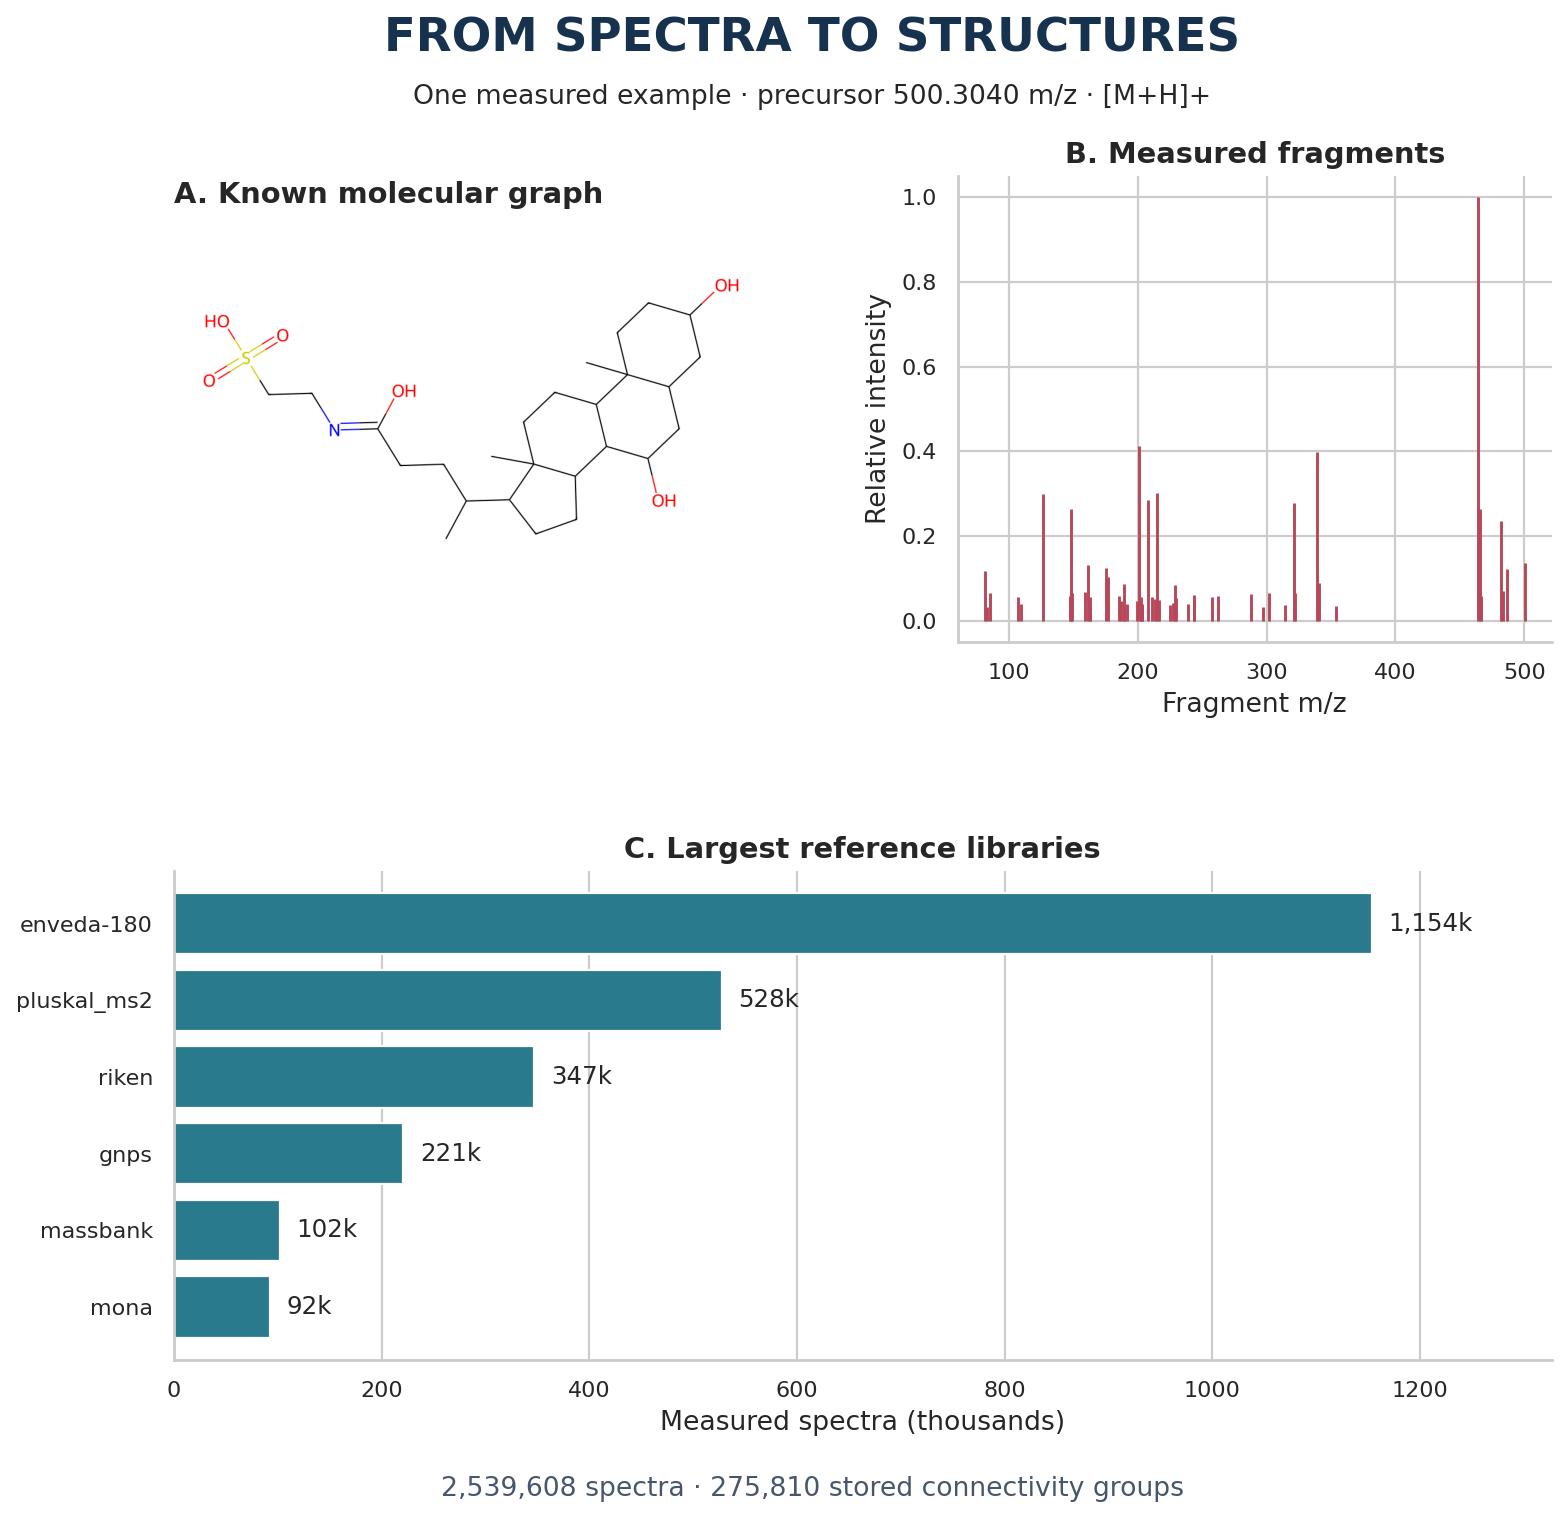

In [4]:
# The journal-style header is assembled from measured competition data.
header_columns = ["normalized_smiles", "ms2_mzs", "ms2_normalized_intensities", "adduct", "precursor_mz"]
preview_pool = pq.ParquetFile(TRAIN_PATH).read_row_group(0, columns=header_columns).slice(0, 700).to_pandas()
preview_pool["mol"] = preview_pool["normalized_smiles"].map(Chem.MolFromSmiles)
preview_pool["heavy_atoms"] = preview_pool["mol"].map(lambda x: x.GetNumHeavyAtoms() if x is not None else 0)
preview_pool["peaks"] = preview_pool["ms2_mzs"].str.len()
eligible = preview_pool.query("16 <= heavy_atoms <= 34 and peaks >= 35")
preview = eligible.sort_values(["peaks", "heavy_atoms"], ascending=False).iloc[0]
mol = preview["mol"]
mol_image = Draw.MolToImage(mol, size=(1000, 650), fitImage=True)
mz = np.asarray(preview["ms2_mzs"], dtype=float)
intensity = np.asarray(preview["ms2_normalized_intensities"], dtype=float)
top = np.argsort(intensity)[-55:]
header_meta = pd.read_parquet(TRAIN_PATH, columns=["ingest_lib", "inchikey14"])
header_connectivities = header_meta["inchikey14"].nunique()
source_counts = header_meta["ingest_lib"].value_counts().head(6).sort_values()
del header_meta

fig = plt.figure(figsize=(10.5, 10.0), facecolor='white')
grid = fig.add_gridspec(2, 2, height_ratios=[1, 1.05], hspace=.48, wspace=.32,
                       left=.12, right=.94, bottom=.12, top=.86)
ax0, ax1, ax2 = fig.add_subplot(grid[0,0]), fig.add_subplot(grid[0,1]), fig.add_subplot(grid[1,:])
ax0.imshow(mol_image); ax0.axis('off'); ax0.set_title('A. Known molecular graph', loc='left')
ax1.vlines(mz[top], 0, intensity[top], color='#b74759', linewidth=1.3)
ax1.set(xlabel='Fragment m/z', ylabel='Relative intensity', title='B. Measured fragments')
ax2.barh(source_counts.index, source_counts.values / 1e3, color='#287a8c')
ax2.set(xlabel='Measured spectra (thousands)', title='C. Largest reference libraries')
ax2.set_xlim(0, source_counts.max()/1e3*1.15)
ax2.grid(axis='y', visible=False)
for y, value in enumerate(source_counts.values):
    ax2.text(value/1e3 + source_counts.max()/1e3*.014, y, f'{value/1e3:,.0f}k', va='center', fontsize=11)
fig.suptitle('FROM SPECTRA TO STRUCTURES', fontsize=21, weight='bold', color='#16324f', y=.96)
fig.text(.5,.905, f"One measured example · precursor {preview['precursor_mz']:.4f} m/z · {preview['adduct']}", ha='center', fontsize=12)
fig.text(.5,.035, f"{pq.ParquetFile(TRAIN_PATH).metadata.num_rows:,} spectra · {header_connectivities:,} stored connectivity groups", ha='center', fontsize=12, color='#46566b')
plt.show()


*Figure 1. Graphical abstract built from the competition corpus. A labelled molecular graph, its measured fragment spectrum, and the scale of the largest source libraries frame the central task: rank molecular connectivities from MS/MS evidence.*

## Abstract

Precursor mass can eliminate many impossible structures, yet several candidates can share nearly the same mass. The corpus contains millions of measured spectra and repeated acquisitions of many molecules, so the central task is to connect those fragment patterns to an ordered candidate list. This notebook shows how source coverage sets the ceiling for ranking accuracy, then runs an attributed public method that searches training and COCONUT structures, ranks them with spectral and molecular features, tests a bounded set of isomers with predicted fragments, and adds new PubChem proposals through a fixed rule.

The executable method follows [Ahmed Berat Özer's public v4g inference notebook](https://www.kaggle.com/code/ahmedberatozer/casmi26-v4g-inference). Its source packages are preserved and described in the [attributed asset fork](https://www.kaggle.com/datasets/dmitriigluzdov/casmi26-attributed-v4g-reproduction-assets). Version 17 of this notebook achieved **0.366 public MRR@25**. This revision adds the GLACIER forward-spectrum channel from the [public v4h method](https://www.kaggle.com/code/ahmedberatozer/casmi26-v4h-inference); its own score must be measured by an accepted Code submission. Earlier results are recorded in Appendix A. Section 11 explains how to run a stronger identity-disjoint local test before claiming a generalisation improvement.

## 1. From a molecule to a spectrum — and back to SMILES

The input is a collection of tandem mass spectra. The output is an ordered list of molecular graphs written as **SMILES** (Simplified Molecular Input Line Entry System). Figure 2 separates the laboratory experiment from the computational inverse problem.

### The forward experiment

1. **LC (liquid chromatography)** separates a mixture over time.
2. **ESI (electrospray ionisation)** creates gas-phase ions. A molecule may acquire a proton (`[M+H]+`), lose one (`[M-H]-`), or bind another charged species. The **adduct** describes the measured ion form.
3. **MS1** measures the precursor ion's mass-to-charge ratio, **m/z**. Given its adduct and charge, this constrains neutral monoisotopic mass: the mass of the uncharged formula calculated with each element's most abundant isotope. Different connectivities can still share the same formula and exact mass.
4. The instrument isolates a precursor window and activates the ions through collisions. **CID (collision-induced dissociation)** produces fragments; collision energy affects which fragments survive and their relative abundance.
5. **MS2 (MS/MS)** records the fragment m/z values and intensities. In a spectrum plot, each vertical peak marks a fragment m/z and its height shows intensity; Figure 11 later shows measured examples. The **base peak** is the most intense peak. A precursor-to-fragment mass difference can suggest a **neutral loss**, provided the charge and ion chemistry are consistent.

An illustrative loss of about 18.0106 daltons (Da, a molecular-scale mass unit) can be consistent with water, but one loss does not identify a molecule. Several structures can undergo it, and rearrangements complicate a direct bond-by-bond interpretation. Useful evidence is the pattern of compatible fragments and losses across the available spectra.

### The inverse problem

`spectra + acquisition metadata → mass-compatible structures → spectral and analogue evidence → ranked candidates`

One structure can produce different spectra across adducts, energies, and instruments. Conversely, different structures can produce similar spectra. Reference matching is therefore strongest when supported by mass agreement and multiple informative peaks. A structure without its own reference spectrum needs indirect evidence, such as related compounds, predicted fingerprints, or simulated fragments. A structure absent from the candidate database requires a generator to propose it.

[CSI:FingerID](https://www.pnas.org/doi/10.1073/pnas.1509788112) and [MIST](https://www.nature.com/articles/s42256-023-00708-3) predict fingerprints that help rank database structures; [MSNovelist](https://www.nature.com/articles/s41592-022-01486-3) generates structures de novo; [MassSpecGym](https://github.com/pluskal-lab/MassSpecGym) provides evaluation tasks for both settings. These are background examples, not models run here: this notebook ranks database structures and has no de novo generator.


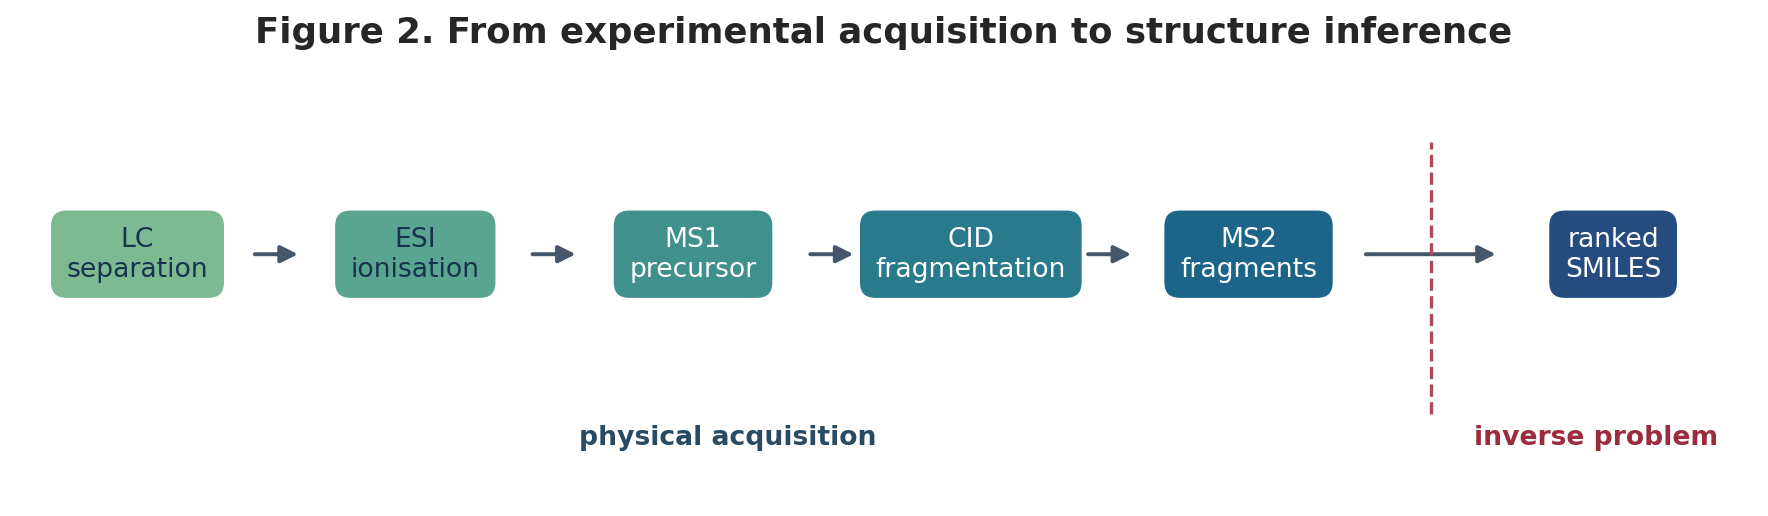

In [5]:

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.set(xlim=(0, 1), ylim=(0, 1)); ax.axis("off")
steps = [(0.07,"LC\nseparation"),(0.23,"ESI\nionisation"),(0.39,"MS1\nprecursor"),
         (0.55,"CID\nfragmentation"),(0.71,"MS2\nfragments"),(0.92,"ranked\nSMILES")]
colors = sns.color_palette("crest", len(steps))
for i_step, ((x, label), color) in enumerate(zip(steps, colors)):
    ax.text(x, .57, label, ha="center", va="center", fontsize=12, color="white" if i_step >= 2 else "#16324f", zorder=3,
            bbox=dict(boxstyle="round,pad=.65", fc=color, ec="white", lw=1.5))
    if i_step < len(steps)-1:
        next_x = steps[i_step+1][0]
        ax.annotate("", xy=(next_x-.065,.57), xytext=(x+.065,.57), zorder=2,
                    arrowprops=dict(arrowstyle="-|>", mutation_scale=16, lw=1.8, color="#46566b"))
ax.axvline(.815, ymin=.20, ymax=.83, color="#b04a5a", ls="--", lw=1.5)
ax.text(.41,.13,"physical acquisition",ha="center",fontsize=12,color="#284b63",weight="bold")
ax.text(.91,.13,"inverse problem",ha="center",fontsize=12,color="#9b2c3b",weight="bold")
ax.set_title("Figure 2. From experimental acquisition to structure inference", pad=12, fontsize=16)
plt.show()


*Figure 2. From experimental acquisition to structure inference. MS1 characterises precursor ions; an isolation step selects a precursor window for fragmentation; MS2 records the resulting spectrum. The computational task begins with these measurements and ends with ranked molecular structures.*


## 2. What earns a correct prediction?

Submit one ranked list per **`molecule_id`**, combining all its spectra. The [official evaluation](https://www.kaggle.com/competitions/enveda-CASMI26-molecule-id-mass-spectra/overview) uses **mean reciprocal rank among the first 25 guesses (MRR@25)**:

$$
\operatorname{MRR@25}=\frac{1}{U}\sum_{u=1}^{U}
\begin{cases}
1/r_u, & \text{if the first correct candidate has rank }r_u\leq25,\\
0, & \text{if it is absent from the first 25.}
\end{cases}
$$

For $U$ molecules, every molecule has equal weight regardless of how many spectra it has. Rank 1 contributes 1, rank 2 contributes 0.5, and rank 25 contributes 0.04.

The scorer uses **RDKit 2026.03.3**, a chemistry software toolkit, to choose a standard representation among **tautomers** (structures differing mainly in proton and double-bond placement). It then compares the first 14 characters of an **InChIKey**, a compact structure identifier. That prefix represents the connectivity scored here. Stereochemical variants and tautomers that collapse under this procedure do not need separate guesses. Export up to 25 best-first SMILES, separated by semicolons, in `molecule_id,smiles` columns.

Two modelling consequences follow: get the correct connectivity into the pool, then move it upward. Repeating an equivalent structure consumes a rank without adding coverage. A chemically similar analogue receives no partial credit.


### The visible sample and the hidden task

The [official data description](https://www.kaggle.com/competitions/enveda-CASMI26-molecule-id-mass-spectra/data) distinguishes three novelty classes:

| Available evidence for the answer | Main route to a candidate | Main failure mode |
|---|---|---|
| Public reference spectrum | direct library search | acquisition differences or incorrect ranking |
| PubChem/COCONUT structure, no public spectrum | structure database plus indirect spectral evidence | missing candidate or weak discrimination among isomers |
| Novel structure, absent from PubChem | de novo structure proposal | the correct graph is never generated |

Class membership and proportions are hidden. The released test contains examples from training; its overlap, mass distribution, and retrieval success do not estimate the hidden novelty mixture.

The visible sample verifies file handling and notebook execution. For an offline estimate, keep complete molecules out of the reference library and training features before ranking them. Section 11 separates this execution check from a structure-disjoint accuracy estimate. Kaggle reruns the notebook against a hidden test file for its leaderboard score. The hidden answers and novelty-class mixture are unavailable here.


### Files used in this notebook

The [competition data](https://www.kaggle.com/competitions/enveda-CASMI26-molecule-id-mass-spectra/data) provide `train.parquet`, `test.parquet` and `sample_submission.csv`. A training row contains a measured spectrum and a known structure; several spectra can belong to one molecule. Kaggle [replaces the visible format example with hidden spectra](https://www.kaggle.com/competitions/enveda-CASMI26-molecule-id-mass-spectra/discussion/741404) when scoring an accepted Code submission. The output is one ranked list of up to 25 SMILES per molecule ID.

The active [CASMI26 attributed v4g resource fork](https://www.kaggle.com/datasets/dmitriigluzdov/casmi26-attributed-v4g-reproduction-assets) preserves five public source packages as 134 hash-pinned files. Its card gives their original links, exact roles, file layout and mixed component terms. The notebook checks every input hash and restores original paths with symlinks, so the large NumPy arrays remain memory-mapped in Kaggle Input.

| Package in the fork | What it supplies | Interpretation |
|---|---|---|
| `v2_pool` | 710,701 structure rows, fragments and fingerprint arrays | Train-derived and COCONUT candidate structures; the measured reference spectra come from the separately mounted competition training file. |
| `v3_models` | Earlier code and FPNet A+B weights | An isolated PubChem proposal channel; its package does not replace the main engine. |
| `v4b` | Main engine, FPNet A, `fe_v4` features and a four-booster LightGBM ranker | Pretrained candidate scoring; this notebook does not fit the checkpoints. |
| `pubchem_tier` | Mass-sorted PubChem structure arrays | A second, structure-only candidate universe; its entries are not measured reference spectra. |
| `iceberg` | Forward-spectrum code, checkpoints and offline wheels | Optional bounded same-formula reranking for covered positive-mode spectra. |

The attached [Open Model and Candidate Resources](https://www.kaggle.com/datasets/dmitriigluzdov/casmi26-open-model-and-candidate-resources) package supplies the pinned RDKit 2026.03.3 offline wheel. Earlier versions of this notebook used a different [FPNet and candidate catalogues](https://www.kaggle.com/datasets/dmitriigluzdov/casmi26-open-fpnet-and-candidate-catalogues) package; its PubChemLite and ChEBI arrays are **not** attached or used here. Section 14 names other resources as further reading.

The five upstream datasets have Kaggle `Other` terms with component-specific restrictions. The fork preserves source notices and does not relicense their weights or competition-derived data. See its `SOURCE-LICENSES.md` before reuse beyond this non-commercial competition workflow.

The new [GLACIER package](https://www.kaggle.com/datasets/ahmedberatozer/casmi26-glacier) is attached separately. It provides a MassSpecGym-trained forward-spectrum checkpoint and offline inference code, reusing ICEBERG's isolated dependencies. Its `LICENSE-NOTICE.txt` explains the MIT source and the uploader's basis for using the checkpoint; Kaggle lists the package under **Other** terms. This package supplies predicted spectra, not new measured references or candidate structures.


## 3. File-level audit and schema

The first question is what a row represents. Here, a row is a **spectrum**, while the prediction target is a **molecule**. Several acquisitions can therefore support one answer.

`ingest_lib` identifies the source collection, `adduct` describes the measured ion, and `inchikey14` supplies a practical training-connectivity group. Keeping these roles separate prevents two common mistakes: counting repeated spectra as independent molecules and treating library provenance as if it were a molecular property. For example, a GNPS tag says where a spectrum came from, not which chemical class the molecule belongs to.


In [6]:
train_pf = pq.ParquetFile(TRAIN_PATH)
test_pf = pq.ParquetFile(TEST_PATH)

FIELD_MEANING = {
    "ingest_lib": "source spectral library", "normalized_smiles": "standardised molecular graph",
    "inchikey": "full hashed structure identifier", "inchikey14": "stored connectivity key for training grouping; scoring recomputes after tautomer canonicalisation",
    "molecular_formula": "elemental composition", "ionization_mode": "positive or negative ion polarity",
    "instrument_type": "mass-spectrometer family", "adduct": "normalised measured ion form",
    "adduct_orig": "ion form as supplied by the source", "precursor_mz": "selected precursor mass-to-charge ratio",
    "precursor_error_ppm": "precursor mass error in parts per million", "ms2_mzs": "fragment m/z array",
    "ms2_normalized_intensities": "base-peak-normalised fragment intensities", "num_peaks": "number of fragment peaks",
    "base_peak_intensity": "absolute intensity of the strongest peak", "collision_energy_ev": "collision energies mapped to eV",
    "collision_energy_orig": "source collision-energy text", "collision_energy_orig_units": "source energy unit",
    "molecule_id": "anonymous test-molecule group", "spectrum_id": "anonymous acquisition identifier",
}
FIELD_EXAMPLE = {"ingest_lib":"gnps", "normalized_smiles":"CC(=O)O", "inchikey14":"QTBSBXVTEAMEQO",
    "molecular_formula":"C2H4O2", "ionization_mode":"positive", "instrument_type":"timsTOF",
    "adduct":"[M+H]+", "precursor_mz":"375.0709", "precursor_error_ppm":"1.5",
    "num_peaks":"230", "collision_energy_ev":"[20, 40, 60]", "molecule_id":"m_005e53",
    "spectrum_id":"s_4d19d522"}

def schema_table(pf):
    schema = pf.schema_arrow
    return pd.DataFrame({"field": schema.names, "storage type": [str(x.type) for x in schema],
                         "experimental meaning": [FIELD_MEANING.get(x, "source metadata") for x in schema.names],
                         "example": [FIELD_EXAMPLE.get(x, "—") for x in schema.names]})

summary = pd.DataFrame([
    {"file": "train.parquet", "rows": train_pf.metadata.num_rows,
     "columns": train_pf.metadata.num_columns, "row_groups": train_pf.metadata.num_row_groups},
    {"file": "test.parquet", "rows": test_pf.metadata.num_rows,
     "columns": test_pf.metadata.num_columns, "row_groups": test_pf.metadata.num_row_groups},
])
display(Markdown("**Table 1. Physical layout of the competition files.**"))
display(summary.style.format({"rows": "{:,}"}))

display(Markdown("**Table 2. Field dictionary: storage, scientific meaning, and representative values.**"))
display(pd.concat({"train": schema_table(train_pf), "test": schema_table(test_pf)}, names=["file"]))

**Table 1. Physical layout of the competition files.**

,file,rows,columns,row_groups
0,train.parquet,"2,539,608",18,21
1,test.parquet,"1,213",12,1


**Table 2. Field dictionary: storage, scientific meaning, and representative values.**

field           storage type  \
file                                                           
train 0                    ingest_lib                 string   
      1             normalized_smiles                 string   
      2                      inchikey                 string   
      3                    inchikey14                 string   
      4             molecular_formula                 string   
      5               ionization_mode                 string   
      6               instrument_type                 string   
      7                        adduct                 string   
      8                   adduct_orig                 string   
      9                  precursor_mz                 double   
      10          precursor_error_ppm                 double   
      11                      ms2_mzs  list<element: double>   
      12   ms2_normalized_intensities  list<element: double>   
      13                    num_peaks                  int64   
      14          base_peak_intensity                 double   
      15          collision_energy_ev  list<element: double>   
      16        collision_energy_orig                 string   
      17  collision_energy_orig_units                 string   
test  0                   molecule_id           large_string   
      1                   spectrum_id           large_string   
      2                       ms2_mzs  list<element: double>   
      3    ms2_normalized_intensities  list<element: double>   
      4           base_peak_intensity                 double   
      5                        adduct           large_string   
      6               ionization_mode           large_string   
      7               instrument_type           large_string   
      8                  precursor_mz                 double   
      9         collision_energy_orig           large_string   
      10          collision_energy_ev  list<element: double>   
      11  collision_energy_orig_units           large_string   

                                                                                       experimental meaning  \
file                                                                                                          
train 0                                                                             source spectral library   
      1                                                                        standardised molecular graph   
      2                                                                    full hashed structure identifier   
      3   stored connectivity key for training grouping; scoring recomputes after tautomer canonicalisation   
      4                                                                               elemental composition   
      5                                                                   positive or negative ion polarity   
      6                                                                            mass-spectrometer family   
      7                                                                        normalised measured ion form   
      8                                                                  ion form as supplied by the source   
      9                                                             selected precursor mass-to-charge ratio   
      10                                                          precursor mass error in parts per million   
      11                                                                                 fragment m/z array   
      12                                                          base-peak-normalised fragment intensities   
      13                                                                           number of fragment peaks   
      14                                                           absolute intensity of the strongest peak   
      15                                                                    collision energies m

*Tables 1–2. File layout and field dictionary. Table 1 establishes dataset scale. Table 2 translates storage fields into experimental meaning and gives a concrete value where useful.*

**Read the schema before making joins.** Training carries molecular labels and source metadata; test carries anonymous `molecule_id` and `spectrum_id` values. Shared measurement fields use the same names, but the complete column sets differ. In particular, the training file has no test-style molecule ID, so its connectivity key is used for grouping.

The paired arrays `ms2_mzs` and `ms2_normalized_intensities` hold each spectrum. Their lengths must agree, and every element must remain paired during filtering or sorting. The remaining fields describe acquisition conditions, provenance, or labels; they are not all available as test-time features.


In [7]:
TRAIN_SCALAR_COLS = [
    "ingest_lib", "normalized_smiles", "inchikey", "inchikey14", "molecular_formula",
    "ionization_mode", "instrument_type", "adduct", "adduct_orig", "precursor_mz",
    "precursor_error_ppm", "num_peaks", "base_peak_intensity",
    "collision_energy_orig", "collision_energy_orig_units",
]

# The two peak arrays dominate disk volume. Scalar metadata is enough for most EDA and keeps memory bounded.
train = pd.read_parquet(TRAIN_PATH, columns=TRAIN_SCALAR_COLS)
test = pd.read_parquet(TEST_PATH)
sample = pd.read_csv(SAMPLE_PATH)

assert test["spectrum_id"].is_unique
assert sample["molecule_id"].is_unique
assert set(test["molecule_id"]) == set(sample["molecule_id"])

test_peak_counts = test["ms2_mzs"].str.len()
alignment_ok = test_peak_counts.eq(test["ms2_normalized_intensities"].str.len())
normalisation_ok = test["ms2_normalized_intensities"].map(lambda x: len(x) > 0 and np.isclose(np.max(x), 1.0))
sorted_ok = test["ms2_mzs"].map(lambda x: np.all(np.diff(x) >= 0))

audit = pd.Series({
    "train spectra (rows)": len(train),
    "train unique SMILES labels": train["normalized_smiles"].nunique(),
    "train unique stored InChIKey14 groups": train["inchikey14"].nunique(),
    "train unique molecular formulae": train["molecular_formula"].nunique(),
    "visible-test spectra": len(test),
    "visible-test molecules": test["molecule_id"].nunique(),
    "sample-submission rows": len(sample),
    "test peak arrays aligned": int(alignment_ok.sum()),
    "test spectra base-peak normalised": int(normalisation_ok.sum()),
    "test m/z arrays sorted": int(sorted_ok.sum()),
}, name="value")
display(Markdown("**Table 3. Dataset integrity and label cardinality.**"))
display(audit.to_frame().style.format({"value": "{:,}"}))

**Table 3. Dataset integrity and label cardinality.**

,value
train spectra (rows),"2,539,608"
train unique SMILES labels,"277,566"
train unique stored InChIKey14 groups,"275,810"
train unique molecular formulae,"51,291"
visible-test spectra,"1,213"
visible-test molecules,400
sample-submission rows,400
test peak arrays aligned,"1,213"
test spectra base-peak normalised,"1,213"
test m/z arrays sorted,"1,213"


*Table 3. File integrity and label cardinality. Counts distinguish spectra from training connectivities. Peak-array checks describe the mounted test file and should be rerun whenever that file changes.*


Two SMILES strings can describe structures that the evaluator treats as the same answer. The evaluator first canonicalises the tautomer and then derives a 14-character connectivity key. A file's stored `inchikey14` may differ from that recomputed key, so joins used for modelling and leakage-safe validation must use the scorer-compatible key. The stored field is still useful for the preliminary file counts above; those counts are not scorer-normalised.


## 4. Visible test: molecules, spectra, adducts, and quality

The released visible test is a **format example**: its molecule groups, acquisition settings and peak arrays show what the model must accept, but there are no structure answers here. Molecule groups differ in how much evidence they provide. Repeated acquisitions can vary in energy, adduct or ionisation polarity. They are complementary views of one target, not additional targets.

Figure 3 shows one group of spectra. Figure 4 counts acquisitions per `molecule_id` and shows the range of spectrum sizes. A richer peak list offers more possible clues, although extra peaks can also reflect noise or co-isolation (other ions entering the precursor isolation window alongside the target).

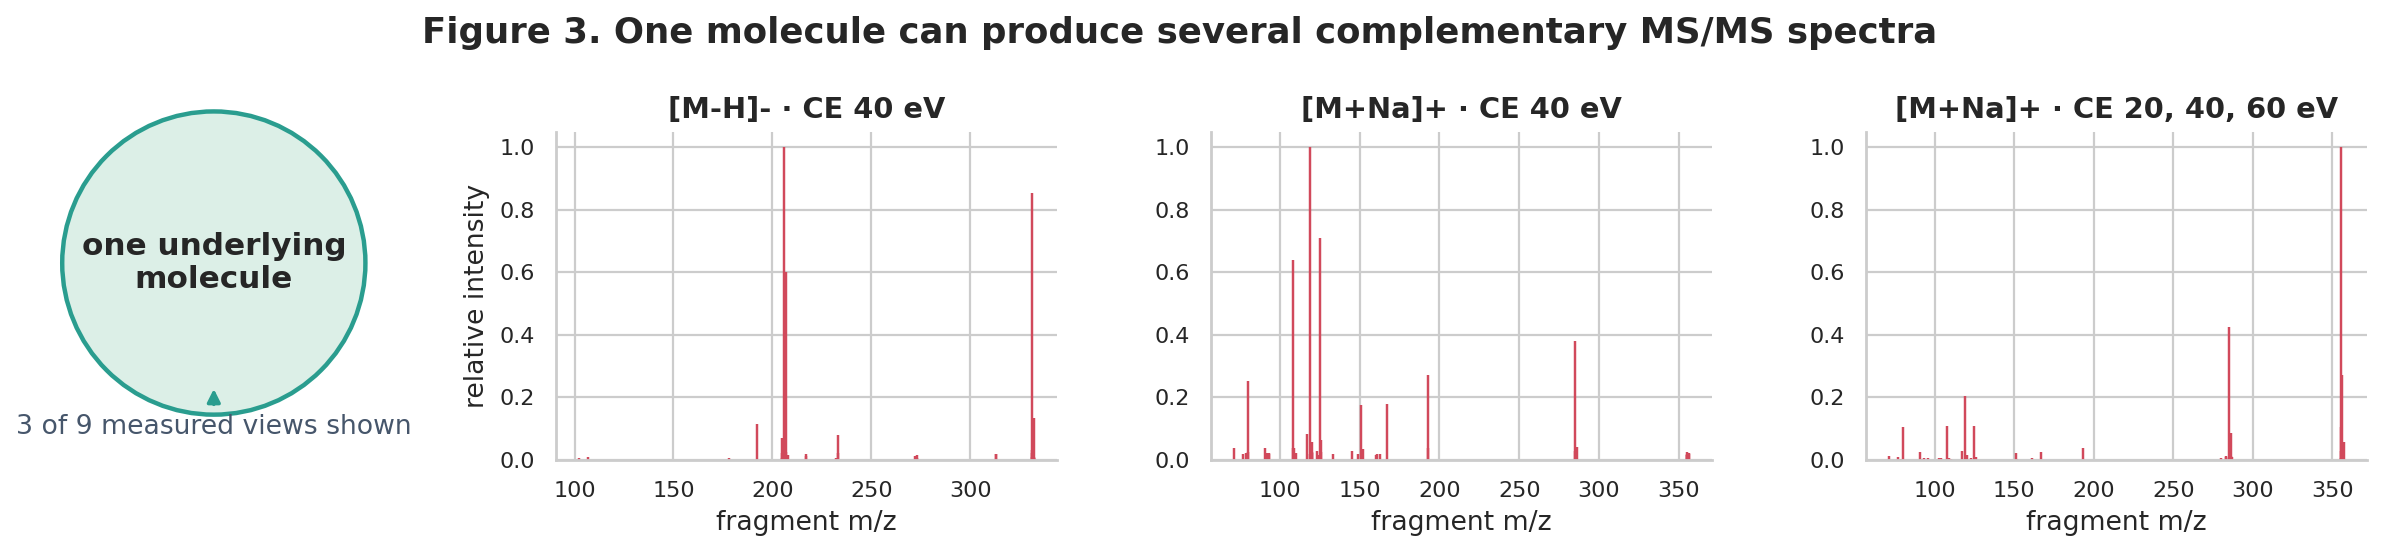

In [8]:
full_example_group = max((group for _, group in test.groupby("molecule_id", sort=False)), key=len)
example_group = full_example_group.head(3)
n_views = len(example_group)
fig, axes = plt.subplots(1, n_views + 1, figsize=(5 + 3.4 * n_views, 3.5),
                         gridspec_kw={"width_ratios":[.75] + [1] * n_views})
axes = np.atleast_1d(axes)
axes[0].axis("off")
axes[0].text(.5, .60, "one underlying\nmolecule", ha="center", va="center", fontsize=14, weight="bold",
             bbox=dict(boxstyle="circle,pad=.62", fc="#dcefe7", ec="#2a9d8f", lw=2))
axes[0].annotate(f"{n_views} of {len(full_example_group)} measured views shown", xy=(.50,.23), xytext=(.50,.08), ha="center", color="#46566b",
                 arrowprops=dict(arrowstyle="-|>", color="#2a9d8f", lw=1.6))
for ax, (_, row) in zip(axes[1:], example_group.iterrows()):
    mz = np.asarray(row["ms2_mzs"], dtype=float); intensity = np.asarray(row["ms2_normalized_intensities"], dtype=float)
    keep = np.argsort(intensity)[-45:]
    ax.vlines(mz[keep], 0, intensity[keep], color="#d1495b", lw=1.1)
    energy_values = np.atleast_1d(np.asarray(row["collision_energy_ev"], dtype=float))
    energy = ", ".join(f"{x:g}" for x in energy_values)
    ax.set(title=f"{row['adduct']} · CE {energy} eV", xlabel="fragment m/z", ylim=(0,1.05))
    ax.spines[["top","right"]].set_visible(False)
axes[1].set_ylabel("relative intensity")
fig.suptitle("Figure 3. One molecule can produce several complementary MS/MS spectra", fontsize=16, weight="bold")
plt.tight_layout()
plt.show()

*Figure 3. Multiple acquisitions assigned to one molecule. The underlying molecular identity is shared; the measured precursor ion and fragment pattern can change with adduct and acquisition conditions. The output is one ranked list for the whole group.*


**Table 4. Replicate and peak-count summary for the visible test.**

,statistic,spectra per molecule,peak count
0,min,1.00,4.00
1,median,3.00,230.00
2,mean,3.03,330.34
3,max,9.00,3259.00


**Figure 4. Replication and spectral-complexity profile of the visible test.**

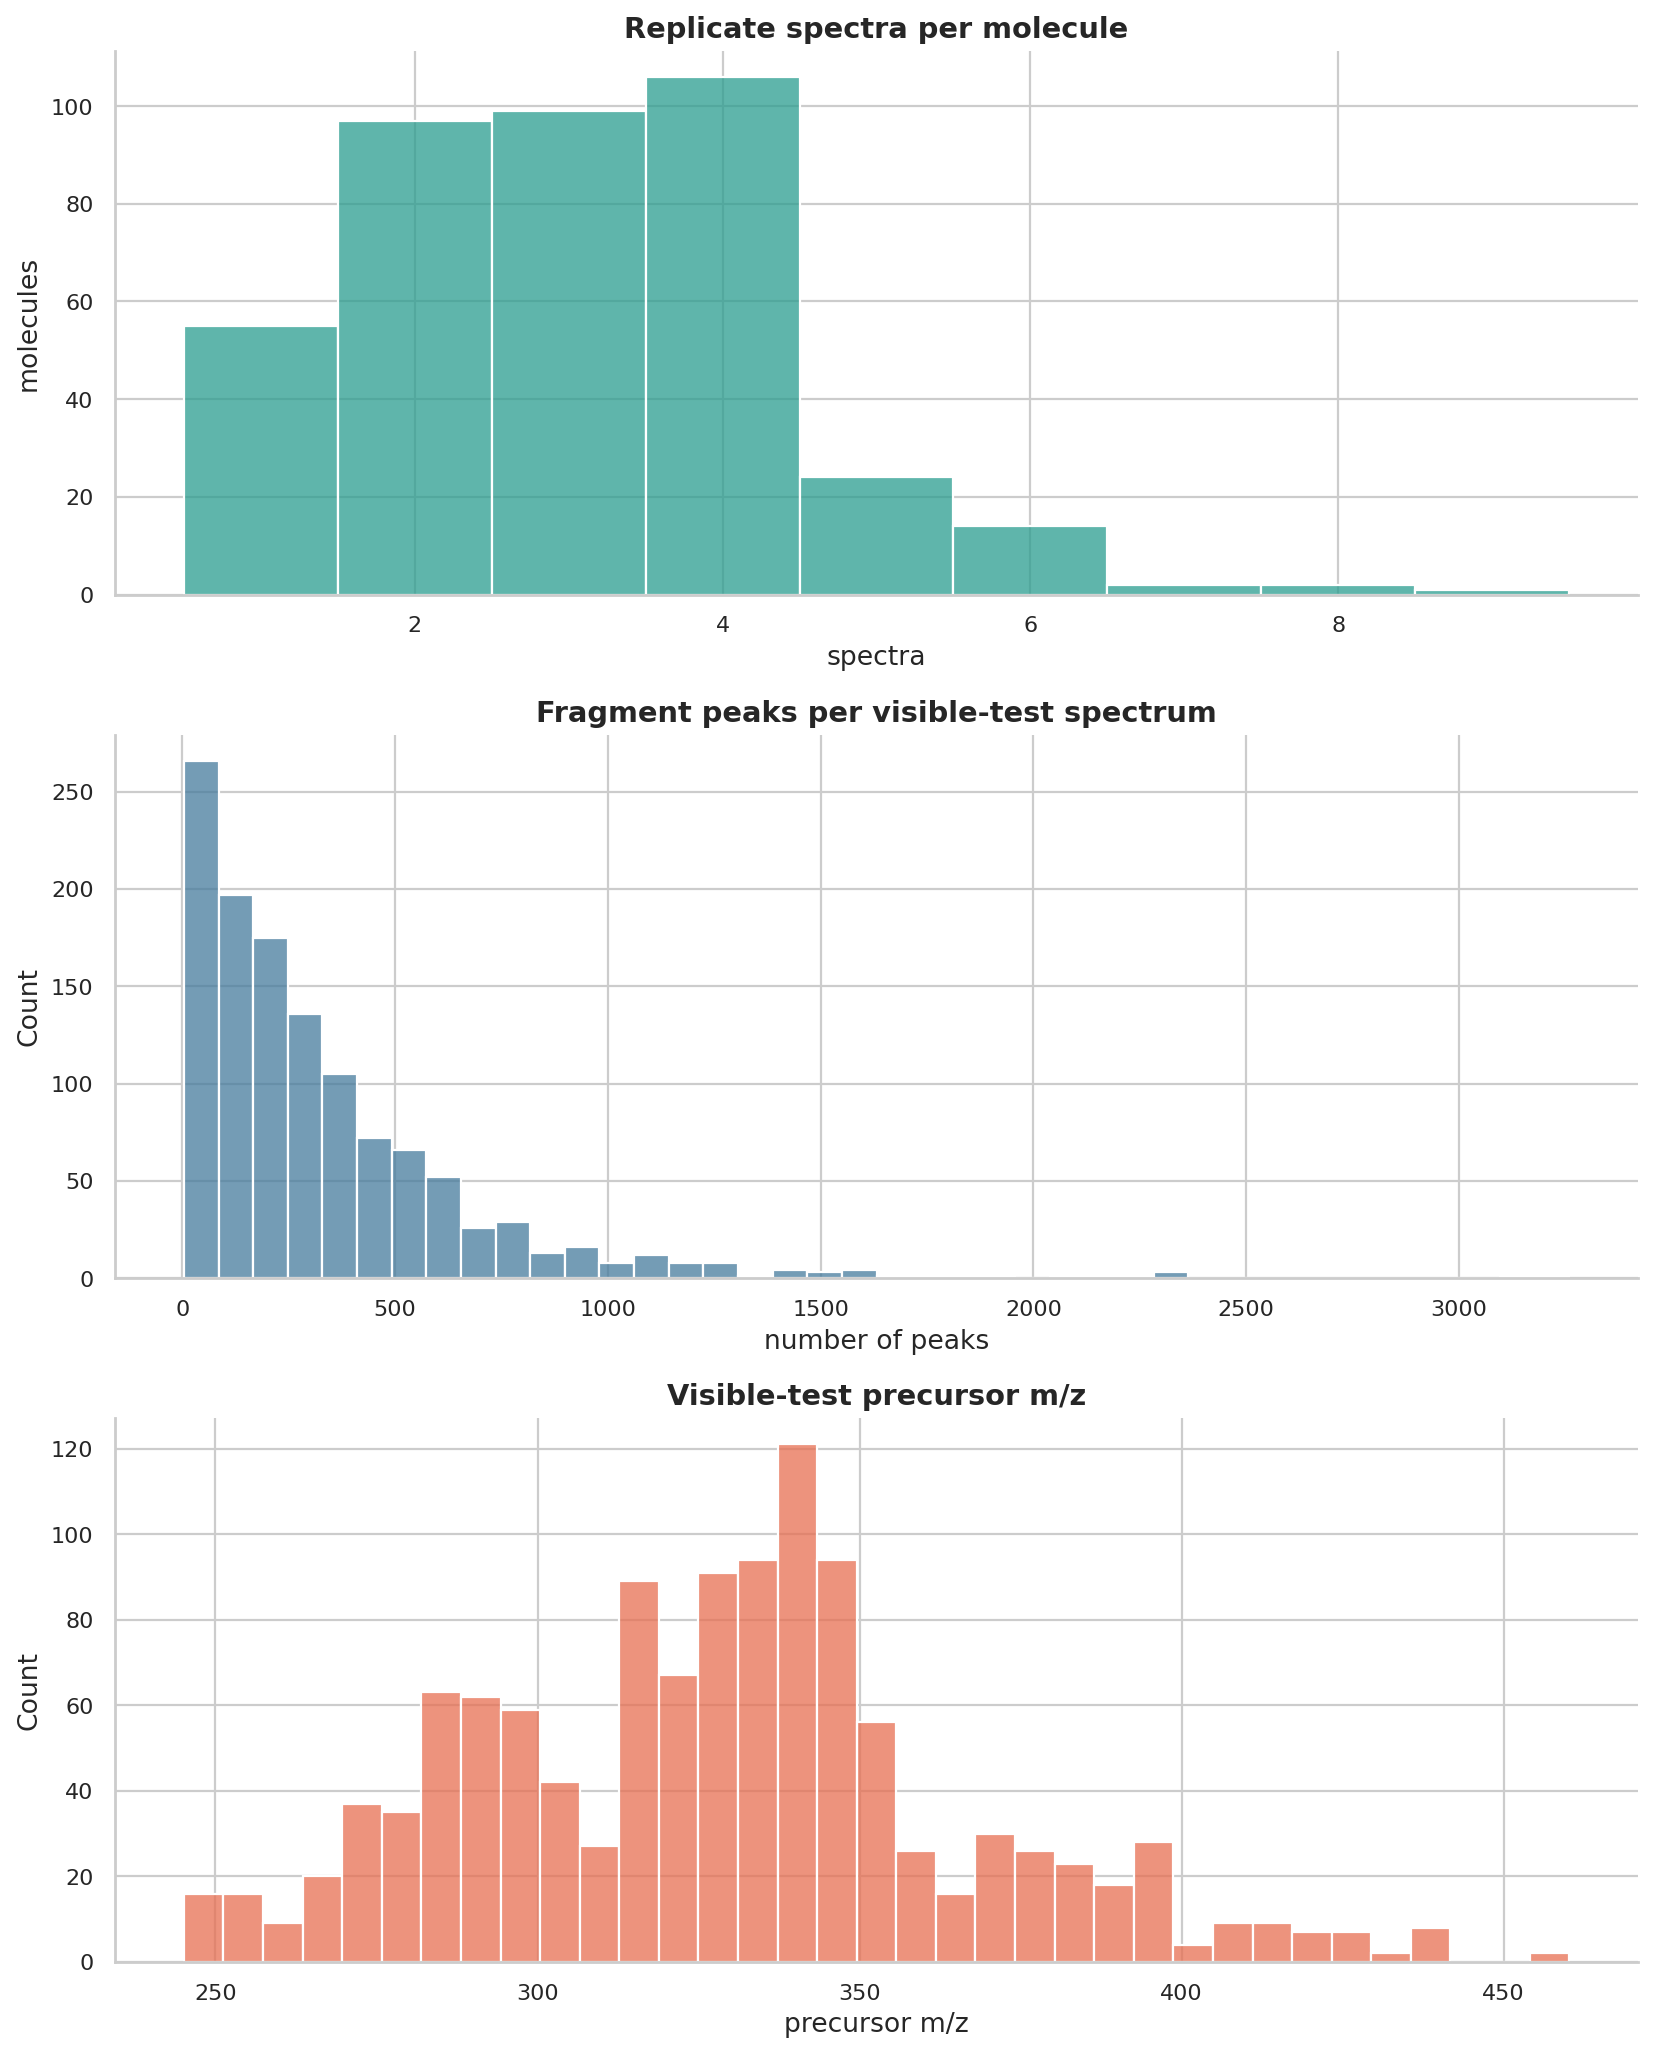

In [9]:
spectra_per_molecule = test.groupby("molecule_id").size()
test_summary = pd.DataFrame({
    "statistic": ["min", "median", "mean", "max"],
    "spectra per molecule": [spectra_per_molecule.min(), spectra_per_molecule.median(),
                              spectra_per_molecule.mean(), spectra_per_molecule.max()],
    "peak count": [test_peak_counts.min(), test_peak_counts.median(),
                   test_peak_counts.mean(), test_peak_counts.max()],
})
display(Markdown("**Table 4. Replicate and peak-count summary for the visible test.**"))
display(test_summary.style.format({"spectra per molecule": "{:.2f}", "peak count": "{:.2f}"}))

display(Markdown("**Figure 4. Replication and spectral-complexity profile of the visible test.**"))
fig, axes = plt.subplots(3, 1, figsize=(10.5, 13))
sns.histplot(spectra_per_molecule, discrete=True, ax=axes[0], color="#2a9d8f")
axes[0].set(title="Replicate spectra per molecule", xlabel="spectra", ylabel="molecules")
sns.histplot(test_peak_counts, bins=40, ax=axes[1], color="#457b9d")
axes[1].set(title="Fragment peaks per visible-test spectrum", xlabel="number of peaks")
sns.histplot(test["precursor_mz"], bins=35, ax=axes[2], color="#e76f51")
axes[2].set(title="Visible-test precursor m/z", xlabel="precursor m/z")
plt.tight_layout()
plt.show()

*Table 4 and Figure 4. Replication, peak counts, and precursor m/z in the mounted test file. The first panel counts separate acquisitions per molecule; the other panels describe individual spectra. These are sample observations, not fixed limits for inference.*


**Figure 5. Adduct and polarity composition of the visible test.**

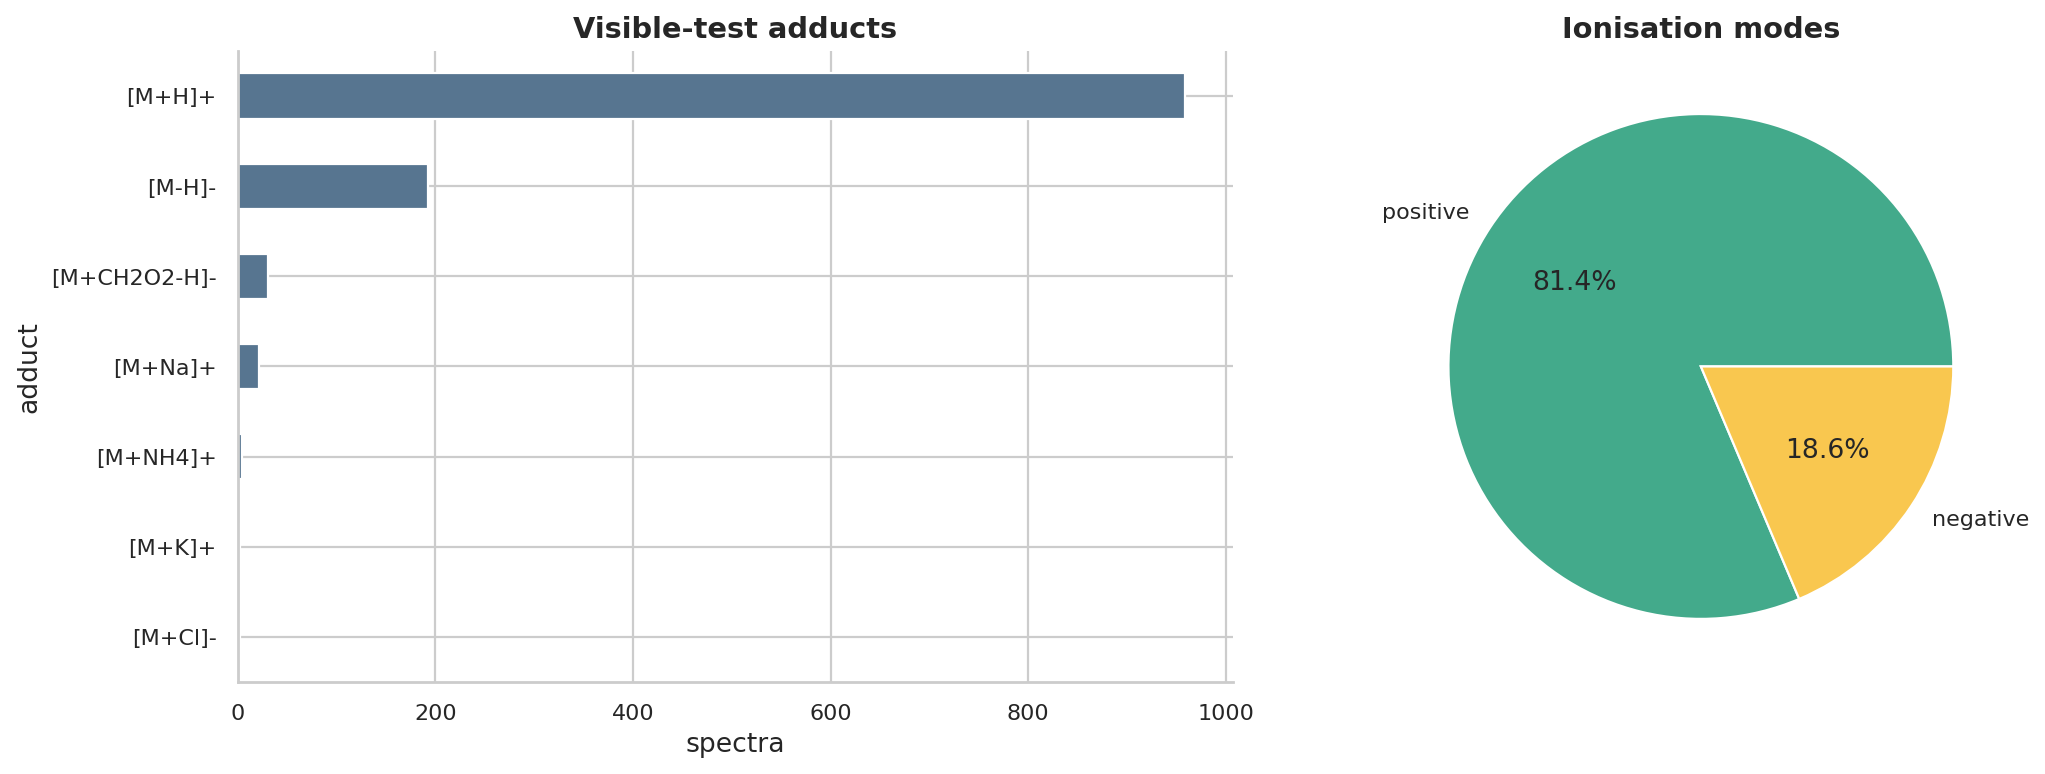

**Table 5. Cross-tabulation of normalised adduct and ionisation polarity.**

ionization_mode,negative,positive,All
adduct,,,
[M+CH2O2-H]-,31,0,31
[M+Cl]-,2,0,2
[M+H]+,0,959,959
[M+K]+,0,2,2
[M+NH4]+,0,4,4
[M+Na]+,0,22,22
[M-H]-,193,0,193
All,226,987,1213


In [10]:
display(Markdown("**Figure 5. Adduct and polarity composition of the visible test.**"))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
test["adduct"].value_counts().sort_values().plot.barh(ax=axes[0], color="#577590")
axes[0].set(title="Visible-test adducts", xlabel="spectra", ylabel="adduct")
test["ionization_mode"].value_counts().plot.pie(ax=axes[1], autopct="%1.1f%%",
                                                colors=["#43aa8b", "#f9c74f"])
axes[1].set(title="Ionisation modes", ylabel="")
plt.tight_layout()
plt.show()

display(Markdown("**Table 5. Cross-tabulation of normalised adduct and ionisation polarity.**"))
display(pd.crosstab(test["adduct"], test["ionization_mode"], margins=True))

*Figure 5 and Table 5. Ion forms in the visible test. Adduct and polarity determine the equation used to recover neutral molecular mass, so they constrain candidate generation before spectral ranking.*

Check Table 3's integrity counts before interpreting the adduct and polarity distributions in Figure 5. A well-formed array can still contain uninformative or contaminated peaks; format checks and chemical quality checks serve different purposes.

The organisers describe hidden molecules spanning **157–1,159 Da** in neutral monoisotopic mass and **1–16 spectra per molecule**, acquired on timsTOF. These published ranges provide context; the visible precursor-m/z histogram is a different quantity measured on a demonstration sample. For `[M+H]+`, the neutral mass subtracts a proton from the measured ion; sodium adducts and dimers need different offsets (Section 7). Inference should process every supplied group and adduct without assuming the visible sample's limits. [Official data description](https://www.kaggle.com/competitions/enveda-CASMI26-molecule-id-mass-spectra/data).

## 5. Training corpus: scale, provenance, and overlap

`ingest_lib` names source collections, not molecular classes. The training corpus includes experimental libraries such as [GNPS](https://ccms-ucsd.github.io/GNPSDocumentation/browselibraries/), [MassBank](https://github.com/MassBank/MassBank-data) and [MoNA](https://massbank.us/), Enveda acquisitions, and upstream labels such as RIKEN, MS-DIAL and `pluskal_ms2`. These collections overlap in chemistry but differ in instruments, processing and replication; Table 6 shows their actual labels and counts.

Table 6 asks two separate questions: which library contributes the most **spectra**, and which contributes the most **distinct stored InChIKey14 groups**? Their ratio measures replication. A large row count can mean broader chemistry, more repeated measurements, or both.

**Table 6. Spectra, stored InChIKey14 groups, and replication by source library.**

,collection,spectra,structures,spectra_per_structure
ingest_lib,,,,
enveda-180,"Enveda synthetic, instrument-matched collection","1,153,785","182,941",6.3
pluskal_ms2,Pluskal laboratory MS/MS compilation,"527,581","46,821",11.3
riken,RIKEN metabolomics / natural products,"347,171","15,892",21.8
gnps,Global Natural Products Social Molecular Networking,"220,849","45,750",4.8
massbank,curated public high-resolution spectra,"101,727","9,180",11.1
mona,MassBank of North America,"92,416","11,681",7.9
spectraverse,community spectrum repository,"50,933","9,631",5.3
msdial,MS-DIAL public library,"40,765","9,127",4.5
drug_plus,drug-like reference set,"2,545","2,539",1.0


**Figure 6. Relative scale of the source libraries.**

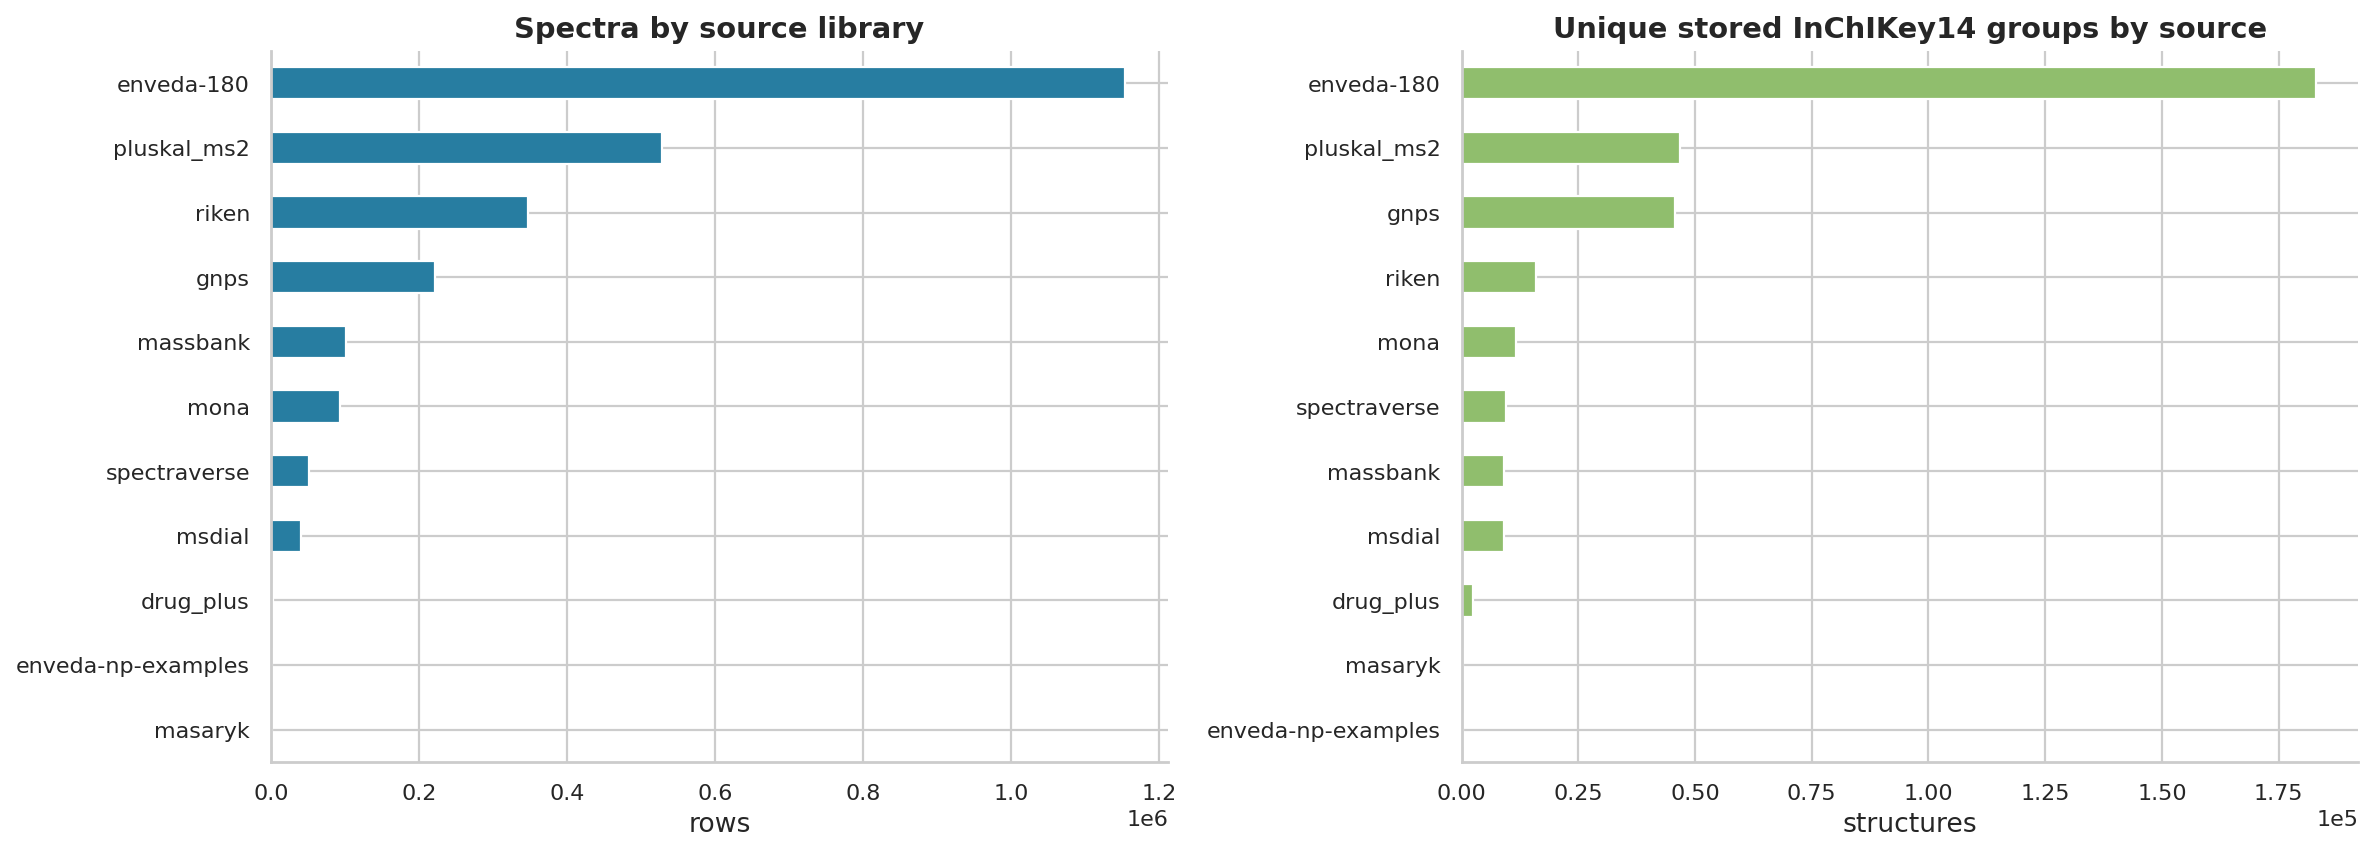

In [11]:
library_stats = (train.groupby("ingest_lib")
                 .agg(spectra=("inchikey14", "size"), structures=("inchikey14", "nunique"))
                 .sort_values("spectra", ascending=False))
library_stats["spectra_per_structure"] = library_stats["spectra"] / library_stats["structures"]
LIBRARY_DESCRIPTION = {"enveda-180":"Enveda synthetic, instrument-matched collection",
 "pluskal_ms2":"Pluskal laboratory MS/MS compilation", "riken":"RIKEN metabolomics / natural products",
 "gnps":"Global Natural Products Social Molecular Networking", "massbank":"curated public high-resolution spectra",
 "mona":"MassBank of North America", "spectraverse":"community spectrum repository",
 "msdial":"MS-DIAL public library", "drug_plus":"drug-like reference set",
 "enveda-np-examples":"organiser natural-product examples", "masaryk":"Masaryk University spectra"}
library_stats.insert(0, "collection", [LIBRARY_DESCRIPTION.get(x, "source collection") for x in library_stats.index])
display(Markdown("**Table 6. Spectra, stored InChIKey14 groups, and replication by source library.**"))
display(library_stats.style.format({
    "spectra": "{:,}", "structures": "{:,}", "spectra_per_structure": "{:.1f}"
}).background_gradient(subset=["spectra", "structures"], cmap="Blues"))

display(Markdown("**Figure 6. Relative scale of the source libraries.**"))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
library_stats.sort_values("spectra")["spectra"].plot.barh(ax=axes[0], color="#277da1")
axes[0].set(title="Spectra by source library", xlabel="rows", ylabel="")
library_stats.sort_values("structures")["structures"].plot.barh(ax=axes[1], color="#90be6d")
axes[1].set(title="Unique stored InChIKey14 groups by source", xlabel="structures", ylabel="")
for ax in axes:
    ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
plt.tight_layout()
plt.show()

*Table 6 and Figure 6. Training-library scale. `spectra` counts acquisitions; `structures` counts unique stored InChIKey14 groups; their ratio measures experimental replication.*

**Table 7. Spectra per stored InChIKey14 group (before scorer tautomer canonicalisation).**

,spectra_per_structure
count,275810.000000
mean,9.207817
std,21.069560
min,1.000000
25%,4.000000
50%,6.000000
75%,9.000000
90%,14.000000
95%,21.000000
99%,79.000000


**Figure 7. Replication depth and cross-library recurrence.**

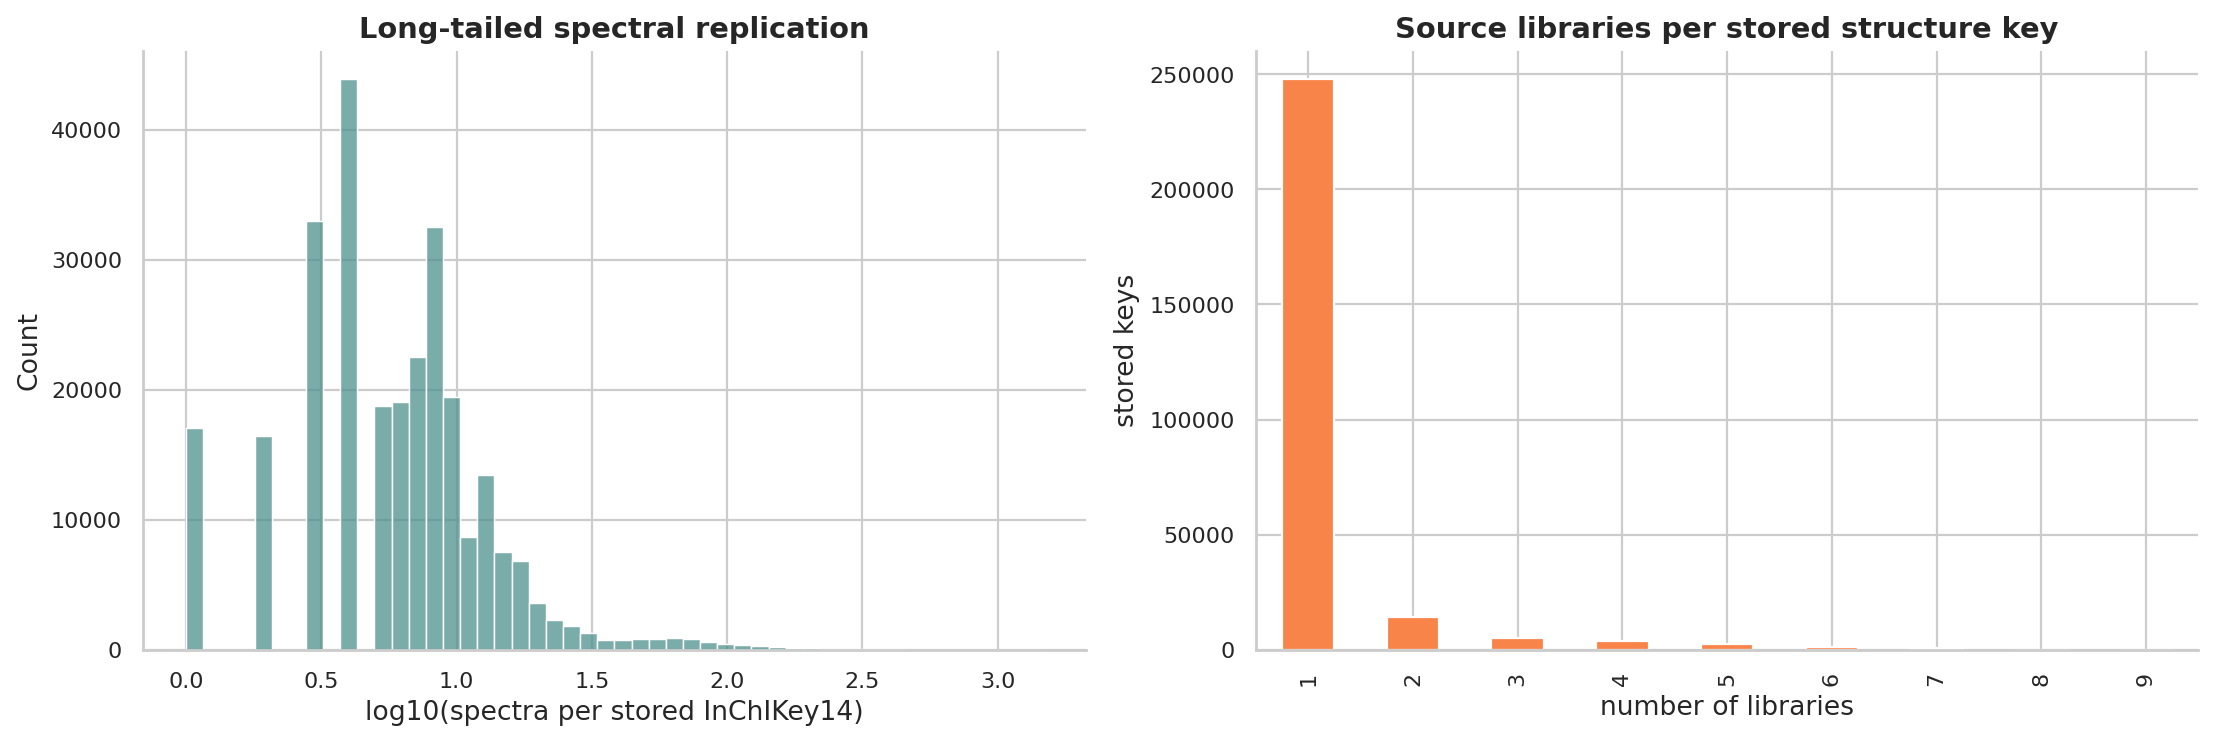

Stored InChIKey14 groups found in >1 source library: 28,113 (10.19%)


In [12]:
structure_repeats = train.groupby("inchikey14").size()
library_pairs = train[["inchikey14", "ingest_lib"]].drop_duplicates()
libraries_per_structure = library_pairs.groupby("inchikey14").size()

repeat_table = pd.DataFrame({
    "spectra_per_structure": structure_repeats.describe(percentiles=[.25, .5, .75, .9, .95, .99]),
})
display(Markdown("**Table 7. Spectra per stored InChIKey14 group (before scorer tautomer canonicalisation).**"))
display(repeat_table)

display(Markdown("**Figure 7. Replication depth and cross-library recurrence.**"))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.histplot(np.log10(structure_repeats), bins=50, ax=axes[0], color="#4d908e")
axes[0].set(title="Long-tailed spectral replication", xlabel="log10(spectra per stored InChIKey14)")
libraries_per_structure.value_counts().sort_index().plot.bar(ax=axes[1], color="#f9844a")
axes[1].set(title="Source libraries per stored structure key", xlabel="number of libraries", ylabel="stored keys")
plt.tight_layout()
plt.show()

multi_library = int((libraries_per_structure > 1).sum())
print(f"Stored InChIKey14 groups found in >1 source library: {multi_library:,} "
      f"({multi_library / len(libraries_per_structure):.2%})")

*Table 7 and Figure 7. Repeated measurements and cross-library overlap. A connectivity appearing in several sources may provide useful acquisition diversity, but provenance alone does not establish that all records are independent or correctly labelled.*


The long tail of spectra per connectivity explains why a random row split can be misleading. It may leave close replicas of a validation molecule in the search library. That is a useful test of **reference retrieval**, but an optimistic test of **generalisation to a molecule with no reference spectrum**.

In the measured corpus, `enveda-180` is the largest single source by spectrum count; it is not a majority of all rows. Instrument agreement also does not guarantee chemical-domain agreement. The smaller `enveda-np-examples` collection is used in the historical 48-molecule Enveda source-held-out replay in Appendix A. That replay retains frozen model artifacts and other-source structures, so it does not establish transfer to unseen chemistry. For a structure-disjoint test, all spectra of each held-out connectivity must be removed from every library, not just from the named source.


## 6. Missingness, label-quality signals, and outliers

Before filtering, distinguish missing metadata from suspicious measurements. A source can omit raw intensity while supplying a perfectly usable normalised spectrum. Conversely, a finite precursor mass can still conflict with the labelled structure and adduct.

Tables 8–10 expose these cases. The decision to remove a record should depend on the task, the source, and measured validation impact, rather than on how unusual its value looks in a global histogram.


**Table 8. Missing metadata by field.**

,missing_%
base_peak_intensity,45.80
collision_energy_orig,12.62
instrument_type,1.30
precursor_error_ppm,0.17
inchikey,0.00
normalized_smiles,0.00
ingest_lib,0.00
ionization_mode,0.00
molecular_formula,0.00
inchikey14,0.00


**Figure 8. Fields with incomplete training metadata.**

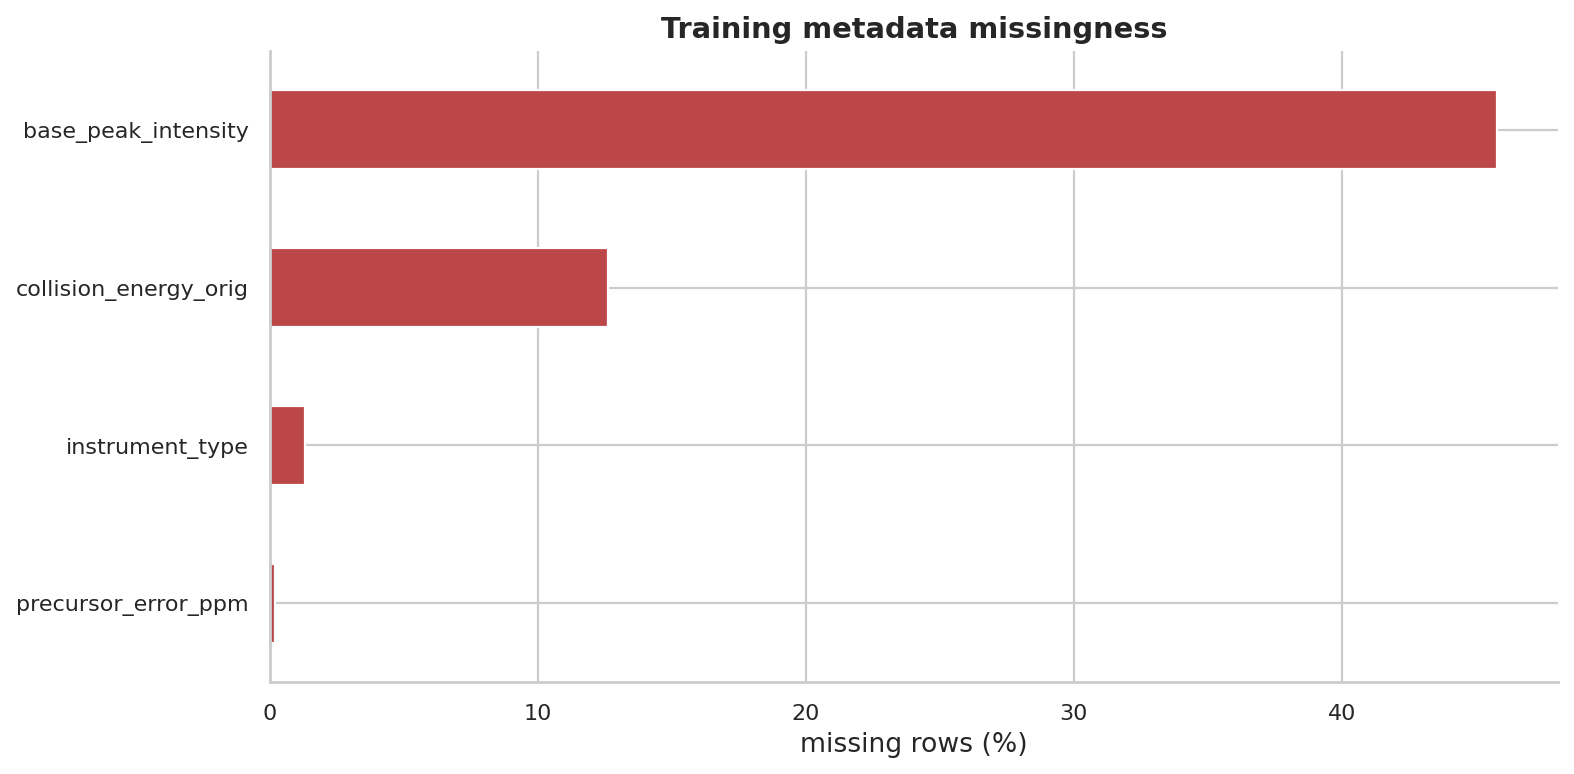

In [13]:
missing = (train.isna().mean().mul(100).sort_values(ascending=False).rename("missing_%"))
display(Markdown("**Table 8. Missing metadata by field.**"))
display(missing.to_frame().style.format("{:.2f}"))

display(Markdown("**Figure 8. Fields with incomplete training metadata.**"))
fig, ax = plt.subplots(figsize=(10, 5))
missing[missing > 0].sort_values().plot.barh(ax=ax, color="#bc4749")
ax.set(title="Training metadata missingness", xlabel="missing rows (%)", ylabel="")
plt.tight_layout()
plt.show()

*Table 8 and Figure 8. Missing metadata by field. The pattern identifies which inputs need explicit missing-value handling; it does not by itself establish whether the associated spectra are poor quality.*


In [14]:
numeric_summary = train[["precursor_mz", "precursor_error_ppm", "num_peaks", "base_peak_intensity"]].describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99]
).T
display(Markdown("**Table 9. Numerical metadata summary with robust quantiles.**"))
display(numeric_summary.style.format("{:.3g}"))

quality_counts = pd.Series({
    "|precursor error| > 5 ppm": train["precursor_error_ppm"].abs().gt(5).sum(),
    "|precursor error| > 20 ppm": train["precursor_error_ppm"].abs().gt(20).sum(),
    "precursor m/z > 2,000": train["precursor_mz"].gt(2000).sum(),
    "fewer than 5 peaks": train["num_peaks"].lt(5).sum(),
    "more than 2,000 peaks": train["num_peaks"].gt(2000).sum(),
}, name="rows")
display(Markdown("**Table 10. Explicit quality-control flags.**"))
display(quality_counts.to_frame().assign(percent=lambda x: 100*x["rows"]/len(train)).style.format({"rows": "{:,}", "percent": "{:.3f}%"}))

**Table 9. Numerical metadata summary with robust quantiles.**

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
precursor_mz,2.54e+06,420,1.54e+03,2,137,204,308,350,489,775,976,2.43e+06
precursor_error_ppm,2.54e+06,1.85e+03,5.12e+05,-21.1,0.03,0.154,0.776,1.51,2.35,17.2,2.88e+03,4.7e+08
num_peaks,2.54e+06,158,517,1,1,3,14,42,164,628,1.35e+03,7.33e+04
base_peak_intensity,1.38e+06,5.39e+06,5.3e+07,1,100,100,1.92e+04,1.76e+05,1.25e+06,1.67e+07,7.49e+07,8.93e+09


**Table 10. Explicit quality-control flags.**

,rows,percent
|precursor error| > 5 ppm,"254,782",10.032%
|precursor error| > 20 ppm,"119,514",4.706%
"precursor m/z > 2,000",25,0.001%
fewer than 5 peaks,"207,577",8.174%
"more than 2,000 peaks","10,690",0.421%


*Table 9 reports robust numerical ranges; Table 10 counts explicit quality flags. Together they separate the typical acquisition regime from records that deserve clipping, filtering, or dedicated validation.*

**Figure 9. Peak-count, precursor-error, and precursor-mass distributions.**

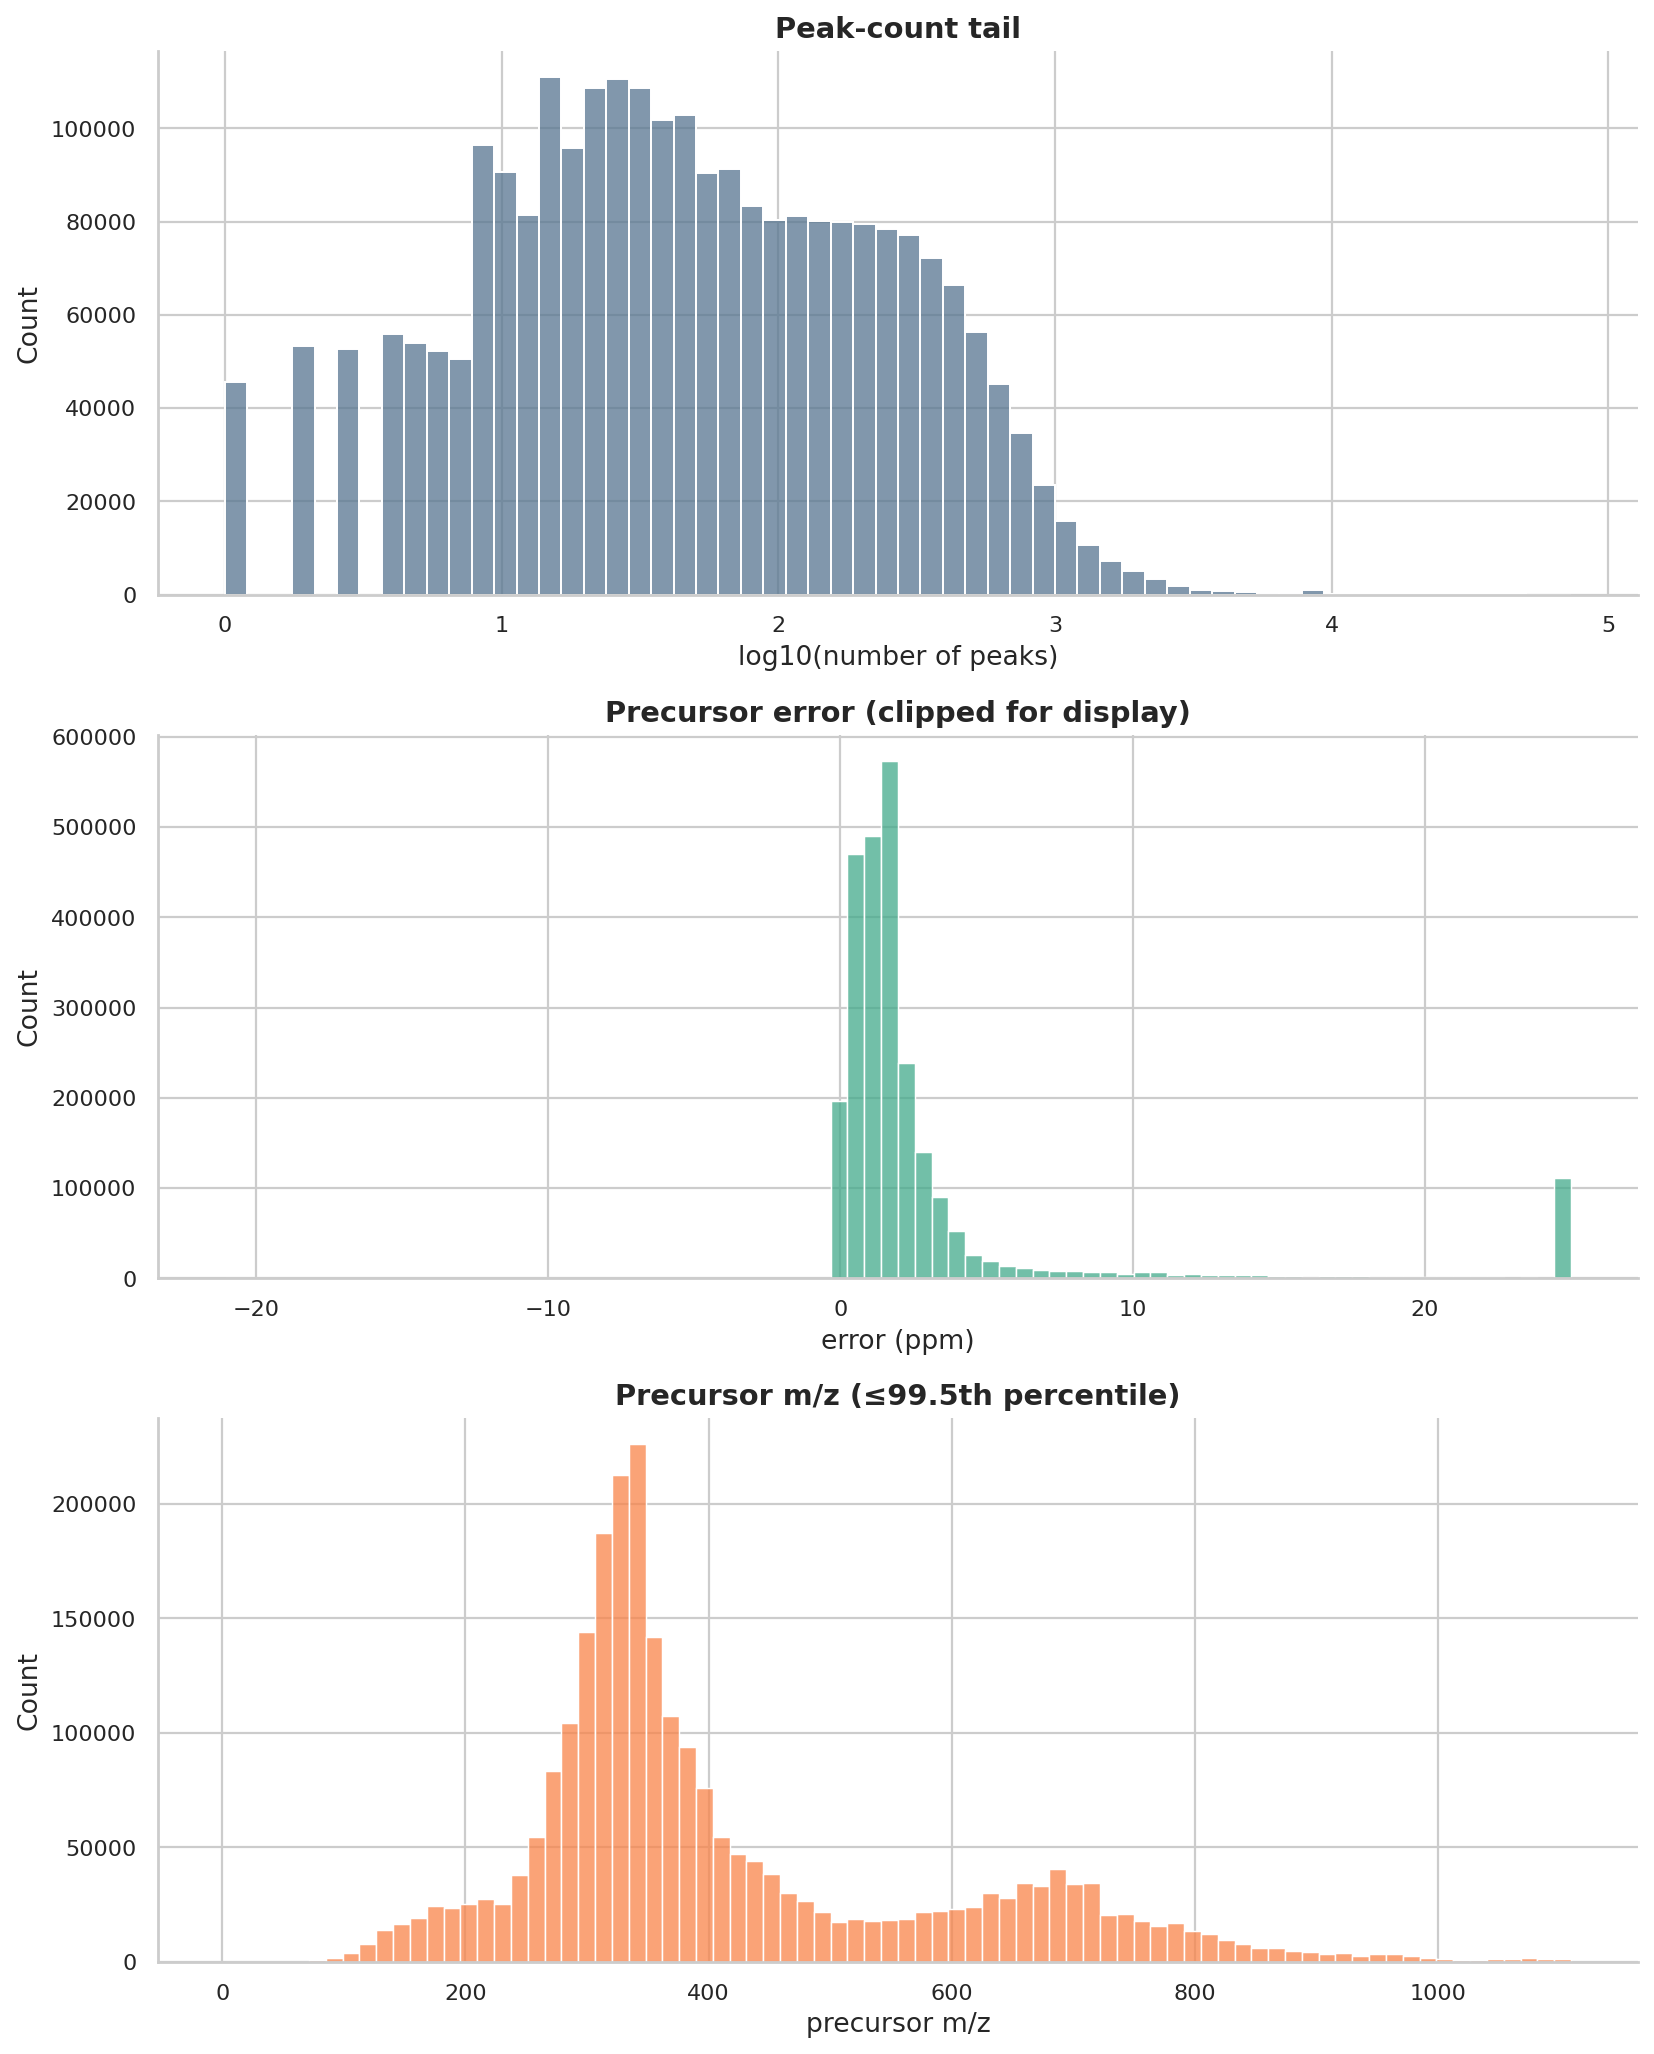

In [15]:
display(Markdown("**Figure 9. Peak-count, precursor-error, and precursor-mass distributions.**"))
fig, axes = plt.subplots(3, 1, figsize=(10.5, 13))
sns.histplot(np.log10(train["num_peaks"]), bins=60, ax=axes[0], color="#577590")
axes[0].set(title="Peak-count tail", xlabel="log10(number of peaks)")

ppm_clip = train["precursor_error_ppm"].dropna().clip(-25, 25)
sns.histplot(ppm_clip, bins=80, ax=axes[1], color="#43aa8b")
axes[1].set(title="Precursor error (clipped for display)", xlabel="error (ppm)")

mass_cap = train["precursor_mz"].quantile(.995)
sns.histplot(train.loc[train["precursor_mz"] <= mass_cap, "precursor_mz"], bins=80, ax=axes[2], color="#f9844a")
axes[2].set(title="Precursor m/z (≤99.5th percentile)", xlabel="precursor m/z")
plt.tight_layout()
plt.show()

*Figure 9. Display transforms reveal the central distributions: peak counts use a log10 axis, precursor errors outside ±25 ppm are clipped to the boundary bins, and precursor m/z values above the 99.5th percentile are omitted from the right panel. These plotting choices do not filter the model inputs.*

Extreme values flag records for investigation; they do not by themselves establish the cause. Plausible explanations include unusual acquisition settings, inconsistent units, incorrect adducts, and erroneous labels. Inspect precursor-to-formula agreement and source-specific distributions before choosing thresholds.

`precursor_error_ppm` depends on the labelled structure and is available for reference-library quality control, not as a hidden-query label-derived feature. Likewise, missing `base_peak_intensity` can reflect how a source exported its spectra. A model can exploit these patterns as source shortcuts, so validate quality filters and source priors on held-out domains.


## 7. Instruments, collision energy, ion mode, and adduct shift

A good match must account for how the spectrum was acquired. Polarity and adduct affect ion chemistry; collision energy affects fragmentation; instrument and preprocessing affect which signals survive. Figure 10 shows how widely these conditions vary across the corpus. This motivates separate evidence channels and acquisition-aware scoring.


**Figure 10. Experimental domains in the training corpus.**

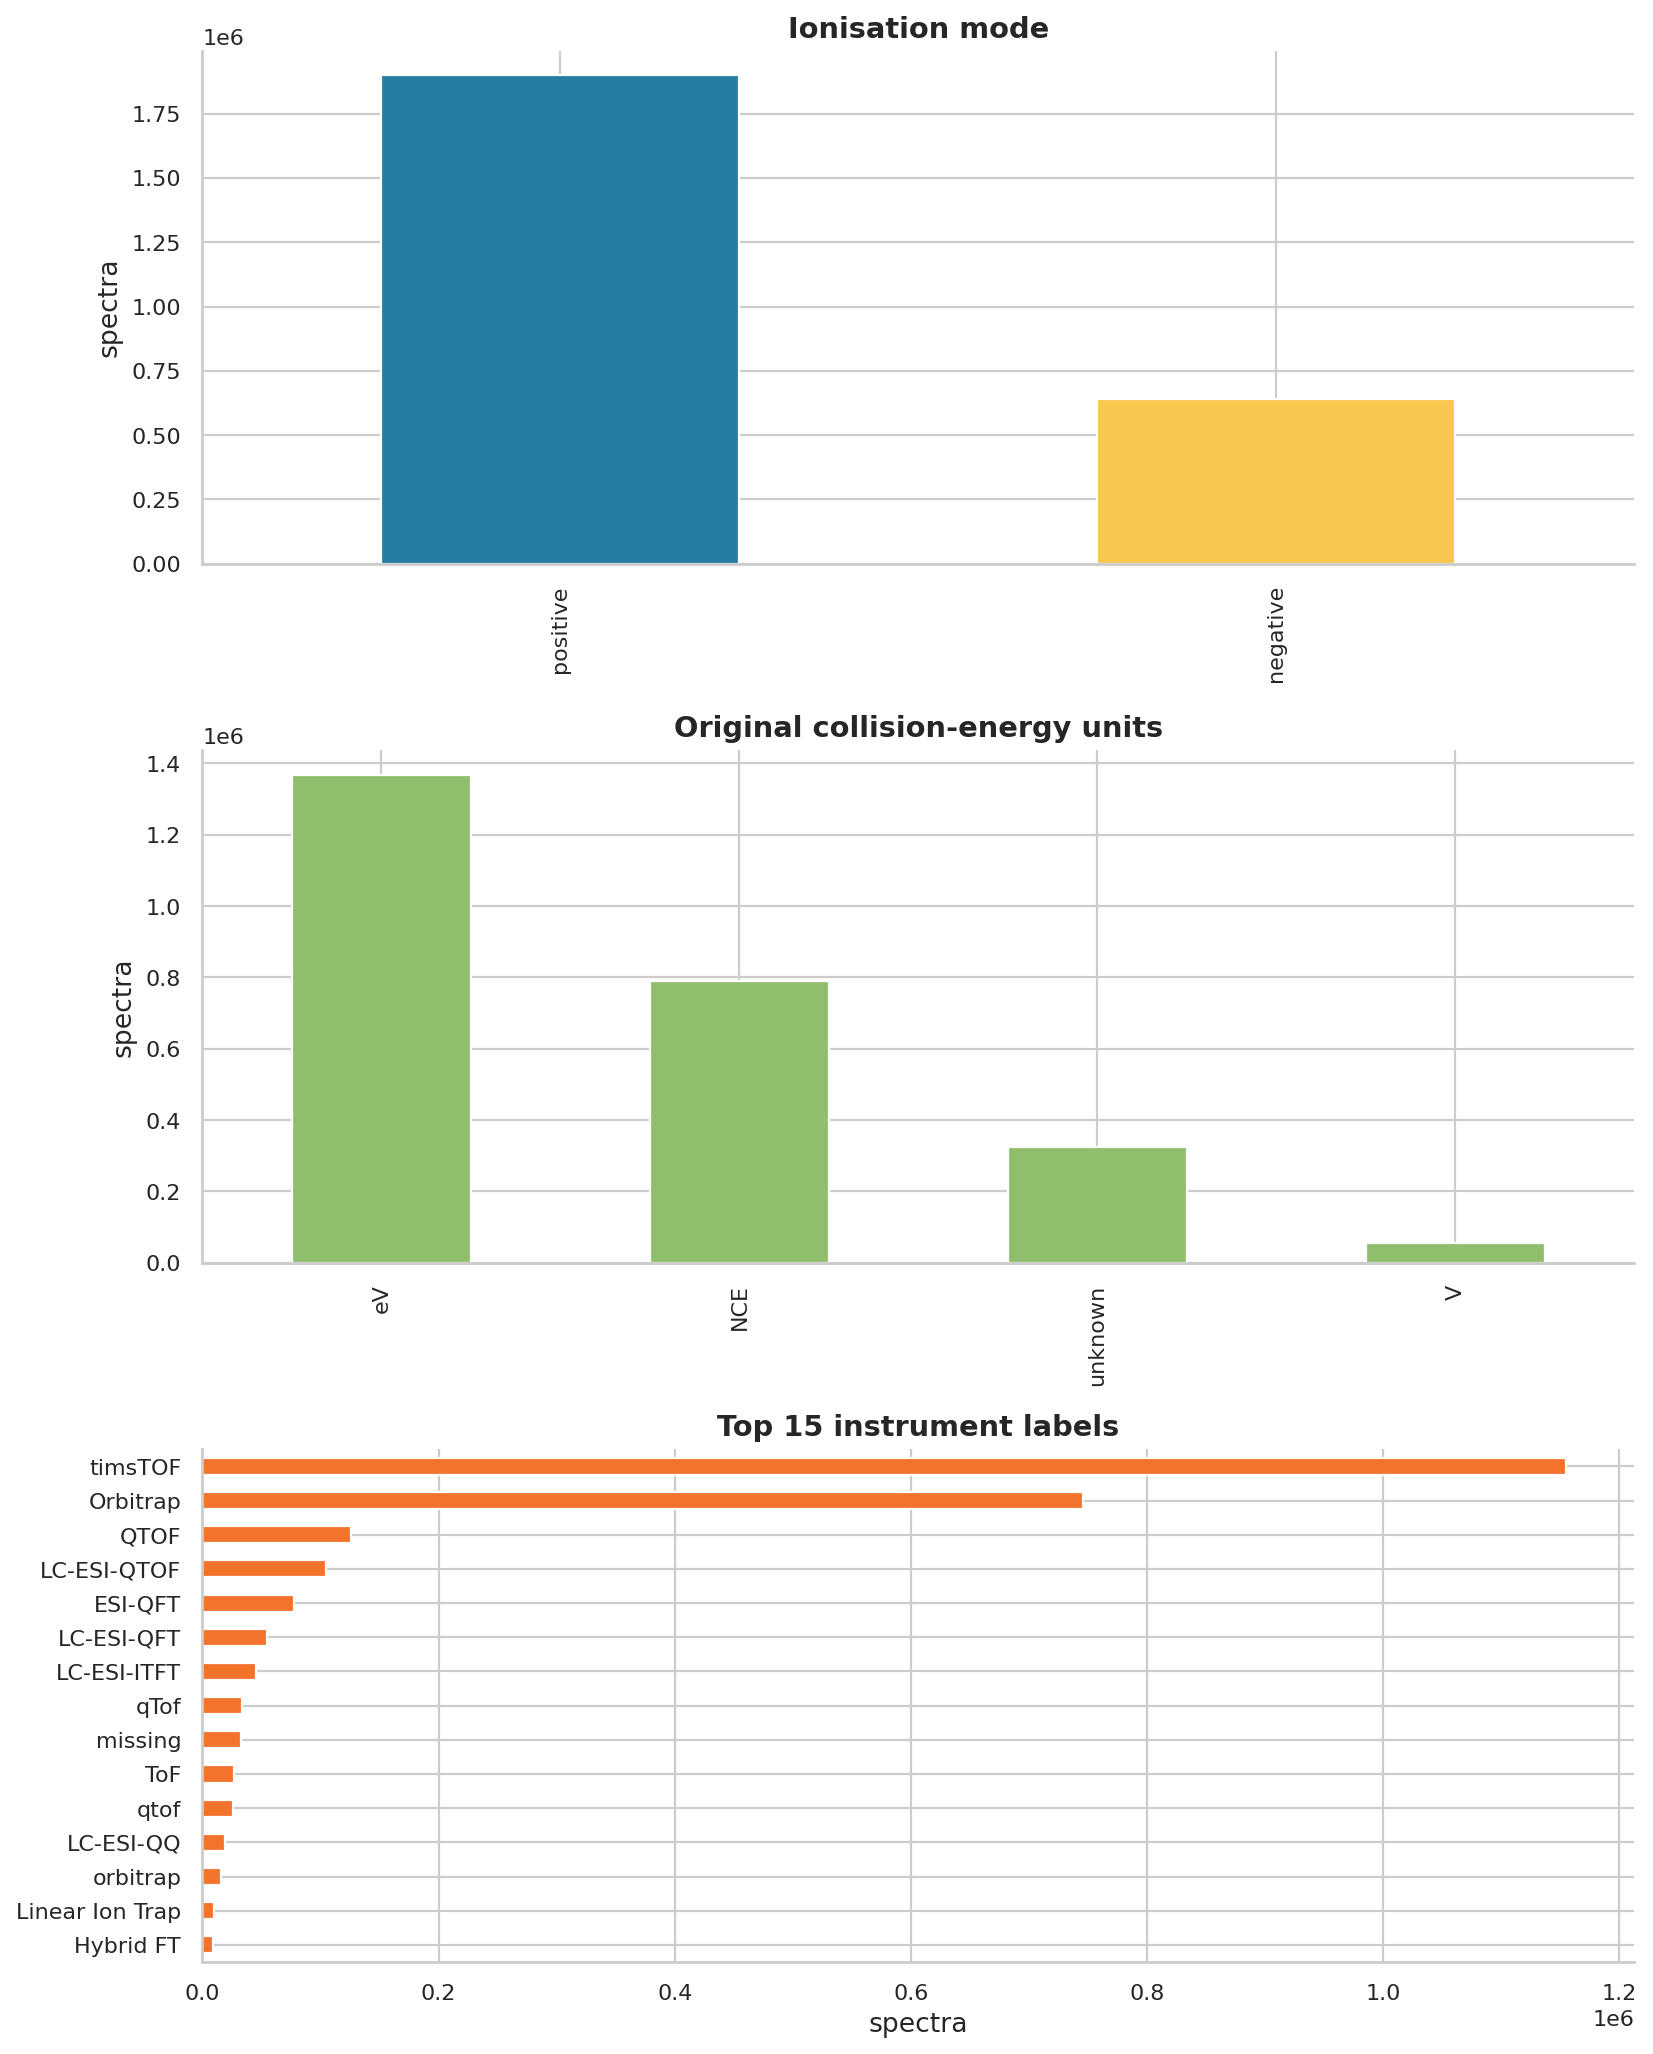

**Table 11. Most frequent adducts by ionisation polarity.**

ionization_mode,negative,positive,total
adduct,,,
[M+H]+,675,"1,323,910","1,324,585"
[M-H]-,"460,430","5,258","465,688"
[2M+Na]+,0,"190,033","190,033"
[M+Na]+,18,"178,074","178,092"
[2M+H]+,0,"92,041","92,041"
[M+CH2O2-H]-,"83,188",0,"83,188"
[2M-H]-,"56,172",0,"56,172"
[M+NH4]+,10,"53,442","53,452"
[M+Cl]-,"27,493",18,"27,511"


Distinct free-text instrument labels: 82


In [16]:
display(Markdown("**Figure 10. Experimental domains in the training corpus.**"))
fig, axes = plt.subplots(3, 1, figsize=(10.5, 13))
train["ionization_mode"].value_counts().plot.bar(ax=axes[0], color=["#277da1", "#f9c74f"])
axes[0].set(title="Ionisation mode", xlabel="", ylabel="spectra")
train["collision_energy_orig_units"].value_counts().plot.bar(ax=axes[1], color="#90be6d")
axes[1].set(title="Original collision-energy units", xlabel="", ylabel="spectra")
train["instrument_type"].fillna("missing").value_counts().head(15).sort_values().plot.barh(ax=axes[2], color="#f3722c")
axes[2].set(title="Top 15 instrument labels", xlabel="spectra", ylabel="")
plt.tight_layout()
plt.show()

adduct_table = pd.crosstab(train["adduct"], train["ionization_mode"]).assign(total=lambda x: x.sum(axis=1))
display(Markdown("**Table 11. Most frequent adducts by ionisation polarity.**"))
display(adduct_table.sort_values("total", ascending=False).head(25).style.format("{:,}"))
print("Distinct free-text instrument labels:", train["instrument_type"].nunique(dropna=True))

*Figure 10 and Table 11. Acquisition heterogeneity. Polarity, energy units, instruments, and adducts form distinct experimental domains that a robust search score should recognise.*

eV (electron volt), NCE (normalised collision energy), and V (volt) are different quantities. Use the provided `collision_energy_ev` for a common input, while preserving its approximate nature and the original metadata. A list of energies can describe a merged spectrum; reducing it to one number loses that distinction.

Mass filtering must use the full adduct equation. For a singly protonated molecule, neutral mass is precursor m/z minus the proton mass. Sodium adducts require a different offset, and dimers such as `[2M+H]+` also require division by the number of molecules. An incorrect equation can discard the correct structure before the ranker sees it.

Normalise harmless instrument spelling differences, but do not collapse genuinely different acquisition regimes. Support the complete published adduct set rather than only the adducts observed in the demonstration file.


## 8. What an MS/MS spectrum looks like in these files

An MS/MS spectrum is a set of fragment mass-to-charge ratios with associated intensities. Each vertical line is one detected fragment ion; its horizontal position is fragment m/z and its height is abundance relative to the base peak. Figures 11 and 12 move from individual acquisitions to the repeated views available for one molecule.

**Figure 11. Sparse, typical, and information-rich MS/MS spectra.**

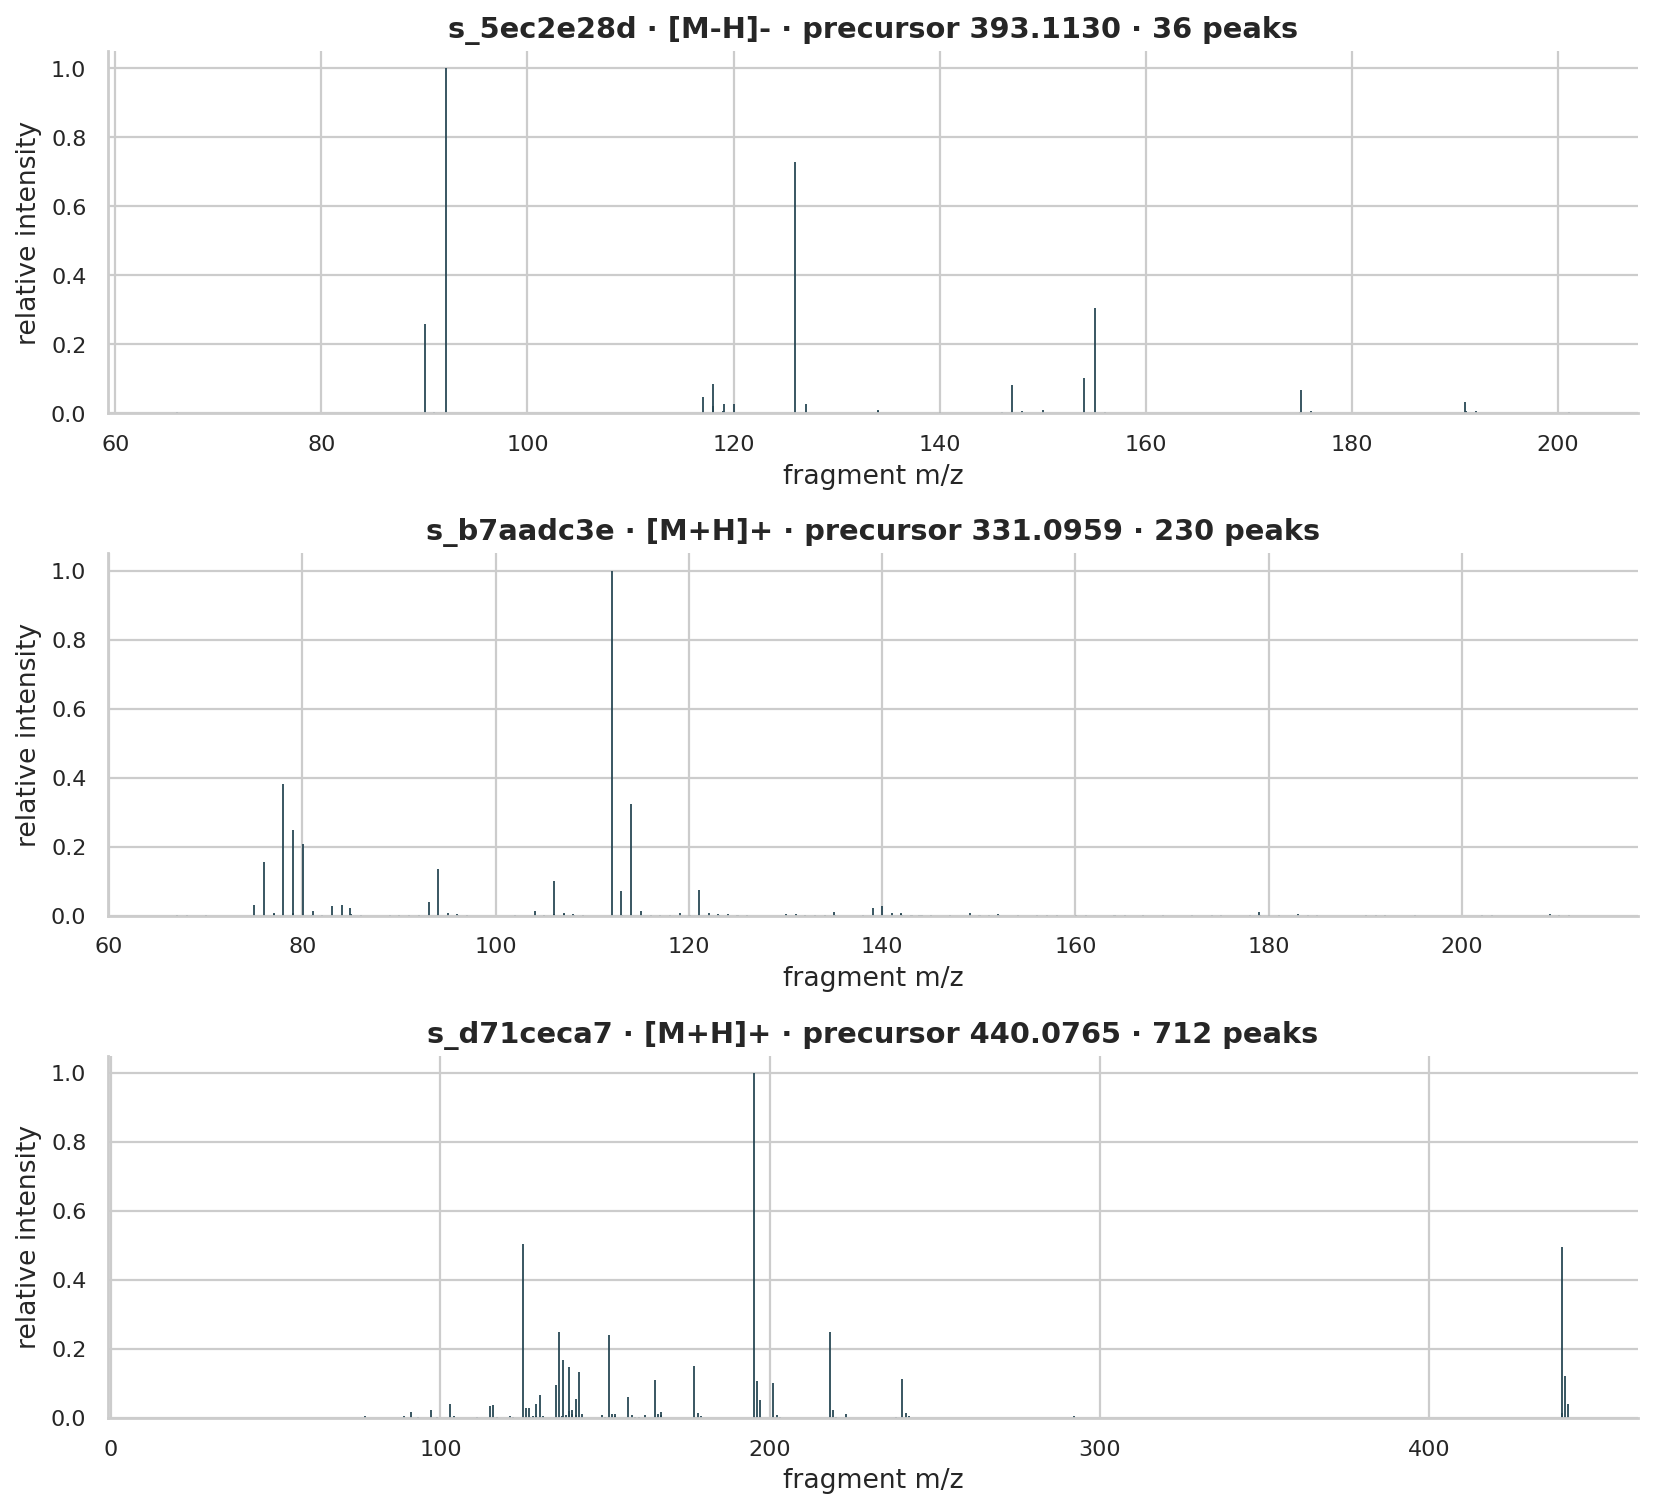

In [17]:
def read_rows_by_position(path, positions, columns):
    # Read a few global Parquet row positions without materialising all peak arrays.
    pf = pq.ParquetFile(path)
    positions = np.asarray(sorted(set(map(int, positions))), dtype=np.int64)
    chunks = []
    start = 0
    for rg in range(pf.metadata.num_row_groups):
        n = pf.metadata.row_group(rg).num_rows
        mask = (positions >= start) & (positions < start + n)
        if mask.any():
            local = pa.array(positions[mask] - start)
            chunks.append(pf.read_row_group(rg, columns=columns).take(local))
        start += n
    if not chunks:
        return pd.DataFrame(columns=columns)
    return pa.concat_tables(chunks).to_pandas()


def plot_spectrum(ax, mzs, intensities, title, color="#264653", top_n=None):
    mzs = np.asarray(mzs, dtype=float)
    intensities = np.asarray(intensities, dtype=float)
    if top_n is not None and len(mzs) > top_n:
        keep = np.argpartition(intensities, -top_n)[-top_n:]
        mzs, intensities = mzs[keep], intensities[keep]
        order = np.argsort(mzs)
        mzs, intensities = mzs[order], intensities[order]
    ax.vlines(mzs, 0, intensities, lw=0.8, color=color)
    ax.set(title=title, xlabel="fragment m/z", ylabel="relative intensity")
    ax.set_ylim(0, 1.05)


display(Markdown("**Figure 11. Sparse, typical, and information-rich MS/MS spectra.**"))

# Pick three visible-test spectra spanning low/median/high peak counts.
q_targets = test_peak_counts.quantile([.1, .5, .9]).to_numpy()
chosen = []
for target in q_targets:
    idx = (test_peak_counts - target).abs().idxmin()
    if idx not in chosen:
        chosen.append(idx)

fig, axes = plt.subplots(len(chosen), 1, figsize=(10.5, 3.2 * len(chosen)))
axes = np.atleast_1d(axes)
for ax, idx in zip(axes, chosen):
    row = test.loc[idx]
    plot_spectrum(ax, row["ms2_mzs"], row["ms2_normalized_intensities"],
                  f"{row['spectrum_id']} · {row['adduct']} · precursor {row['precursor_mz']:.4f} · "
                  f"{len(row['ms2_mzs'])} peaks", top_n=500)
plt.tight_layout()
plt.show()

*Figure 11. Three measured spectra spanning the visible sample's peak-count distribution. Compare fragment density and m/z coverage; peak richness describes an acquisition, not identification confidence or molecular complexity.*

**Figure 12. Multiple collision-energy and adduct views of one molecule.**

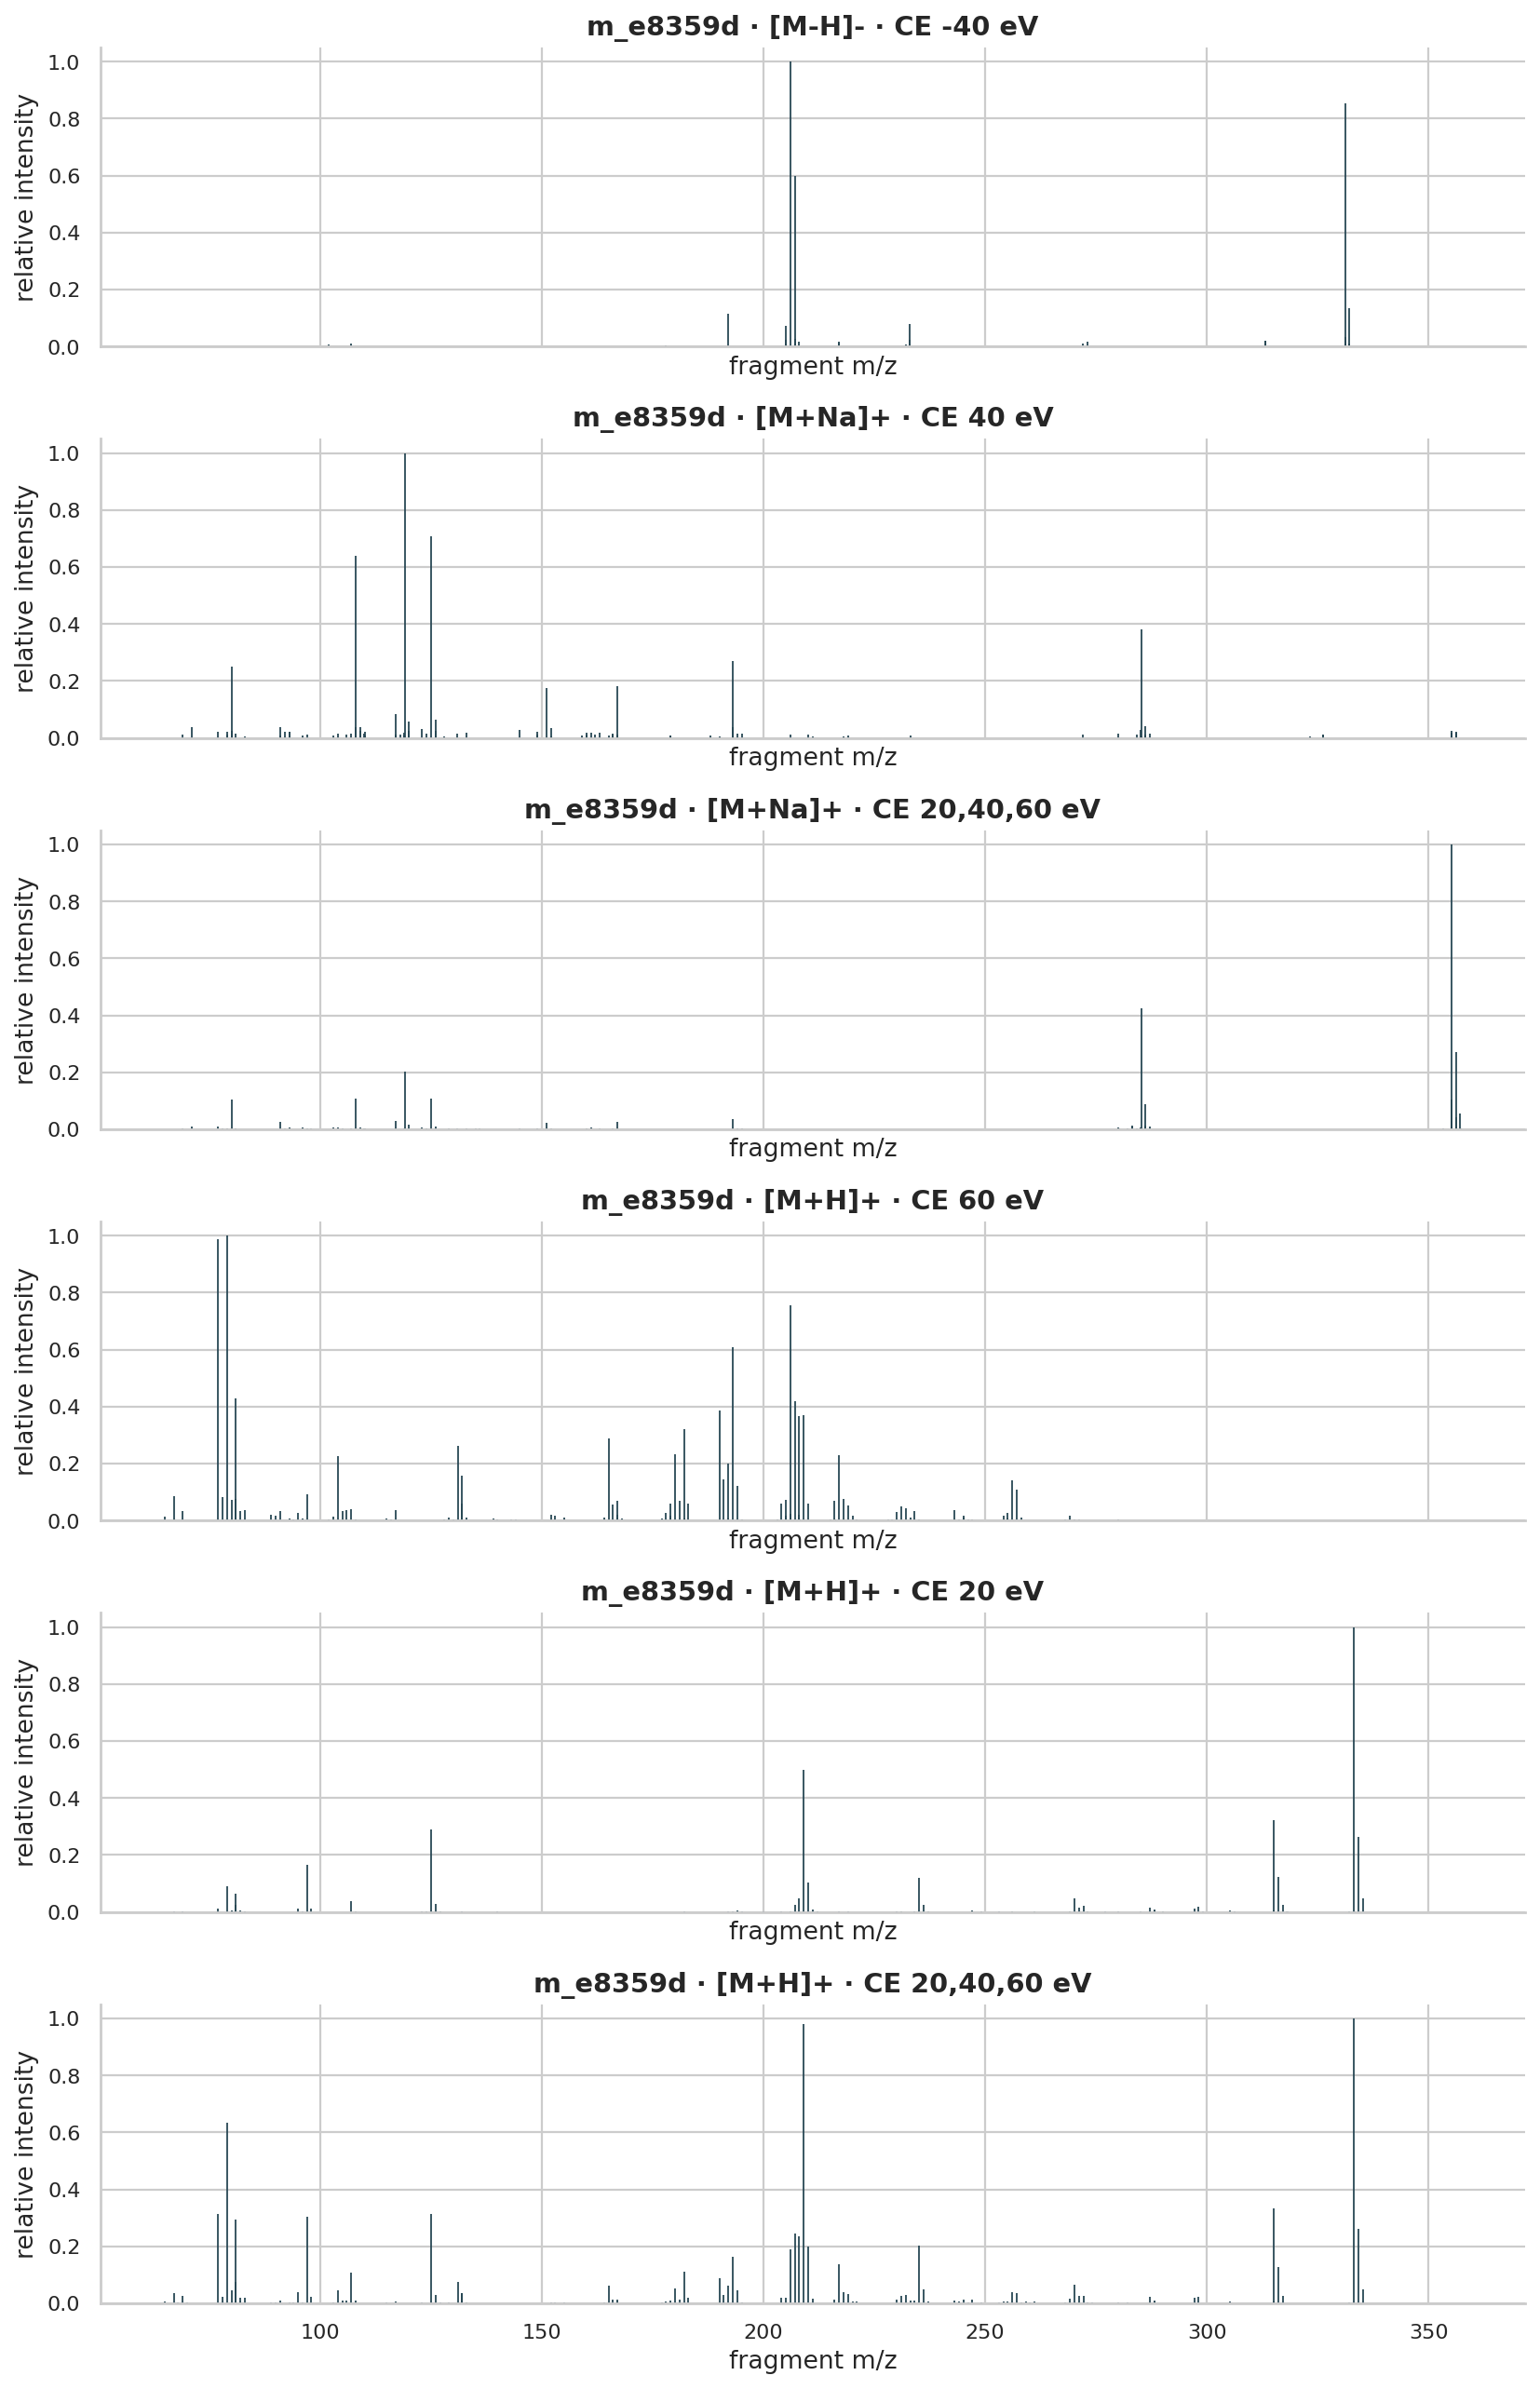

In [18]:
display(Markdown("**Figure 12. Multiple collision-energy and adduct views of one molecule.**"))

# Multiple spectra of one molecule: evidence changes with adduct and collision energy.
example_id = spectra_per_molecule.sort_values(ascending=False).index[0]
example = test[test["molecule_id"].eq(example_id)].head(6)
fig, axes = plt.subplots(len(example), 1, figsize=(10.5, 2.7 * len(example)), sharex=True)
axes = np.atleast_1d(axes)
for ax, (_, row) in zip(axes, example.iterrows()):
    energy_unit = (row['collision_energy_orig_units']
                   if pd.notna(row['collision_energy_orig_units']) else 'unit not recorded')
    plot_spectrum(ax, row["ms2_mzs"], row["ms2_normalized_intensities"],
                  f"{example_id} · {row['adduct']} · CE {row['collision_energy_orig']} {energy_unit}", top_n=350)
plt.tight_layout()
plt.show()

*Figure 12. Repeated MS/MS views of one molecule. The panel titles report each acquisition's adduct and collision setting; their fragment patterns can differ, so molecule-level inference should fuse these views rather than select one arbitrarily.*

Several spectra of one molecule are complementary views, not independent prediction targets. Section 10 combines their evidence into one candidate list per `molecule_id` and explains how reference, analogue and fingerprint signals enter the score.

## 9. Molecular labels: structures, descriptors, and chemical space

The spectra describe the measurement; the labels show which molecular graphs are represented. Molecular drawings, descriptors, and fingerprints help connect a source library to its region of chemical space.

The key modelling question is whether our reference molecules resemble the compounds we hope to identify. A model can transfer poorly even when train and test use the same instrument, if their underlying chemistry differs.


**Figure 13. One example molecular structure per source library.**

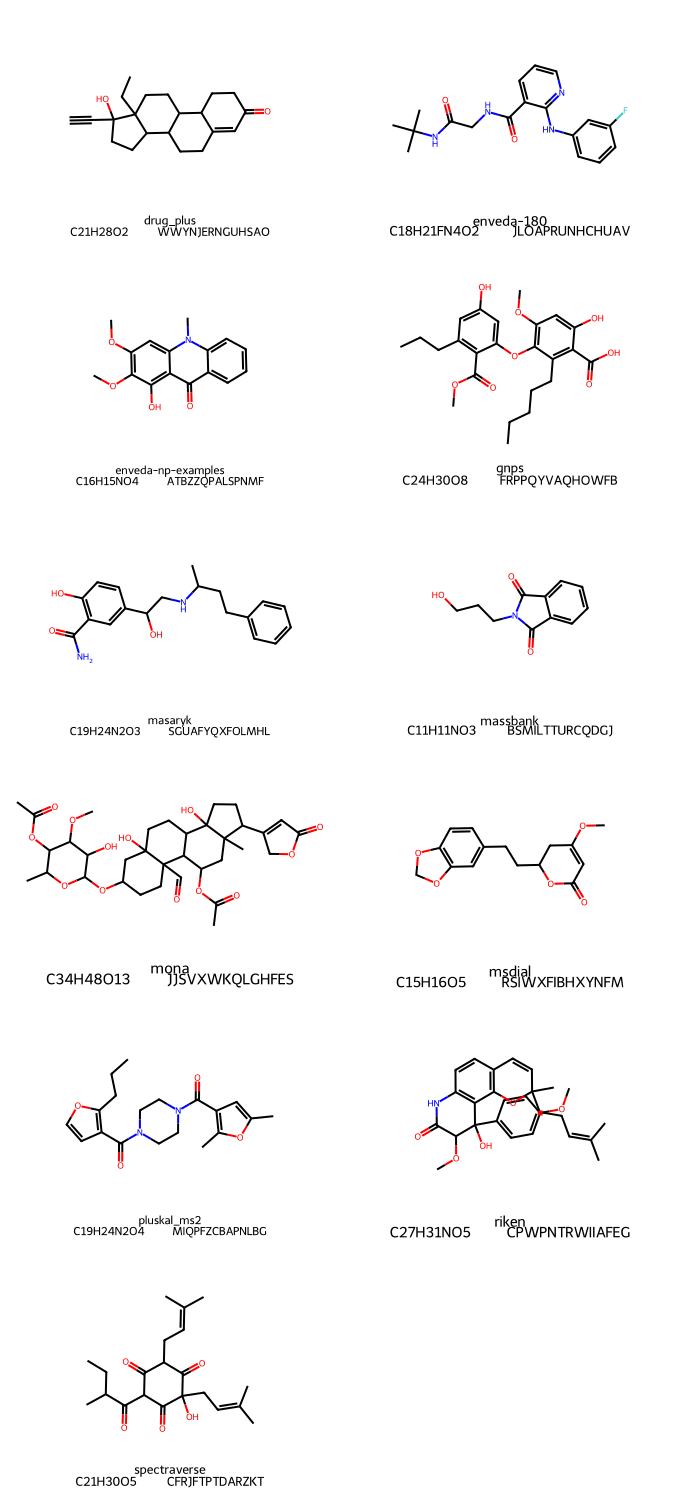

In [19]:
display(Markdown("**Figure 13. One example molecular structure per source library.**"))

# Draw deterministic representatives from several source libraries.
representatives = (train.query("150 <= precursor_mz <= 700 and 8 <= num_peaks <= 500")
                   .drop_duplicates(["ingest_lib", "inchikey14"])
                   .groupby("ingest_lib", group_keys=False)
                   .sample(n=1, random_state=SEED))
mols, legends = [], []
for _, row in representatives.iterrows():
    mol = Chem.MolFromSmiles(row["normalized_smiles"])
    if mol is not None:
        mols.append(mol)
        legends.append(f"{row['ingest_lib']}\n{row['molecular_formula']} · {row['inchikey14']}")

display(Draw.MolsToGridImage(mols, molsPerRow=2, subImgSize=(340, 250), legends=legends, useSVG=True))

*Figure 13. One selected structure per source library, not a summary of the library's chemical domain. The bounded descriptor sample in Table 12/Figure 14 and source-aware projection in Figure 15 provide broader context; this gallery shows individual molecular graphs.*

**Table 12. Molecular-descriptor summary for 20,000 sampled connectivities.**

Descriptor sample: 20,000 valid molecules; 0 parse failures


,count,mean,std,min,25%,50%,75%,max
MolWt,20000.00,358.26,135.40,58.08,304.39,333.39,365.43,2769.76
cLogP,20000.00,2.72,2.43,-22.69,1.68,2.48,3.29,21.87
heavy_atoms,20000.00,25.18,9.54,4.00,21.00,23.00,26.00,192.00
rings,20000.00,2.81,1.23,0.00,2.00,3.00,3.00,17.00
rotatable_bonds,20000.00,5.99,7.03,0.00,3.00,4.00,6.00,84.00
TPSA,20000.00,77.15,48.83,0.00,56.33,69.48,85.06,1274.10


**Figure 14. Molecular-property distributions.**

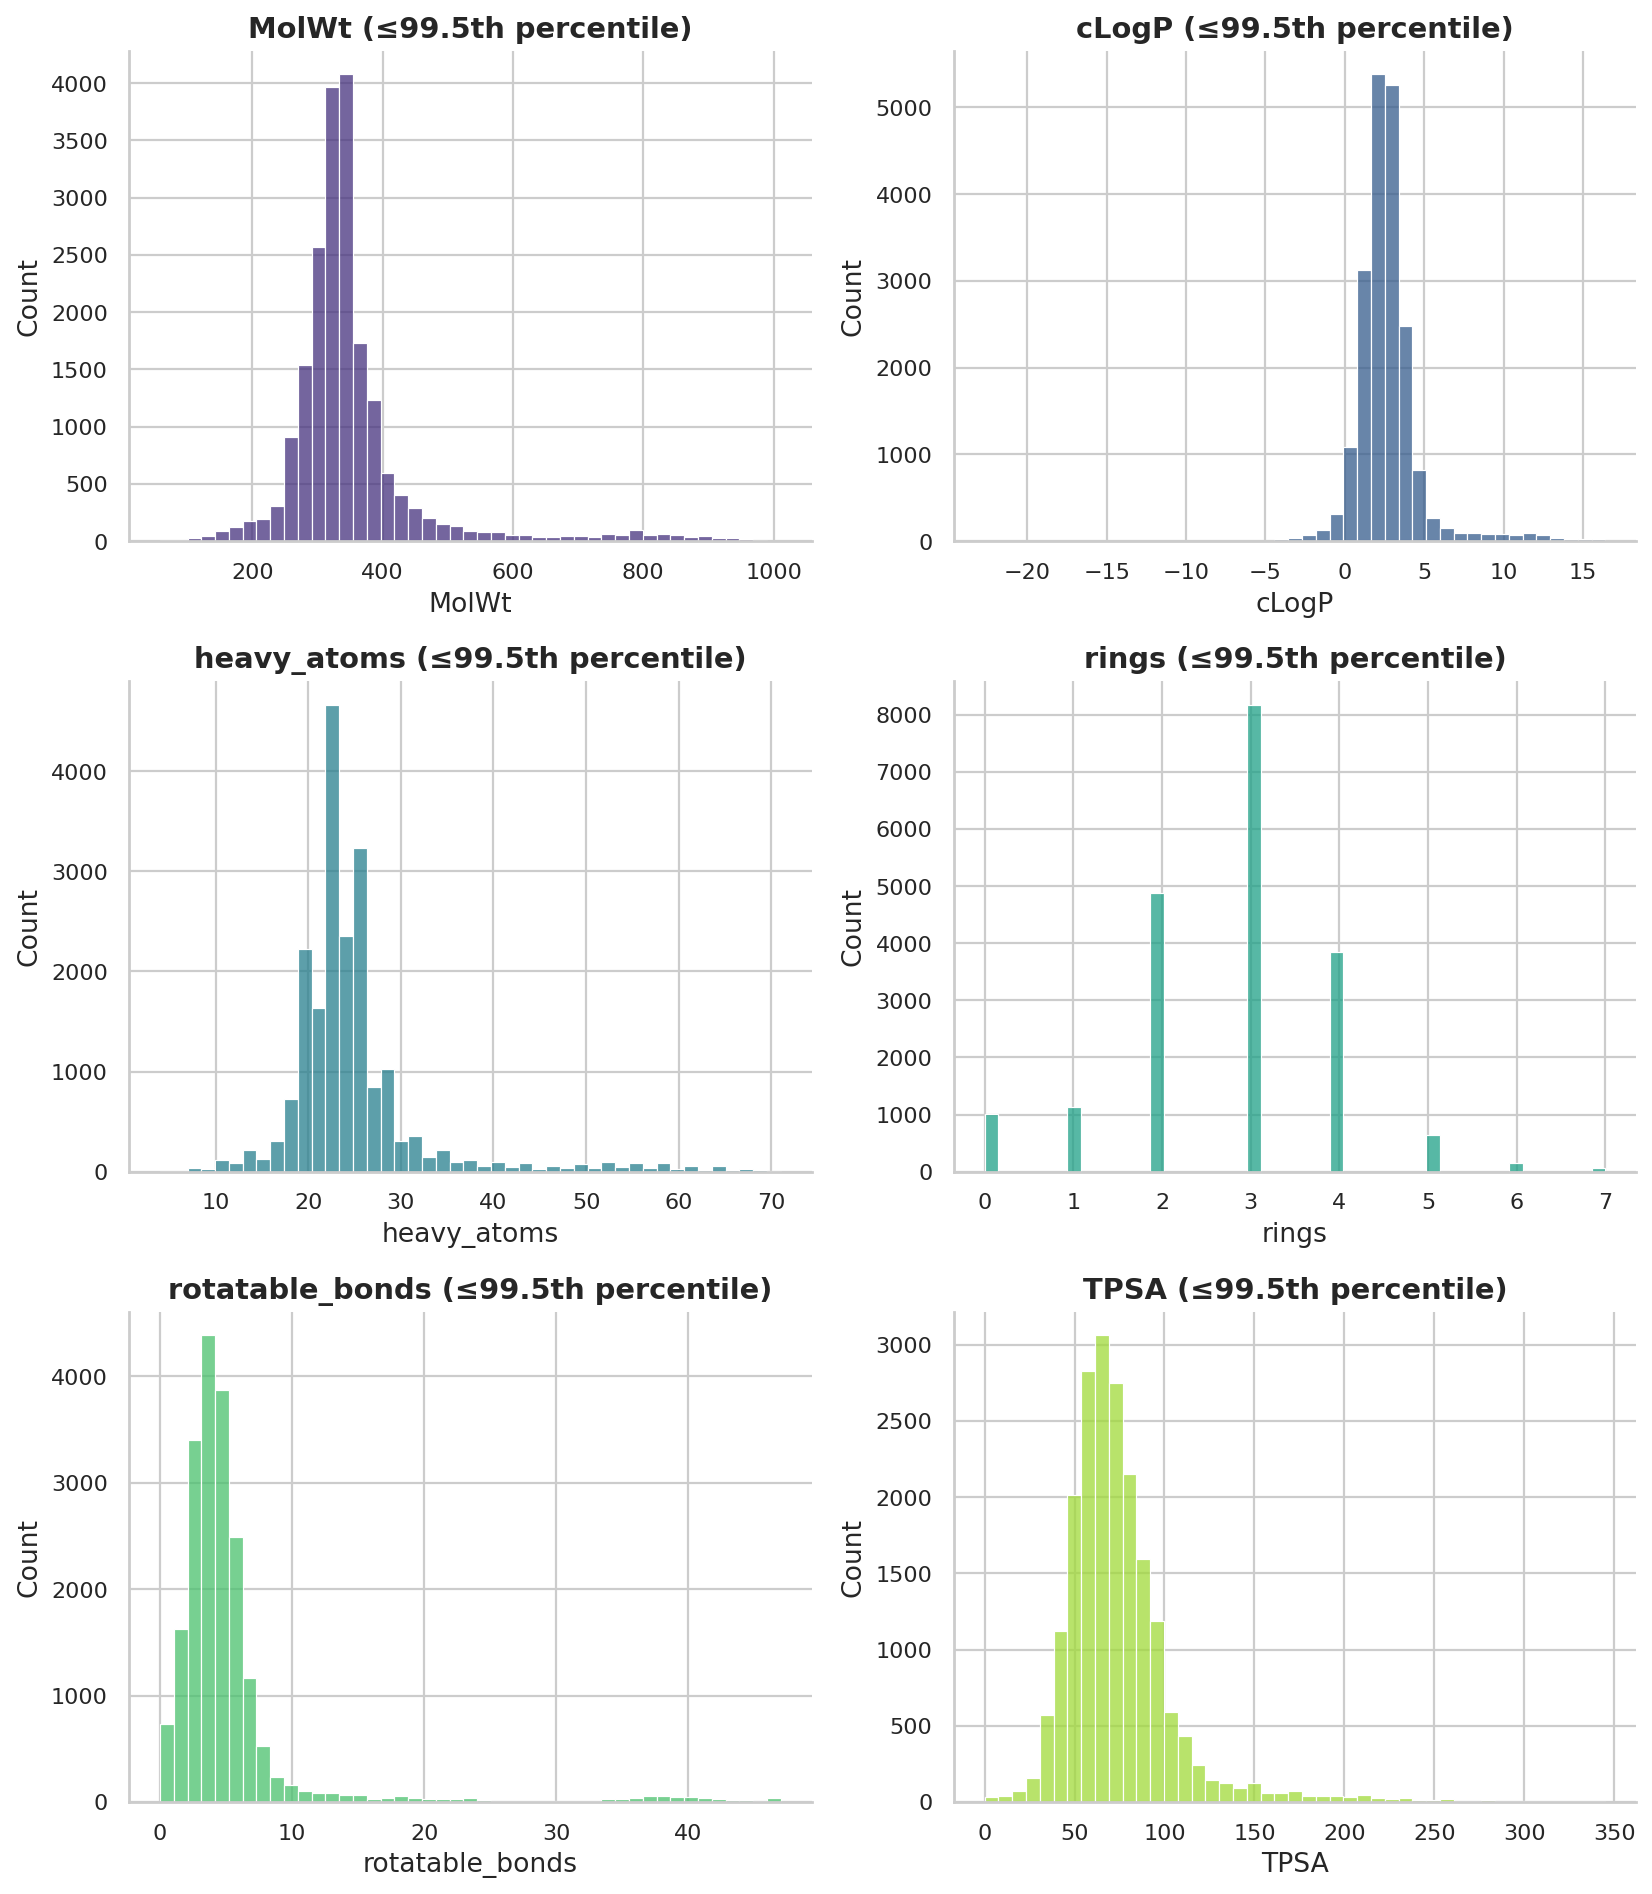

In [20]:
# Descriptor analysis on a fixed, bounded sample of unique stored InChIKey14 groups.
unique_structures = train.drop_duplicates("inchikey14").copy()
n_descriptor = min(20_000, len(unique_structures))
descriptor_sample = unique_structures.sample(n=n_descriptor, random_state=SEED)

records = []
invalid = 0
for _, row in descriptor_sample.iterrows():
    mol = Chem.MolFromSmiles(row["normalized_smiles"])
    if mol is None:
        invalid += 1
        continue
    records.append({
        "ingest_lib": row["ingest_lib"],
        "inchikey14": row["inchikey14"],
        "mol": mol,
        "MolWt": Descriptors.MolWt(mol),
        "cLogP": Descriptors.MolLogP(mol),
        "heavy_atoms": rdMolDescriptors.CalcNumHeavyAtoms(mol),
        "rings": rdMolDescriptors.CalcNumRings(mol),
        "rotatable_bonds": rdMolDescriptors.CalcNumRotatableBonds(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
    })
desc = pd.DataFrame(records)
display(Markdown(f"**Table 12. Molecular-descriptor summary for {len(desc):,} sampled connectivities.**"))
print(f"Descriptor sample: {len(desc):,} valid molecules; {invalid:,} parse failures")
display(desc.drop(columns="mol").describe().T.style.format("{:.2f}"))

display(Markdown("**Figure 14. Molecular-property distributions.**"))
fig, axes = plt.subplots(3, 2, figsize=(10.5, 12))
for ax, col, color in zip(axes.flat,
                          ["MolWt", "cLogP", "heavy_atoms", "rings", "rotatable_bonds", "TPSA"],
                          sns.color_palette("viridis", 6)):
    cap = desc[col].quantile(.995)
    sns.histplot(desc.loc[desc[col] <= cap, col], bins=45, ax=ax, color=color)
    ax.set_title(f"{col} (≤99.5th percentile)")
plt.tight_layout()
plt.show()

*Table 12 and Figure 14. Molecular-descriptor summary and distributions. Molecular weight, lipophilicity, size, rings, flexibility, and polar surface area describe sampled training structures, not the full COCONUT/PubChem candidate pool.*

**Figure 15. Source-aware projection of molecular substructure space.**

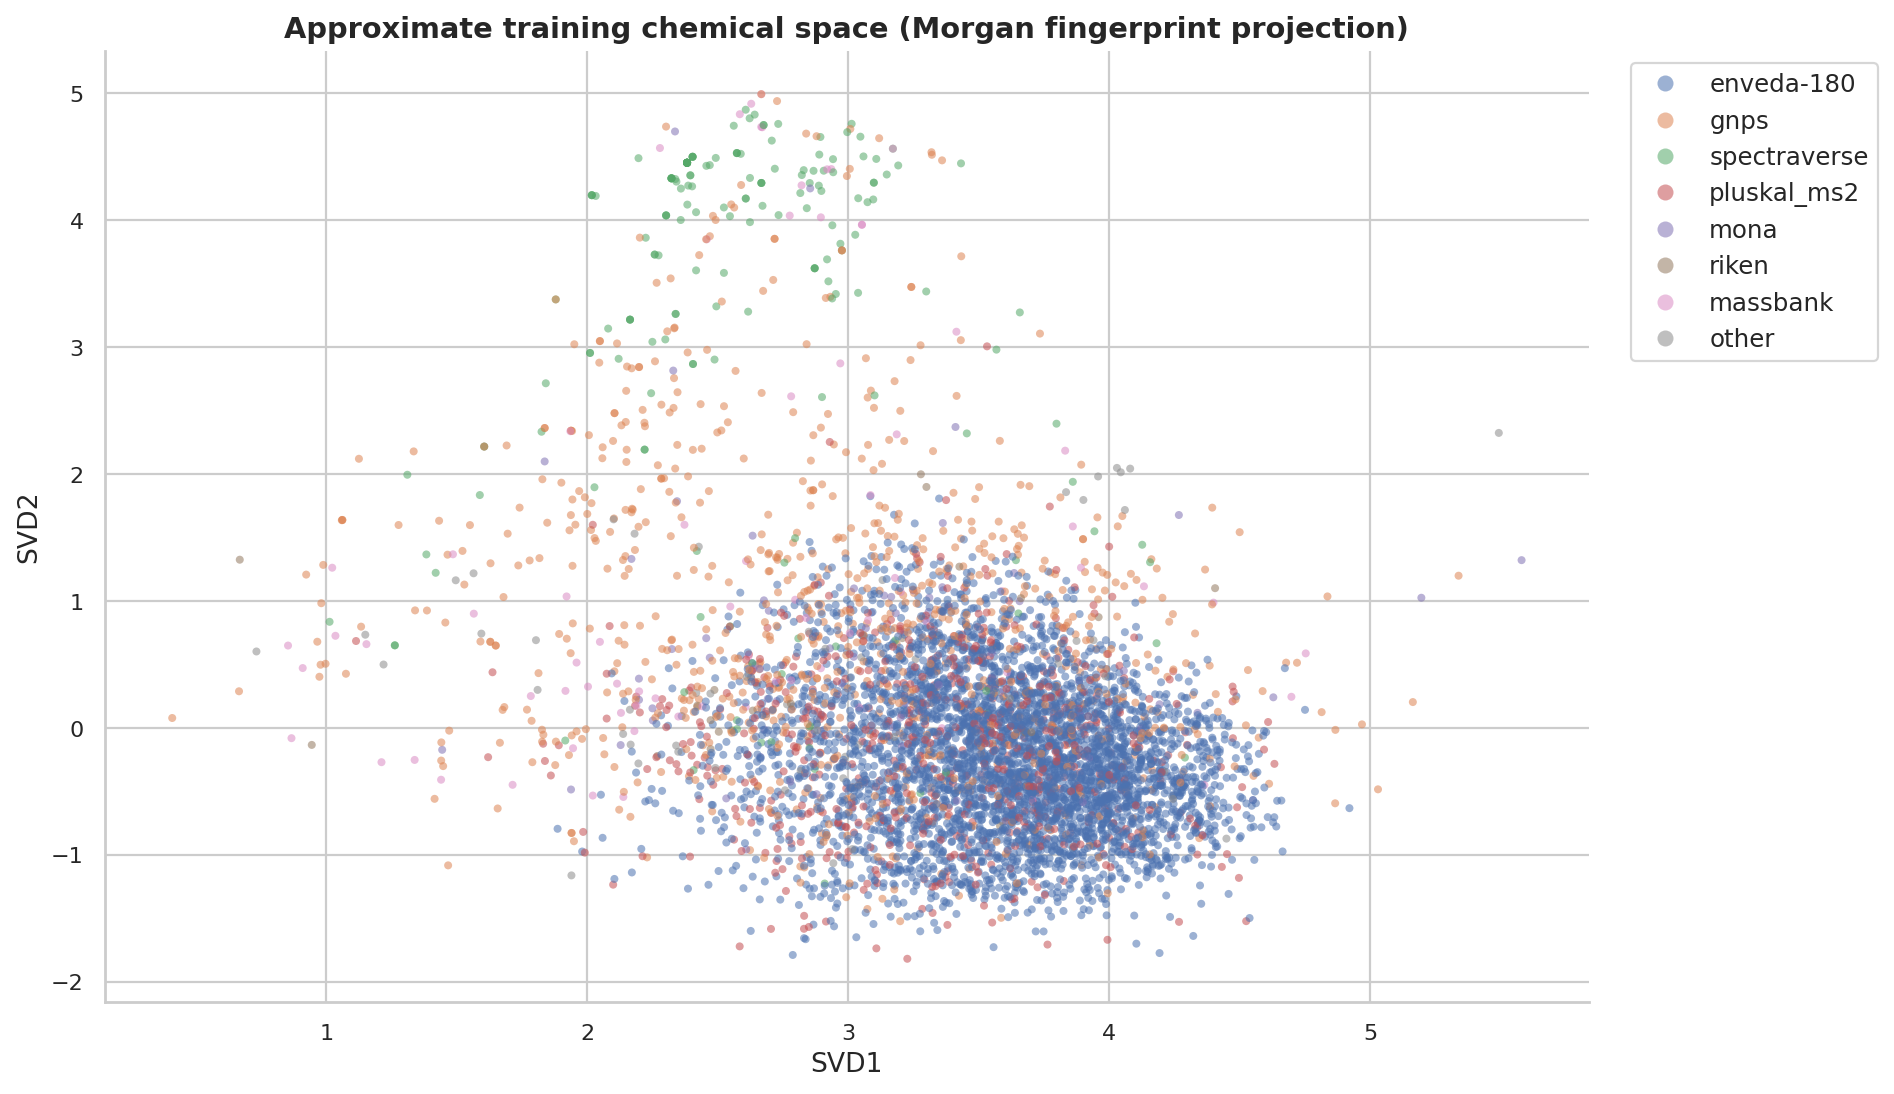

In [21]:
display(Markdown("**Figure 15. Source-aware projection of molecular substructure space.**"))

# Morgan fingerprints (circular substructure fingerprints) projected only for visual EDA.
n_fp = min(6_000, len(desc))
fp_sample = desc.sample(n=n_fp, random_state=SEED).reset_index(drop=True)
generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=512)
X = np.zeros((n_fp, 512), dtype=np.uint8)
for i, mol in enumerate(fp_sample["mol"]):
    DataStructs.ConvertToNumpyArray(generator.GetFingerprint(mol), X[i])
projection = TruncatedSVD(n_components=2, random_state=SEED).fit_transform(X)
fp_sample[["SVD1", "SVD2"]] = projection

top_libs = library_stats.head(7).index
fp_sample["source"] = fp_sample["ingest_lib"].where(fp_sample["ingest_lib"].isin(top_libs), "other")
fig, ax = plt.subplots(figsize=(12, 7))
sns.scatterplot(data=fp_sample, x="SVD1", y="SVD2", hue="source", s=13, alpha=.55, linewidth=0, ax=ax)
ax.set_title("Approximate training chemical space (Morgan fingerprint projection)")
ax.legend(markerscale=2, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

*Figure 15. A two-dimensional projection of sampled Morgan fingerprints, which encode local molecular substructures. Colours show source composition in the displayed sample. Overlap and separation suggest questions about chemical coverage; they are not quantitative estimates of hidden-test similarity.*


A fingerprint records local molecular substructures. Its projection makes broad patterns visible, but compressing many dimensions into two distorts distances and can create apparent clusters. Source labels may also overlap for the same connectivity.

Use this figure to formulate validation questions: do errors concentrate in sparsely represented chemistry, do source-held-out scores fall, and does a natural-product candidate database add missing answers? Answer those questions with held-out molecules and candidate-coverage measurements, not the appearance of the plot alone.


## 10. The model: a candidate list with several kinds of evidence

A tandem mass spectrum records fragment ions, not a molecular graph. The precursor's measured mass and its adduct (for example, the added proton in `[M+H]+`) give an estimate of the neutral molecule's mass. A search window of **10 parts per million (ppm)** allows a mass difference of roughly 0.0037 Da at 370 Da; the engine widens it to 30 ppm only when the narrow window has no candidates. This removes most impossible structures, but leaves isomers that share a formula and mass.

The main pool has **710,701 structure rows**: 274,186 linked to training structures and 436,515 from [COCONUT](https://coconut.naturalproducts.net/), an open natural-products collection. The competition training file separately provides **measured reference spectra**. A database structure is a proposal; it becomes a measured reference only if the training file actually contains its spectrum. The engine can also derive a new mass-compatible structure from a close spectral analogue. That generation step matters when the answer is absent from the starting pool: a ranker cannot recover a structure it never receives.

The engine compares a query with measured spectra, including near matches that differ in precursor mass. **FPNet** predicts molecular fingerprint bits from up to 16 spectra and their polarity, adduct, precursor and collision-energy fields. A fingerprint bit indicates whether a particular molecular substructure is likely present. Fragment and subformula features then ask whether each proposed structure can explain the observed peaks. Five further `fe_v4` feature families describe generation evidence, fragments, relations to analogues, agreement among FPNet views and learned fragments. Four pretrained **LightGBM models**, each an ensemble of boosted trees, combine 160 selected features into a candidate score. These weights are supplied with the source package; the notebook uses them for inference.

A separate [PubChem](https://pubchem.ncbi.nlm.nih.gov/) search looks beyond that pool. Its FPNet A+B models first screen a 10-ppm window, then fully score the best 1,000 structures and retain up to 25 new connectivity keys. For suitable positive-mode spectra, **ICEBERG** predicts fragments for a bounded shortlist of same-formula isomers and compares its predicted spectrum with the measured peaks; it can reorder candidates within a formula group. **GLACIER** supplies a second predicted spectrum for the same candidates and covered acquisitions. Following v4h, the within-formula score is `z(ranker) + 0.5 z(ICEBERG) + 0.5 z(GLACIER)`, where `z` centres a score and divides it by its sample standard deviation within that formula group. Missing or constant scores contribute zero; ties keep the original order. Each formula group keeps its original list positions. GLACIER is applied where the ICEBERG branch is active; if GLACIER has no usable scores, the v17 ICEBERG ordering is retained. These forward models reorder existing candidates; they do not expand the structure pool.

The final gate uses two internal scores: `lib_max` measures the strongest measured-library match, while `Δ = best PubChem FPNet score − best main-pool FPNet score` compares proposal channels. These are model scores, not probabilities. PubChem proposals enter only under the following fixed rule; all positions are one-based in the top-25 list.

| Condition | Final ordering |
|---|---|
| `lib_max ≥ 0.9` | Keep the main list: a strong measured match takes priority. |
| No PubChem proposals | Keep the main list. |
| `lib_max < 0.9` and `Δ > 600` | Insert new PubChem keys at positions 2, 4, 6, 8 and 10. |
| `lib_max < 0.9` and `Δ ≤ 600` | Insert them at positions 4, 8, 12, 16 and 20. |

The gate preserves the relative order of the remaining main candidates and removes duplicate connectivity keys. The numerical thresholds and slot positions come from the [public v4g inference method](https://www.kaggle.com/code/ahmedberatozer/casmi26-v4g-inference); this notebook does not reselect them on the visible test data. The five source packages and their separate terms are documented in [the attributed asset fork](https://www.kaggle.com/datasets/dmitriigluzdov/casmi26-attributed-v4g-reproduction-assets).

The GLACIER integration follows the [public v4h notebook](https://www.kaggle.com/code/ahmedberatozer/casmi26-v4h-inference). Its [public model package](https://www.kaggle.com/datasets/ahmedberatozer/casmi26-glacier) includes the checkpoint, source, compatibility shims, a manifest and source-license notices. The model was trained on MassSpecGym; complete independence from CASMI training structures is not established. The 0.5 weights are inherited from that method, not selected using this notebook's visible examples.


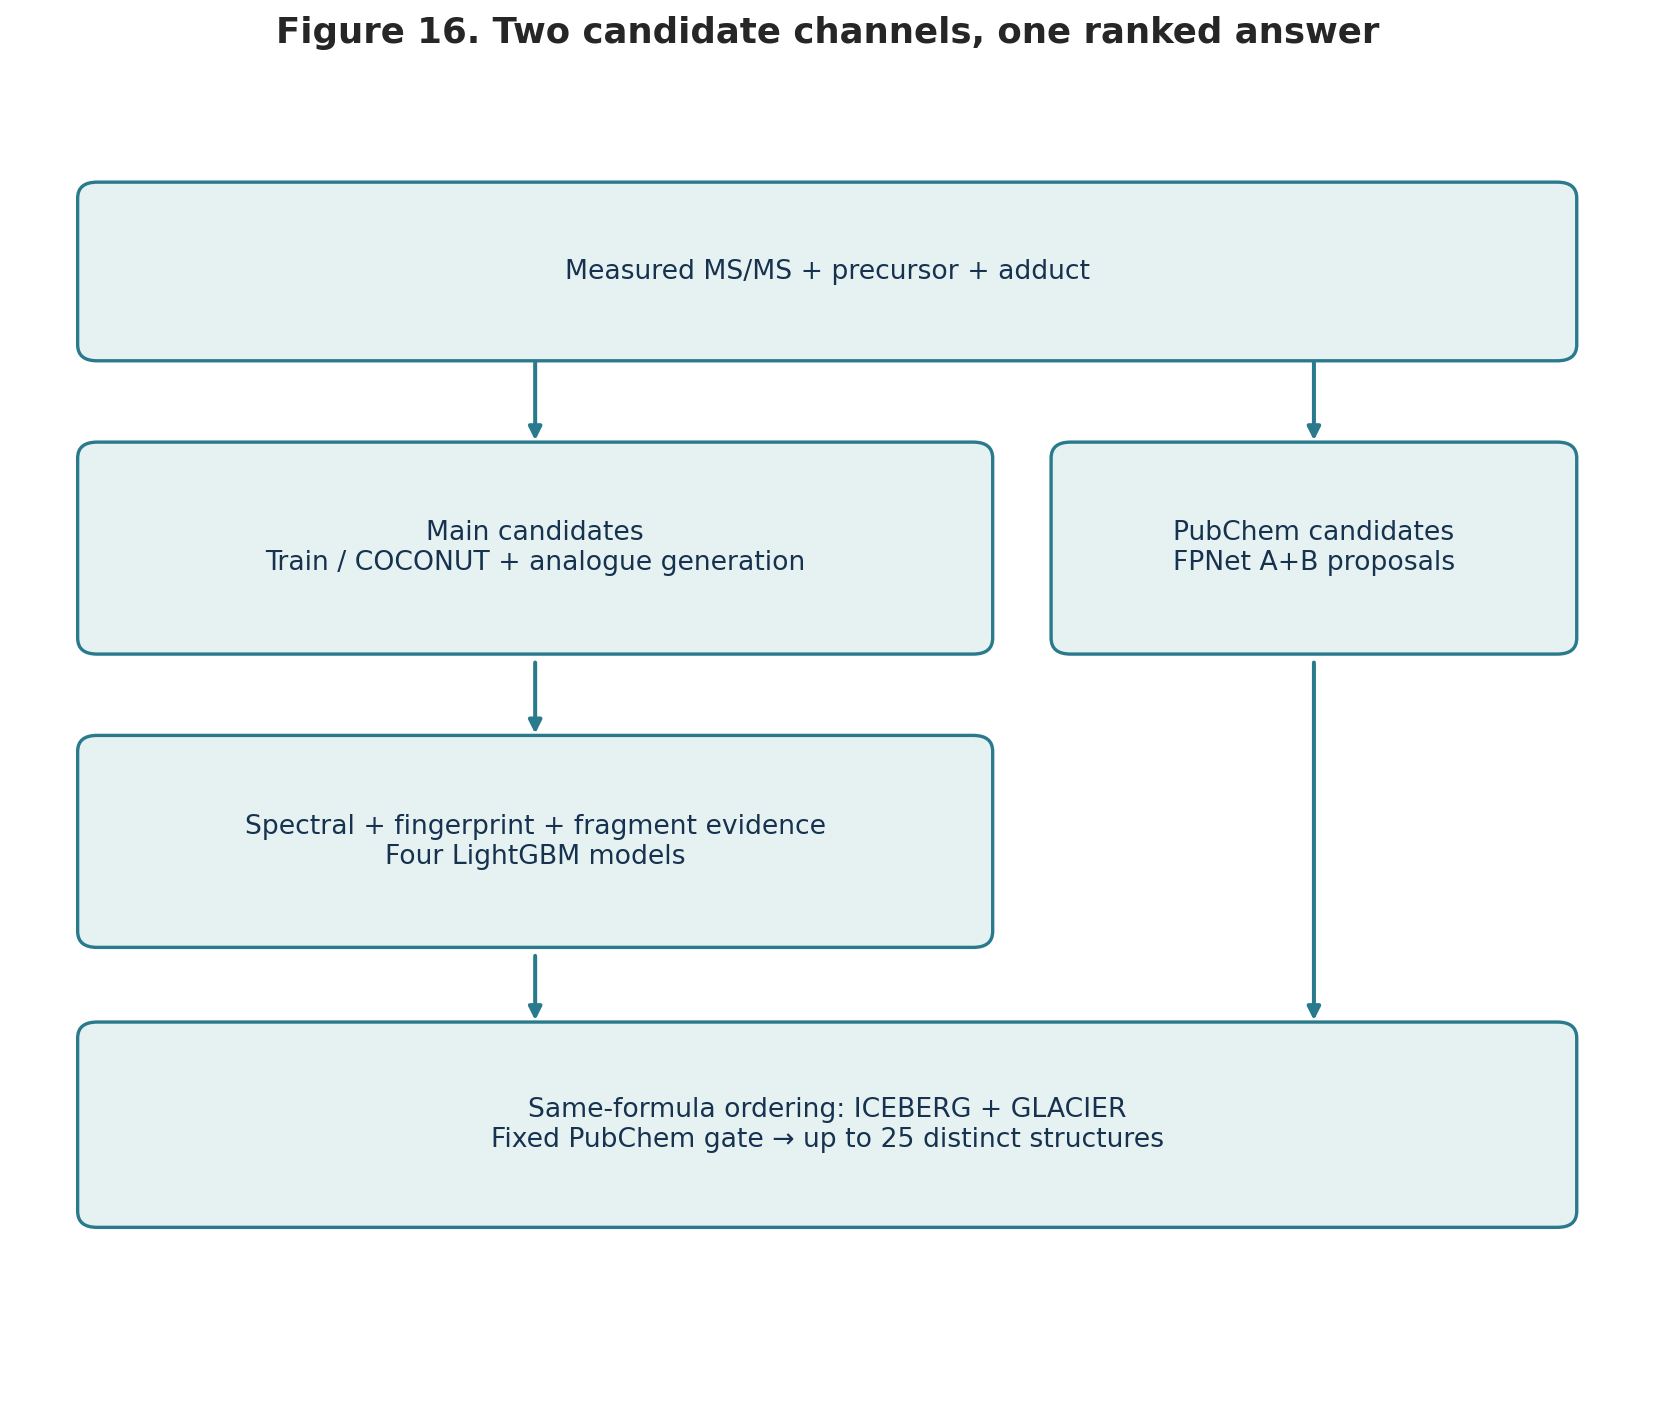

In [22]:
# Figure 16: the ranking method, including the separate proposal branch.
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(10.5, 9))
ax.set(xlim=(0,10), ylim=(0,10)); ax.axis('off')
boxes = [
 (0.5,7.9,9,1.1,'Measured MS/MS + precursor + adduct'),
 (0.5,5.7,5.4,1.35,'Main candidates\nTrain / COCONUT + analogue generation'),
 (6.5,5.7,3,1.35,'PubChem candidates\nFPNet A+B proposals'),
 (0.5,3.5,5.4,1.35,'Spectral + fingerprint + fragment evidence\nFour LightGBM models'),
 (0.5,1.4,9,1.3,'Same-formula ordering: ICEBERG + GLACIER\nFixed PubChem gate → up to 25 distinct structures'),
]
for x,y,w,h,label in boxes:
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=.12',fc='#e6f1f2',ec='#287a8c',lw=1.5))
    ax.text(x+w/2,y+h/2,label,ha='center',va='center',fontsize=12,color='#16324f')
for a,b in [((3.2,7.8),(3.2,7.15)),((8,7.8),(8,7.15)),((3.2,5.55),(3.2,4.95)),((3.2,3.35),(3.2,2.8)),((8,5.55),(8,2.8))]:
    ax.annotate('',xy=b,xytext=a,arrowprops=dict(arrowstyle='-|>',lw=1.8,color='#287a8c'))
ax.set_title('Figure 16. Two candidate channels, one ranked answer',fontsize=16,pad=10)
plt.tight_layout(); plt.show()


*Figure 16. Main-pool candidates receive learned spectral and structural scores; a separate PubChem channel proposes additional structures. ICEBERG and GLACIER can reorder eligible same-formula groups before the fixed gate merges the lists. Neither forward model generates new molecular graphs.*

## 11. Validation: separate coverage, ordering and execution

Ask three questions in order. **Coverage:** is the answer's scorer-canonical connectivity present in the actual mass-window or generated candidates? **Ordering:** when it is present, how high does it rank? **Full-list accuracy:** over every held-out molecule, including those whose answer never appears, what are top-1, top-25 and MRR@25? A coverage miss contributes zero MRR regardless of how good the ranking model is. Looking at coverage and ordering separately tells us whether to improve candidate generation or scoring.

The pretrained packages do not document a complete, independently rerunnable identity-disjoint outer fold. Section 12 therefore checks execution and output shape, while an accepted Kaggle submission supplies the public leaderboard score. Neither is a substitute for new local held-out training. The visible `test.parquet` shows the input format but has no answer structures.

To test a future modification locally, freeze scorer-normalised identities before fitting. Put **all** spectra of one identity on one side; remove held-out identities from FPNet fitting, tree fitting, and measured-reference search. Declare whether its structure is allowed in the training-derived candidate pool (structure-only ranking) or removed (novel-training-structure coverage), while leaving explicitly named external catalogues unchanged. Rebuild the feature and candidate rows for each fold, train on fit identities, choose parameters on an inner fold, and report candidate presence and final MRR on a separate outer fold. This protocol lets a reader tell whether a proposed improvement finds new structures or merely reorders familiar ones.

In [23]:
# EDA has finished: release scalar tables and RDKit objects before constructing the search index.
import gc
for _name in ("train", "unique_structures", "descriptor_sample", "desc", "fp_sample", "records",
              "preview_pool", "representatives", "mols", "X", "projection", "library_pairs"):
    globals().pop(_name, None)
plt.close("all")
gc.collect()


23781

## 12. Run the complete model

To reproduce the notebook, attach the **CASMI26 competition data**, the [attributed v4g asset fork](https://www.kaggle.com/datasets/dmitriigluzdov/casmi26-attributed-v4g-reproduction-assets), and [Open Model and Candidate Resources](https://www.kaggle.com/datasets/dmitriigluzdov/casmi26-open-model-and-candidate-resources) for its RDKit 2026.03.3 offline wheel. Also attach the [public GLACIER package](https://www.kaggle.com/datasets/ahmedberatozer/casmi26-glacier). Select a Kaggle GPU and leave Internet off. Run all cells. The current model reads `train.parquet` and `test.parquet`, writes `/kaggle/working/submission.csv`, and records component counts and file hashes in `/kaggle/working/v18_execution_receipt.json`. Submit the **completed version's** `submission.csv` as a Code competition submission to obtain its public score.

The executable cells verify the fork's manifest and every file hash, restore source paths with symlinks, and construct a cleaned measured-spectrum cache from the **currently mounted** competition training file. PubChem A+B proposals run first in an isolated process. The main engine returns up to 60 candidates per molecule, ICEBERG and GLACIER try to reorder same-formula groups, and the fixed gate writes up to 25 scorer-distinct structures in sample-submission order. The run checks that both required channels produce lists for every visible ID; ICEBERG and GLACIER coverage and any failures are reported separately. The training snapshot used for the completed v17 run contains 2,539,608 spectra; Table 1 computes the count from the currently mounted file and the PubChem arrays exceed 6 GiB, so expect a substantial GPU run and enough working memory for the measured-spectrum cache. The output checks establish that the job ran on the right files and produced valid lists; accuracy is measured only by Kaggle's hidden labels.

ICEBERG has a 2,700-second budget and GLACIER a 2,400-second budget. Both run in isolated subprocesses, using their packaged RDKit 2025.03.6 dependencies; the main process and final connectivity validation use RDKit 2026.03.3. A successful notebook run can still have incomplete forward-model coverage, so inspect the saved component receipts as well as the final CSV. The complete new version must finish on Kaggle before its runtime or score is claimed.


In [24]:
"""Verify the attributed v4g asset fork and restore its source paths by symlink.

The Kaggle dataset stores each original file as one flat transport name. The
symlinks keep the large NumPy arrays in /kaggle/input for memory mapping.
"""

from __future__ import annotations

import hashlib
import json
from pathlib import Path, PurePosixPath


def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as source:
        for block in iter(lambda: source.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def restore(input_root: Path, work_root: Path, expected_manifest_sha256: str,
            *, verify_files: bool = True, create_links: bool = True) -> dict:
    """Check the exact source files, then make the original directory layout.

    ``create_links=False`` is a read-only preflight; the normal Kaggle run
    creates one symlink per file. ``verify_files`` always defaults to True.
    """
    input_root = Path(input_root).resolve(strict=True)
    work_root = Path(work_root)
    manifest_path = input_root / "MANIFEST.json"
    assert manifest_path.is_file()
    assert sha256(manifest_path) == expected_manifest_sha256, "resource manifest changed"
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    assert manifest["dataset"] == "dmitriigluzdov/casmi26-attributed-v4g-reproduction-assets"
    assert manifest["layout"] == "flat_transport_names_with_double_underscore_path_separator"
    assert manifest["file_count"] == 134 and manifest["total_bytes"] == 11060095811
    rows = manifest["files"]
    assert len(rows) == manifest["file_count"]
    seen_transport: set[str] = set()
    for original, row in sorted(rows.items()):
        rel = PurePosixPath(original)
        assert not rel.is_absolute() and all(p not in ("", ".", "..") for p in rel.parts)
        transport = row["transport_name"]
        assert transport == original.replace("/", "__")
        assert transport not in seen_transport and Path(transport).name == transport
        seen_transport.add(transport)
        source = input_root / transport
        assert source.is_file() and source.stat().st_size == row["bytes"], original
        if verify_files:
            assert sha256(source) == row["sha256"], f"resource changed: {original}"
        if create_links:
            link = work_root.joinpath(*rel.parts)
            link.parent.mkdir(parents=True, exist_ok=True)
            if link.is_symlink():
                assert link.resolve(strict=True) == source, f"wrong existing link: {link}"
            else:
                assert not link.exists(), f"existing resource would be overwritten: {link}"
                link.symlink_to(source)
            assert link.resolve(strict=True) == source
    assert sum(row["bytes"] for row in rows.values()) == manifest["total_bytes"]
    return {
        "source_files": len(rows),
        "source_bytes": manifest["total_bytes"],
        "manifest_sha256": expected_manifest_sha256,
        "file_hashes_checked": bool(verify_files),
        "links_created": bool(create_links),
        "folders": {name: str(work_root / name) for name in
                    ("v2_pool", "v3_models", "v4b", "pubchem_tier", "iceberg")},
    }

In [25]:
# Verify every attributed source file before constructing model state.
import os, sys, time, subprocess, json, pickle, hashlib
ASSET_INPUT = Path('/kaggle/input/casmi26-attributed-v4g-reproduction-assets')
ASSET_TREE = Path('/kaggle/working/v4g_sources')
resource_receipt = restore(ASSET_INPUT, ASSET_TREE, 'd193977598848224e794ba50bd55dfd1b9e46498c3d8ca8f20593f4e21a99b7e')
T0 = time.time()
LIB_TAU, REL_TH = 0.9, 600.0
TOPN, ICE_LAM, ICE_BUDGET, ICE_PC = 60, 0.5, 2700, True
SLOTS_AGG, SLOTS_GENTLE = [2, 4, 6, 8, 10], [4, 8, 12, 16, 20]
os.makedirs('/kaggle/working/numba_cache', exist_ok=True)
os.environ['NUMBA_CACHE_DIR'] = '/kaggle/working/numba_cache'
V4CODE = str(ASSET_TREE/'v4b/code')
V4MOD = str(ASSET_TREE/'v4b')
V3CODE = str(ASSET_TREE/'v3_models/code')
V3MOD = str(ASSET_TREE/'v3_models')
POOL_DIR = str(ASSET_TREE/'v2_pool')
PC_DIR = str(ASSET_TREE/'pubchem_tier')
COMP = str(DATA)
MAN = json.loads((ASSET_TREE/'v4b/MANIFEST.json').read_text())
assert MAN['ranker']['n_features'] == 160 and MAN['ranker']['n_boosters'] == 4
print('Verified source files:', resource_receipt['source_files'])

# Upstream's ICEBERG lookup resolves to our hash-verified restored source tree.
def find(pattern):
    if pattern == 'casmi26-iceberg/**/ice_runner.py':
        return str(ASSET_TREE / 'iceberg/ice_runner.py')
    import glob
    hits = sorted(glob.glob('/kaggle/input/**/' + pattern, recursive=True), key=len)
    if not hits:
        raise FileNotFoundError(pattern)
    return hits[0]

# Fail closed if the attached GLACIER package differs from the reviewed manifest.
GL_ROOT = Path(find('casmi26-glacier/**/gl_runner.py')).parent
assert sha256(GL_ROOT / 'MANIFEST.json') == '53bf3f8724cb0d8ddbb104254deda88b0a90502e3ab031aa42cbbf010b38634d', 'GLACIER manifest changed'
gl_manifest = json.loads((GL_ROOT / 'MANIFEST.json').read_text())
for rel, spec in gl_manifest['files'].items():
    # Kaggle does not mount the uploader's dataset-metadata.json.
    if rel == 'dataset-metadata.json':
        continue
    assert sha256(GL_ROOT / rel) == spec['sha256'], f'GLACIER file changed: {rel}'


Verified source files: 134


### PubChem proposals in a separate process

The next cell contains the public A+B proposal program and runs it against the verified PubChem arrays. Its two embedded program bodies are long because the older FPNet package must run separately from the main engine; the cell is folded for reading, and the source remains inspectable. It returns ranked proposals and score keys for each molecule, then checks the subprocess result before the main ranking begins.

In [26]:
# Isolated PubChem A+B proposal channel; its v3 casmi package cannot shadow the main v4b engine.
CORE = '"""P_pubchem probe core (lever 3). Embedded verbatim into the Kaggle notebook (written to /kaggle/working and imported,\nso worker processes can import it) and imported directly by the local smoke test.\n\nPer molecule:\n  1. f.z logits of the A+B FPNet ensemble, exactly like Engine.model_logits: z = 0.5 * (mean per-spectrum logits +\n     mean per-polarity merged-spectrum logits); models averaged inside ModelBank.\n  2. PubChem window: +-10 ppm around the target neutral mass (median over the molecule\'s spectra), no subsampling.\n  3. pass 1 (src/casmi/pubchem.py tier): partial f.z on the ECFP4 block of the selected bits, keep top PC_N1 = 1000.\n  4. pass 2: full selected-bit fingerprints, full f.z, sort descending.\n  5. walk down the f.z order, compute the metric score key (tautomer-canonical InChIKey14); keep a structure only if\n     its key is NOT in the candidate pool (train U COCONUT) and not already listed; stop at 25.\n  An empty list becomes the single \'CCO\' fallback (never padded).\nCandidates are ranked without using test answers.\n"""\nfrom __future__ import annotations\n\nimport os\nimport time\n\nimport numpy as np\n\nPC_N1 = 1000\nPPM = 10.0\nK = 25\n\n_W = {}\n\n\n# ------------------------------------------------------------------------------------------ model part (main process)\ndef molecule_logits(bank, spectra):\n    """spectra: list of dict(mz, it, mode, adduct, prec, ce, ce_n). Returns z_avg (nbits,) float32 or None."""\n    from casmi import chem, fpnet\n    from casmi.spectra import merge_spectra\n    items_s = []\n    for s in spectra:\n        pm, pi = fpnet.prep_peaks(s[\'mz\'], s[\'it\'], s[\'prec\'])\n        ce_ok = s[\'ce\'] is not None and not np.isnan(s[\'ce\'])\n        items_s.append(dict(mz=pm, it=pi, prec=float(s[\'prec\']), adduct_ix=chem.adduct_index(s[\'adduct\']),\n                            ce=float(s[\'ce\']) if ce_ok else 0.0, ce_known=1.0 if ce_ok else 0.0,\n                            n_merged=min(int(s.get(\'ce_n\', 1)), 8), mode=float(s[\'mode\'])))\n    items_m = []\n    for md in (1, -1):\n        grp = [s for s in spectra if s[\'mode\'] == md]\n        if not grp:\n            continue\n        mm, ii = merge_spectra([(s[\'mz\'], s[\'it\']) for s in grp])\n        prec = float(np.median([s[\'prec\'] for s in grp]))\n        pm, pi = fpnet.prep_peaks(mm, ii, prec)\n        ces = [s[\'ce\'] for s in grp if s[\'ce\'] is not None and not np.isnan(s[\'ce\'])]\n        adducts = [s[\'adduct\'] for s in grp]\n        ad = max(adducts, key=adducts.count)          # deterministic tie-break (first occurrence)\n        items_m.append(dict(mz=pm, it=pi, prec=prec, adduct_ix=chem.adduct_index(ad),\n                            ce=float(np.mean(ces)) if ces else 0.0, ce_known=1.0 if ces else 0.0,\n                            n_merged=min(sum(max(1, int(s.get(\'ce_n\', 1))) for s in grp), 8), mode=float(md)))\n    if not items_s:\n        return None\n    zs, _ = bank.logits_el(items_s)\n    zm, _ = bank.logits_el(items_m)\n    return (0.5 * (zs.mean(0) + zm.mean(0))).astype(np.float32)\n\n\n# ------------------------------------------------------------------------------------------ PubChem part (workers)\ndef init_worker(pc_dir, bits_path, pool_meta_path, code_dir=None):\n    import sys\n    if code_dir and code_dir not in sys.path:\n        sys.path.insert(0, code_dir)\n    import pandas as pd\n    from casmi import chem\n    _W[\'chem\'] = chem\n    _W[\'mass\'] = np.load(os.path.join(pc_dir, \'pc_mass.npy\'), mmap_mode=\'r\')\n    _W[\'off\'] = np.load(os.path.join(pc_dir, \'pc_off.npy\'), mmap_mode=\'r\')\n    _W[\'buf\'] = np.load(os.path.join(pc_dir, \'pc_smiles.npy\'), mmap_mode=\'r\')\n    bits = np.load(bits_path)\n    _W[\'bits\'] = bits\n    _W[\'sel_e\'] = np.where(bits < 4096)[0]\n    _W[\'raw_e\'] = bits[_W[\'sel_e\']]\n    _W[\'pool_keys\'] = set(pd.read_parquet(pool_meta_path, columns=[\'key\']).key.values.tolist())\n    r = chem._rdkit()\n    _W[\'ecfp4\'] = r[\'gen\'].GetMorganGenerator(radius=2, fpSize=4096)\n    _W[\'Chem\'] = r[\'Chem\']\n\n\ndef _window(target):\n    tol = target * PPM * 1e-6\n    a = int(np.searchsorted(_W[\'mass\'], target - tol, \'left\')); b = int(np.searchsorted(_W[\'mass\'], target + tol, \'right\'))\n    off = np.asarray(_W[\'off\'][a:b + 1]).astype(np.int64)\n    if b <= a:\n        return []\n    raw = bytes(_W[\'buf\'][off[0]:off[-1]])\n    base = off[0]\n    return [raw[off[i] - base:off[i + 1] - base].decode(\'ascii\') for i in range(b - a)]\n\n\ndef probe_one(task):\n    """task = (molecule_id, target_mass, z (nbits,) float32). Returns (molecule_id, [smiles], [f.z], [score keys], diag dict)."""\n    mid, target, z = task\n    t0 = time.time()\n    chem = _W[\'chem\']; Chem = _W[\'Chem\']; gen = _W[\'ecfp4\']\n    smis = _window(float(target))\n    n = len(smis)\n    diag = dict(molecule_id=mid, n_window=n, n_pass1=0, n_pass2=0, n_keyed=0, n_in_pool=0, n_listed=0)\n    if n == 0:\n        diag[\'secs\'] = time.time() - t0\n        return mid, [], [], [], diag\n    raw_e = _W[\'raw_e\']; z_e = z[_W[\'sel_e\']].astype(np.float32)\n    E = np.zeros((n, len(raw_e)), np.float32); ok = np.zeros(n, bool)\n    for i, s in enumerate(smis):\n        m = Chem.MolFromSmiles(s)\n        if m is None:\n            continue\n        E[i] = gen.GetFingerprintAsNumPy(m)[raw_e]; ok[i] = True\n    sc1 = E @ z_e\n    sc1[~ok] = -np.inf\n    n1 = min(PC_N1, int(ok.sum()))\n    diag[\'n_pass1\'] = n1\n    if n1 == 0:\n        diag[\'secs\'] = time.time() - t0\n        return mid, [], [], [], diag\n    top1 = np.argpartition(-sc1, n1 - 1)[:n1] if n1 < n else np.where(ok)[0]\n    bits = _W[\'bits\']\n    fz, idx = [], []\n    for i in top1:\n        fp = chem.raw_fingerprint(smis[i])\n        if fp is None:\n            continue\n        fz.append(float(fp[bits].astype(np.float32) @ z)); idx.append(int(i))\n    diag[\'n_pass2\'] = len(idx)\n    order = np.argsort(-np.asarray(fz), kind=\'stable\')\n    out, out_fz, out_k, seen = [], [], [], set()\n    for o in order:\n        s = smis[idx[o]]\n        k = chem.score_key(s)\n        diag[\'n_keyed\'] += 1\n        if k is None or k in seen:\n            continue\n        seen.add(k)\n        if k in _W[\'pool_keys\']:\n            diag[\'n_in_pool\'] += 1\n            continue\n        out.append(s); out_fz.append(float(fz[o])); out_k.append(k)\n        if len(out) >= K:\n            break\n    diag[\'n_listed\'] = len(out)\n    diag[\'secs\'] = time.time() - t0\n    return mid, out, out_fz, out_k, diag\n'
RUNNER = '"""PubChem-only channel for the final submission (runs in its own process so its casmi package\n(S1 snapshot, FPNet A+B) never collides with the v1 engine\'s casmi package).\n\nPer molecule: z = A+B logits (probe_core2.molecule_logits, using the supplied A+B weights);\nbest_pool_fz = max f.z over the pool window (+-10 ppm, fallback 30 ppm) with the same z (as P1 logits.py);\nPubChem-only list = probe_core2.probe_one (top 25 by f.z, keys not in the pool) with f.z values and score keys.\nWrites a json {molecule_id: {pc, pc_fz, pc_keys, best_pool_fz, target}}.\nusage: python pc_runner.py <v3_code_dir> <v3_models_dir> <pool_dir> <pubchem_dir> <test_parquet> <out_json> <n_workers> [max_mols]\n"""\nimport os, sys, json, time\nimport numpy as np, pandas as pd\n\nif __name__ == \'__main__\':\n    V3CODE, V3MOD, POOL_DIR, PC_DIR, TEST, OUT, NW = sys.argv[1:8]\n    MAXM = int(sys.argv[8]) if len(sys.argv) > 8 else 0\n    NW = int(NW)\n    sys.path.insert(0, V3CODE); sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))\n    import torch, glob\n    import probe_core2 as pc\n    from casmi import fpnet, chem\n    T0 = time.time()\n    models = sorted(glob.glob(os.path.join(V3MOD, \'fpnet_*.pt\')))\n    assert len(models) == 2, models\n    dev = \'cuda\' if torch.cuda.is_available() else \'cpu\'\n    bank = fpnet.ModelBank(models, device=dev)\n    bits = np.load(os.path.join(POOL_DIR, \'fp_bits.npy\')); nbits = len(bits)\n    pmass = pd.read_parquet(os.path.join(POOL_DIR, \'pool_meta.parquet\'), columns=[\'mass\']).mass.values.astype(np.float64)\n    assert np.all(np.diff(pmass) >= 0), \'pool not mass-sorted\'\n    pfp = np.load(os.path.join(POOL_DIR, \'pool_fp.npy\'), mmap_mode=\'r\')\n    te = pd.read_parquet(TEST)\n    te[\'nm\'] = chem.neutral_mass(te.precursor_mz.values.astype(np.float64), te.adduct.values)\n    tasks, extra = [], {}\n    groups = list(te.groupby(\'molecule_id\', sort=False))\n    if MAXM:\n        groups = groups[:MAXM]\n    for mid, sub in groups:\n        nms = sub.nm.values[np.isfinite(sub.nm.values)]\n        if not len(nms):\n            continue\n        target = float(np.median(nms))\n        spectra = []\n        for r in sub.itertuples():\n            ce = r.collision_energy_ev\n            ce_arr = np.atleast_1d(np.asarray(ce, dtype=float)) if ce is not None else np.zeros(0)\n            spectra.append(dict(mz=np.asarray(r.ms2_mzs, np.float64), it=np.asarray(r.ms2_normalized_intensities, np.float64),\n                                mode=1 if r.ionization_mode == \'positive\' else -1, adduct=r.adduct,\n                                prec=float(r.precursor_mz), ce=float(ce_arr.mean()) if len(ce_arr) else np.nan,\n                                ce_n=int(len(ce_arr)) if len(ce_arr) else 1))\n        spectra = spectra[:16]\n        try:\n            z = pc.molecule_logits(bank, spectra)\n        except Exception as e:\n            print(\'ERROR logits\', mid, repr(e), flush=True); z = None\n        if z is None:\n            continue\n        tol = target * 10e-6\n        a = np.searchsorted(pmass, target - tol, \'left\'); b = np.searchsorted(pmass, target + tol, \'right\')\n        if b <= a:\n            tol = target * 30e-6\n            a = np.searchsorted(pmass, target - tol, \'left\'); b = np.searchsorted(pmass, target + tol, \'right\')\n        if b > a:\n            F = np.unpackbits(np.asarray(pfp[a:b]), axis=1)[:, :nbits].astype(np.float64)\n            best = float((F @ z.astype(np.float64)).max())\n        else:\n            best = float(\'nan\')\n        extra[mid] = dict(best_pool_fz=best, target=target)\n        tasks.append((mid, target, z))\n    del bank; torch.cuda.empty_cache()\n    print(f\'logits for {len(tasks)} molecules {time.time()-T0:.0f}s\', flush=True)\n    res = {}\n    import multiprocessing as mp\n    ctx = mp.get_context(\'fork\' if sys.platform != \'win32\' else \'spawn\')\n    with ctx.Pool(NW, initializer=pc.init_worker, initargs=(PC_DIR, os.path.join(POOL_DIR, \'fp_bits.npy\'),\n                                                            os.path.join(POOL_DIR, \'pool_meta.parquet\'), V3CODE)) as P:\n        for k, (mid, smis, fzs, keys, d) in enumerate(P.imap_unordered(pc.probe_one, tasks, chunksize=1)):\n            res[mid] = dict(pc=smis, pc_fz=fzs, pc_keys=keys, **extra[mid])\n            if (k + 1) % 25 == 0 or k + 1 == len(tasks):\n                print(f\'  pubchem {k+1}/{len(tasks)} {time.time()-T0:.0f}s\', flush=True)\n    json.dump(res, open(OUT, \'w\'))\n    print(\'pc_runner done\', len(res), f\'{time.time()-T0:.0f}s\', flush=True)\n'
open('/kaggle/working/probe_core2.py', 'w').write(CORE)
open('/kaggle/working/pc_runner.py', 'w').write(RUNNER)
PC = {}
try:
    rr = subprocess.run([sys.executable, '/kaggle/working/pc_runner.py', V3CODE, V3MOD, POOL_DIR, PC_DIR,
                         os.path.join(COMP, 'test.parquet'), '/kaggle/working/pc_lists.json', '4'],
                        capture_output=True, text=True, timeout=4 * 3600)
    print(rr.stdout[-3000:]); print(rr.stderr[-3000:])
    PC = json.load(open('/kaggle/working/pc_lists.json'))
except Exception as e:
    print('PUBCHEM CHANNEL FAILED -> base lists only:', repr(e))
print('pubchem lists', len(PC), f'{time.time()-T0:.0f}s')
assert 'rr' in globals() and rr.returncode == 0, 'PubChem process failed; inspect its diagnostic output above'
assert PC, 'PubChem process produced no proposal lists'

logits for 400 molecules 21s
  pubchem 25/400 80s
  pubchem 50/400 143s
  pubchem 75/400 203s
  pubchem 100/400 268s
  pubchem 125/400 331s
  pubchem 150/400 400s
  pubchem 175/400 462s
  pubchem 200/400 528s
  pubchem 225/400 586s
  pubchem 250/400 651s
  pubchem 275/400 714s
  pubchem 300/400 773s
  pubchem 325/400 835s
  pubchem 350/400 906s
  pubchem 375/400 972s
  pubchem 400/400 1031s
pc_runner done 400 1032s


pubchem lists 400 1045s


In [27]:
# Build the measured-reference cache from the current competition training table.
sys.path.insert(0, V4CODE)
os.makedirs('work', exist_ok=True)
for f in ['pool_meta.parquet', 'pool_fp.npy', 'pool_frag_off.npy', 'pool_frag_mass.npy', 'fp_bits.npy', 'train_structs.parquet', 'train_fp_sel.npy']:
    src = os.path.join(POOL_DIR, f)
    dst = f'work/{f}'
    if not os.path.exists(dst):
        os.symlink(src, dst)
from casmi.build import build_spec_cache
build_spec_cache(os.path.join(COMP, 'train.parquet'), 'work')
import casmi; print('casmi from', casmi.__file__)
sys.path.insert(1, os.path.join(V4CODE, 'fe_v4'))
print(f'cache built {time.time()-T0:.0f}s')

rg 0: 131072 spectra, 8056471 peaks, total peaks 8056471, 9s
rg 1: 131072 spectra, 7943857 peaks, total peaks 16000328, 14s
rg 2: 131072 spectra, 7940932 peaks, total peaks 23941260, 20s
rg 3: 131072 spectra, 7902093 peaks, total peaks 31843353, 25s
rg 4: 131072 spectra, 7987759 peaks, total peaks 39831112, 30s
rg 5: 131072 spectra, 7932300 peaks, total peaks 47763412, 36s
rg 6: 131072 spectra, 7917009 peaks, total peaks 55680421, 42s
rg 7: 131072 spectra, 7907716 peaks, total peaks 63588137, 47s
rg 8: 131072 spectra, 8532604 peaks, total peaks 72120741, 52s
rg 9: 131072 spectra, 11067599 peaks, total peaks 83188340, 57s
rg 10: 131072 spectra, 6944108 peaks, total peaks 90132448, 61s
rg 11: 131072 spectra, 11047607 peaks, total peaks 101180055, 66s
rg 12: 131072 spectra, 4306455 peaks, total peaks 105486510, 69s
rg 13: 131072 spectra, 4384884 peaks, total peaks 109871394, 71s
rg 14: 131072 spectra, 4353287 peaks, total peaks 114224681, 74s
rg 15: 131072 spectra, 4390836 peaks, total pe

In [28]:
# Main FPNet A engine, candidate generation, five feature families and four ranker boosters.
import numpy as np, pandas as pd, torch, lightgbm as lgb
from casmi.library import Library
from casmi.pool import Pool
from casmi.engine import Engine, EngineCfg, FEATURES
from casmi import fpnet, chem
import v1engine
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
L = Library('work'); P = Pool('work')
tfp = np.load('work/train_fp_sel.npy')
bank = fpnet.ModelBank([os.path.join(V4MOD, 'fpnet_0.pt')], device=dev)
E = Engine(L, P, tfp, EngineCfg(generate=True), bank)
V = v1engine.V1FE(E, [os.path.join(V4MOD, m['file']) for m in MAN['fe_models']], MAN['families'], device=dev)
if 'derivation' in MAN['families']:
    n_bad = V.mods['derivation'].self_test()
    print('derivation prior self-test mismatches:', n_bad)
    assert n_bad == 0, 'RDKit build differs from the one the derivation priors were built with'
RK = pickle.load(open(os.path.join(V4MOD, MAN['ranker']['file']), 'rb'))
RK_FEATS = list(RK['features']); RK_B = [lgb.Booster(model_str=s) for s in RK['boosters']]
def rank_score(X, names):
    pos = {n: i for i, n in enumerate(names)}
    miss = [f for f in RK_FEATS if f not in pos]
    assert not miss, f'ranker features not produced (would be zero-filled): {miss}'
    Xs = np.ascontiguousarray(X[:, [pos[f] for f in RK_FEATS]], dtype=np.float32)
    return np.mean([b.predict(Xs, num_threads=4) for b in RK_B], axis=0)
print('engine ready; ranker features', len(RK_FEATS), 'boosters', len(RK_B), f'{time.time()-T0:.0f}s')

[Library] 2,539,608 spectra, 275,810 structures, 133,228,108 peaks (1.1s)
[Pool] 710,701 structures, nbits 10226, frag yes (1.2s)
[Engine] reps 445,686 (0.5s)
derivation prior self-test mismatches: 0
engine ready; ranker features 160 boosters 4 1152s


In [29]:
# Rank the mass-compatible and generated main-channel candidates for every molecule.
te = pd.read_parquet(os.path.join(COMP, 'test.parquet'))
te['nm'] = chem.neutral_mass(te.precursor_mz.values.astype(np.float64), te.adduct.values)
mols = list(te.groupby('molecule_id', sort=False))
BASE, n_err = {}, 0
for gi, (mid, sub) in enumerate(mols):
    nms = sub.nm.values[np.isfinite(sub.nm.values)]
    smis, keys, lib_max, scs, forms = [], [], 0.0, [], []
    if len(nms):
        target = float(np.median(nms))
        spectra = []
        for r in sub.itertuples():
            ce = r.collision_energy_ev
            ce_arr = np.atleast_1d(np.asarray(ce, dtype=float)) if ce is not None else np.zeros(0)
            spectra.append(dict(mz=np.asarray(r.ms2_mzs, np.float64), it=np.asarray(r.ms2_normalized_intensities, np.float64),
                                mode=1 if r.ionization_mode == 'positive' else -1, adduct=r.adduct,
                                prec=float(r.precursor_mz), ce=float(ce_arr.mean()) if len(ce_arr) else np.nan,
                                ce_n=int(len(ce_arr)) if len(ce_arr) else 1))
        try:
            C, X, F, names, info = V.run(spectra, target)
            lib_max = float(info.get('lib_max', 0.0))
            if len(C.pid):
                score = rank_score(np.concatenate([X, F], 1), list(FEATURES) + list(names))
                order = np.argsort(-score, kind='stable')
                seen = set()
                for i in order:
                    k = C.key[i]
                    if k in seen: continue
                    seen.add(k); smis.append(C.smiles[i]); keys.append(k); scs.append(float(score[i])); forms.append(C.formula[i])
                    if len(smis) >= TOPN: break
        except Exception as e:
            print('ERROR', mid, repr(e)); n_err += 1
    BASE[mid] = (smis, keys, lib_max, scs, forms)
    if (gi + 1) % 25 == 0 or gi == len(mols) - 1:
        print(f'  {gi+1}/{len(mols)} molecules {time.time()-T0:.0f}s', flush=True)
print('errors', n_err)
assert n_err == 0, f'{n_err} main-channel molecules failed'
assert all(BASE[m][0] for m in BASE), 'A main-channel candidate list is empty'
assert set(PC) == set(BASE), 'PubChem and main channels cover different molecule IDs'

  25/400 molecules 1226s
  50/400 molecules 1278s
  75/400 molecules 1328s
  100/400 molecules 1380s
  125/400 molecules 1429s
  150/400 molecules 1480s
  175/400 molecules 1532s
  200/400 molecules 1582s
  225/400 molecules 1632s
  250/400 molecules 1682s
  275/400 molecules 1732s
  300/400 molecules 1782s
  325/400 molecules 1830s
  350/400 molecules 1877s
  375/400 molecules 1931s
  400/400 molecules 1982s
errors 0


In [30]:
# ICEBERG post-ranker isomer re-scoring (casmi26-iceberg). Optional: any failure keeps the ranker order.
import gc
ICE_SCORES, ice_stats = {}, dict(molecules=0, changed_top25=0, changed_top1=0)
try:
    ICE_PKG = os.path.dirname(find('casmi26-iceberg/**/ice_runner.py'))
    sys.path.append(ICE_PKG)
    import fuse as ice_fuse
    del V, E, bank; gc.collect(); torch.cuda.empty_cache()
    # priority: molecules without a library-level match first (class 1 rarely changes), then the rest
    mids = sorted(BASE, key=lambda m: BASE[m][2])
    cands = {m: ice_fuse.ice_candidates(BASE[m][0], BASE[m][4], TOPN) for m in mids}
    if ICE_PC:                          # also the PubChem-only list of molecules the v3.6 gate may use (lib_max < LIB_TAU)
        from rdkit.Chem.rdMolDescriptors import CalcMolFormula
        from rdkit import Chem as _Chem
        def _form(s):
            try:
                return CalcMolFormula(_Chem.MolFromSmiles(s))
            except Exception:
                return s
        for m in mids:
            p = PC.get(m) if isinstance(PC, dict) else None
            if p and p.get('pc') and BASE[m][2] < LIB_TAU:
                p['pc_form'] = [_form(x) for x in p['pc']]
                extra = ice_fuse.ice_candidates(p['pc'], p['pc_form'], 25)
                cands[m] = list(dict.fromkeys(list(cands.get(m, [])) + extra))
    cands = {m: c for m, c in cands.items() if c}
    items = ice_fuse.build_ice_input(te, cands)
    print('ICE input molecules', len(items), 'candidates', sum(len(it['cands']) for it in items), f'{time.time()-T0:.0f}s', flush=True)
    ICE_SCORES = ice_fuse.run_ice(ICE_PKG, items, workdir='/kaggle/working/ice_work', device='cuda', budget_s=ICE_BUDGET,
                                  site='/kaggle/working/ice_site')
    meta_f = '/kaggle/working/ice_work/ice_out.json.meta.json'
    if os.path.exists(meta_f):
        print('ICE meta', open(meta_f).read()[:1500])
except Exception as e:
    print('ICE FAILED -> ranker order kept:', repr(e))
# v4h: GLACIER third re-scoring term (casmi26-glacier) on the SAME runner input; any GLACIER failure -> v4g (ICE only)
GL_SCORES, gl_stats, GL_LAM, GL_BUDGET = {}, dict(molecules=0, changed_vs_ice_top25=0, changed_vs_ice_top1=0), 0.5, 2400
try:
    GL_PKG = os.path.dirname(find('casmi26-glacier/**/gl_runner.py'))
    sys.path.append(GL_PKG)
    import gl_fuse
    gc.collect(); torch.cuda.empty_cache()   # ICE ran in its own (finished) process; free the notebook's cached GPU memory
    GL_SCORES = gl_fuse.run_gl(GL_PKG, items, workdir='/kaggle/working/gl_work', device='cuda', budget_s=GL_BUDGET,
                               site='/kaggle/working/ice_site', wheels=os.path.join(ICE_PKG, 'wheels'))
    meta_f = '/kaggle/working/gl_work/gl_out.json.meta.json'
    print('GL meta', open(meta_f).read()[:1500] if os.path.exists(meta_f) else 'missing')
except Exception as e:
    GL_SCORES = {}
    print('GL FAILED -> v4g behaviour (ICE only):', repr(e))
def gl_of(m):
    g = GL_SCORES.get(str(m), {}) if isinstance(GL_SCORES, dict) else {}
    return g if isinstance(g, dict) and any(v is not None for v in g.values()) else {}
def gl_rerank(order0, smis, keys, scs, forms, ice, gl, top_n, tag=''):
    # z(scs) + ICE_LAM z(ice) + GL_LAM z(gl) in the same slots; no GL scores / any failure -> order0 (= v4g order)
    if not gl:
        return order0
    try:
        o = gl_fuse.rerank_multi(smis, keys, scs, forms, [ice, gl], [ICE_LAM, GL_LAM], top_n=top_n)
    except Exception as e:
        print('gl rerank failed', tag, repr(e)); return order0
    for k, v in (('molecules', 1), ('changed_vs_ice_top25', int(o[:25] != order0[:25])), ('changed_vs_ice_top1', int(o[:1] != order0[:1]))):
        gl_stats[tag + k] = gl_stats.get(tag + k, 0) + v
    return o
for m in list(BASE):
    smis, keys, lib_max, scs, forms = BASE[m]
    ice = ICE_SCORES.get(str(m), {}) if ICE_SCORES else {}
    gl = gl_of(m)
    if ice and any(v is not None for v in ice.values()):
        try:
            order = ice_fuse.rerank(smis, keys, scs, forms, ice, lam=ICE_LAM, top_n=TOPN)
            order = gl_rerank(order, smis, keys, scs, forms, ice, gl, TOPN)
            s2 = [smis[i] for i in order]; k2 = [keys[i] for i in order]
            ice_stats['molecules'] += 1
            ice_stats['changed_top25'] += int(s2[:25] != smis[:25]); ice_stats['changed_top1'] += int(bool(s2) and s2[0] != smis[0])
            smis, keys = s2, k2
        except Exception as e:
            print('rerank failed', m, repr(e))
    BASE[m] = (smis[:25], keys[:25], lib_max)
    p = PC.get(m) if (ICE_PC and isinstance(PC, dict)) else None
    if p and p.get('pc_form') and ice:
        try:                             # re-order the PubChem list by z(f.z) + lam z(ice) inside same-formula groups;
            o = ice_fuse.rerank(p['pc'], p['pc_keys'], p['pc_fz'], p['pc_form'], ice, lam=ICE_LAM, top_n=25)
            o = gl_rerank(o, p['pc'], p['pc_keys'], p['pc_fz'], p['pc_form'], ice, gl, 25, 'pc_')
            fz0 = p['pc_fz'][0]          # the gate keeps using the ORIGINAL top f.z (rel), so gate decisions are unchanged
            p['pc'] = [p['pc'][i] for i in o]; p['pc_keys'] = [p['pc_keys'][i] for i in o]
            p['pc_fz'] = [fz0] + [p['pc_fz'][i] for i in o][1:]
            ice_stats['pc_changed'] = ice_stats.get('pc_changed', 0) + int(o[:1] != [0])
        except Exception as e:
            print('pc rerank failed', m, repr(e))
print('ICE rerank stats', ice_stats, f'{time.time()-T0:.0f}s')
print('GL rerank stats', gl_stats, f'{time.time()-T0:.0f}s')

ICE input molecules 400 candidates 21253 1983s
[ice     0.3s] installing wheels -> /kaggle/working/ice_site
[ice     3.2s] stubbed (absent) modules: ['pygmtools']
[ice    42.5s] ms_pred tautomer mode v2 cache /tmp/ice_ms_pred_cache
[ice    43.2s] model loaded on cuda (rdkit 2025.03.6, torch 2.10.0+cu128, numba True)
[ice   123.8s] chunk: 31 mols 3013 jobs 72.2s (31/371 covered mols scored)
[ice   199.1s] chunk: 28 mols 3094 jobs 71.8s (59/371 covered mols scored)
[ice   271.7s] chunk: 26 mols 3044 jobs 69.1s (85/371 covered mols scored)
[ice   343.3s] chunk: 25 mols 3017 jobs 68.0s (110/371 covered mols scored)
[ice   415.4s] chunk: 27 mols 3086 jobs 68.1s (137/371 covered mols scored)
[ice   487.6s] chunk: 25 mols 3161 jobs 68.6s (162/371 covered mols scored)
[ice   559.5s] chunk: 25 mols 3014 jobs 68.2s (187/371 covered mols scored)
[ice   630.1s] chunk: 28 mols 3042 jobs 66.8s (215/371 covered mols scored)
[ice   703.3s] chunk: 28 mols 3065 jobs 68.9s (243/371 covered mols scored)
[

In [31]:
# Apply the fixed PubChem gate and save the ordered submission.
def merge(base, base_keys, pc, pc_keys, slots, n=25):
    bk = set(base_keys)
    pcs = [s for s, k in zip(pc, pc_keys) if k not in bk]
    out, bi, pj = [], 0, 0
    for pos in range(1, n + 1):
        if pos in slots and pj < len(pcs):
            out.append(pcs[pj]); pj += 1
        elif bi < len(base):
            out.append(base[bi]); bi += 1
        elif pj < len(pcs):
            out.append(pcs[pj]); pj += 1
    return out
rows, stats = [], dict(untouched=0, gentle=0, aggressive=0, no_pc=0)
for mid in te.molecule_id.unique():
    smis, keys, lib_max = BASE.get(mid, ([], [], 0.0))
    p = PC.get(mid)
    if p is None or not p['pc']:
        stats['no_pc'] += 1; final = smis
    elif lib_max >= LIB_TAU:
        stats['untouched'] += 1; final = smis
    else:
        rel = p['pc_fz'][0] - p['best_pool_fz'] if np.isfinite(p['best_pool_fz']) else 1e9
        slots = SLOTS_AGG if rel > REL_TH else SLOTS_GENTLE
        stats['aggressive' if rel > REL_TH else 'gentle'] += 1
        final = merge(smis, keys, p['pc'], p['pc_keys'], slots)
    assert final, f'No candidate for {mid}'
    rows.append((mid, ';'.join(final[:25])))
print('merge stats', stats)
sub = pd.DataFrame(rows, columns=['molecule_id', 'smiles'])
samp = pd.read_csv(os.path.join(COMP, 'sample_submission.csv'))
sub = samp[['molecule_id']].merge(sub, on='molecule_id', how='left')
assert len(sub) == len(samp) and sub.molecule_id.is_unique and sub.smiles.notna().all()
assert sub.smiles.map(lambda s: len(s.split(';'))).max() <= 25
sub.to_csv('submission.csv', index=False)
json.dump(dict(secs=round(time.time() - T0), merge=stats, n_errors=n_err, families=MAN['families'],
               gpu=torch.cuda.get_device_name(0) if dev == 'cuda' else None), open('run_manifest.json', 'w'), indent=1)
print('done', sub.shape, f'{time.time()-T0:.0f}s')
sub.head()

merge stats {'untouched': 400, 'gentle': 0, 'aggressive': 0, 'no_pc': 0}
done (400, 2) 3491s


,molecule_id,smiles
0,m_005e53,CN(Cc1ncccc1C(=O)O)CC1(c2ccc(Br)cc2)CC1;CN(Cc1cc(C(=O)O)ccn1)CC1(c2ccc(Br)cc2)CC1;CN(Cc1ccc(C(=O...
1,m_006153,COc1ccc(N2CC(C(=O)Nc3nncn3C3CC3)CC2=O)cc1;COc1ccc(N2CC(C(=O)N3CCCn4ncnc43)CC2=O)cc1;COc1ccccc1N1...
2,m_00b5aa,COc1ccnc(CN2CCOCC3(CCCC3)C2)c1OC;COc1cnc(CN2CCOCC3(CCCC3)C2)c(OC)c1;COc1ccc(OC)c(CN2CCOCC3(CCCC3...
3,m_01e922,Cc1ccc(C(=O)OCC2CCCCC2)c(=O)[nH]1;CCC=CCCCNc1cc(C(=O)O)ccc1O;CCC=CCCCNc1c(O)cccc1C(=O)O;CCCCCC(=...
4,m_0259d4,O=C(NCCCn1ccnc1)NCCc1coc(-c2ccccc2)n1;Cc1ccc(-c2nc(CCNC(=O)NCCn3ccnc3)co2)cc1;OC(NCC=Cn1ccnc1)NC...


In [32]:
# Validate output against the visible submission contract and record execution diagnostics.
from rdkit import Chem as _Chem
assert sub.molecule_id.tolist() == samp.molecule_id.tolist()
assert sub.molecule_id.is_unique and sub.smiles.notna().all()
for mid, answer in sub.itertuples(index=False):
    guesses = answer.split(';')
    assert 1 <= len(guesses) <= 25, mid
    keys = [chem.score_key(s) for s in guesses]
    assert all(k is not None for k in keys) and len(keys) == len(set(keys)), mid
receipt = {
    'method': 'attributed_v4h_main_pubchem_iceberg_glacier_gate',
    'resource_manifest_sha256': resource_receipt['manifest_sha256'],
    'train_sha256': sha256(TRAIN_PATH),
    'test_sha256': sha256(TEST_PATH),
    'submission_sha256': sha256(Path('/kaggle/working/submission.csv')),
    'molecules': len(sub), 'main_errors': n_err,
    'pubchem_lists': len(PC), 'merge': stats, 'iceberg': ice_stats,
    'glacier': gl_stats,
    'glacier_manifest_sha256': sha256(GL_ROOT / 'MANIFEST.json'),
    'elapsed_seconds': round(time.time()-T0, 1),
}
Path('/kaggle/working/v18_execution_receipt.json').write_text(json.dumps(receipt, indent=2))
display(pd.Series({k: receipt[k] for k in ('molecules','main_errors','pubchem_lists','elapsed_seconds')}))

molecules           400.0
main_errors           0.0
pubchem_lists       400.0
elapsed_seconds    3551.1
dtype: float64

### One molecule through the final gate

The table below follows an actual molecule from the visible, **unlabelled** format example. It reports its acquisition count, estimated neutral mass, strongest library match, PubChem score difference and the gate branch. The first five final structures are tagged by their source channel; the drawings make it easier to see why mass alone cannot distinguish related graphs. We cannot call any of these structures correct without a withheld answer. Run the same cells on new spectra to inspect whether the gate inserted a PubChem candidate or trusted the measured reference library.

**m_3dc915** · 1 measured view(s) · neutral mass 335.2329 Da · library match 0.988 · PubChem score difference 114.3 · **main: strong measured-library match**

,Rank,Channel,Connectivity key,SMILES
0,1,main,SVDORNUSOOYJTQ,COCCN1CCC(CNC(=O)N2CCCCC2c2cn[nH]c2)C1
1,2,main,ASUALBOHBDOUHK,CC(C)COC(=O)N1CCN(Cc2nnc(C3CCC3)n2C)CC1
2,3,main,STMOCNNBDDYQTA,CCCn1cc(CN2CCCN(C(=O)N3CCOCC3)CC2)cn1
3,4,main,KTPJWANIXREQFC,COC1CC(C(=O)N2CCCN(Cc3cnn(C)c3)CC2)N(C)C1
4,5,main,NFZXWPTZTNTRSV,COC1CCC(NC(=O)N2CCCN(Cc3cnn(C)c3)CC2)C1


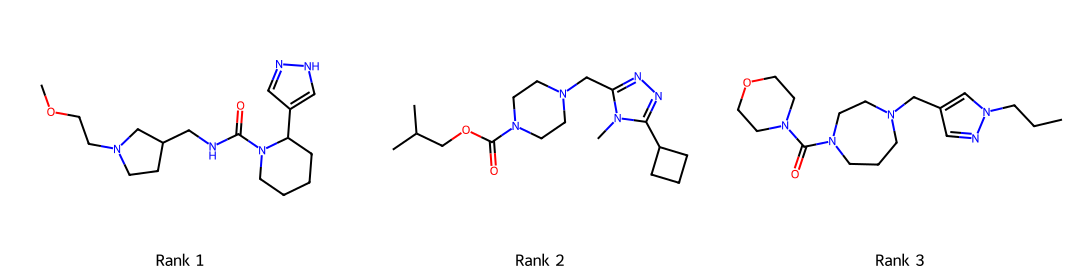

In [33]:
# Choose a gate-eligible query if one exists; otherwise show the weakest library match.
example_ids = list(te.molecule_id.drop_duplicates())
eligible_ids = [m for m in example_ids if BASE[m][2] < LIB_TAU and PC.get(m, {}).get('pc')]
example_mid = eligible_ids[0] if eligible_ids else min(example_ids, key=lambda m: BASE[m][2])
example_query = te[te.molecule_id.eq(example_mid)]
main_smiles, main_keys, example_lib = BASE[example_mid]
proposal = PC.get(example_mid, {})
pc_smiles = proposal.get('pc', [])
pc_keys = proposal.get('pc_keys', [])
best_pool = proposal.get('best_pool_fz', float('nan'))
delta = (proposal['pc_fz'][0] - best_pool) if pc_smiles and np.isfinite(best_pool) else float('nan')
branch = ('main: no PubChem proposals' if not pc_smiles else
          'main: strong measured-library match' if example_lib >= LIB_TAU else
          'PubChem at 2/4/6/8/10' if delta > REL_TH else 'PubChem at 4/8/12/16/20')
display(Markdown(
    f'**{example_mid}** · {len(example_query)} measured view(s) · '
    f'neutral mass {np.nanmedian(example_query.nm):.4f} Da · '
    f'library match {example_lib:.3f} · '
    f'PubChem score difference {delta:.1f} · **{branch}**'
))
final_smiles = sub.set_index('molecule_id').at[example_mid, 'smiles'].split(';')
main_key_set = set(main_keys)
example_rows = []
for rank, smiles in enumerate(final_smiles[:5], 1):
    key = chem.score_key(smiles)
    example_rows.append({'Rank': rank, 'Channel': 'main' if key in main_key_set else 'PubChem',
                         'Connectivity key': key, 'SMILES': smiles})
display(pd.DataFrame(example_rows))
drawn = [_Chem.MolFromSmiles(s) for s in final_smiles[:3]]
if all(m is not None for m in drawn):
    display(Draw.MolsToGridImage(drawn, molsPerRow=3, subImgSize=(360, 280), useSVG=True,
                                 legends=[f'Rank {i}' for i in range(1, len(drawn) + 1)]))

*Figure 17. The top three of the five channel-tagged proposals in the adjacent table, for one unlabelled visible-format molecule. The drawings show the proposed molecular graphs; their order is a prediction, not evidence that any proposal is correct.*

## 13. A practical next experiment

Section 11 separates candidate presence from ranking. The next experiment should test which current component adds answers and which only reorders them, on a newly frozen scorer-identity-disjoint group set.

1. **Freeze identities and inputs.** From the mounted training file, assign all spectra of one scorer key to one side. Record input and role hashes. Remove held-out spectra from fitting and measured-reference indices; decide in advance whether the test is structure-only (candidate retained) or novel-training-structure (internal candidate removed).
2. **Measure coverage before fitting.** With the current train/COCONUT pool, derivative generator and separate PubChem tier, record whether each held-out truth appears in the *actual* candidate window. Report coverage $C$, counts by source and how many correct answers a new source adds or displaces. If $C$ is near zero, test another attributable source or a constrained structure generator first.
3. **Retrain only on permitted identities.** Fit the fingerprint model and construct candidate simulations inside the fit fold; rebuild the mass-compatible negatives and all feature rows. Then fit the four-booster candidate ranker on fit identities, select checkpoints and gate choices on an inner fold, and keep a separate outer fold unopened. The supplied v4g weights are inference artifacts, not a documented identity-disjoint retraining recipe; record the split, feature schema, checkpoints and hashes for any new fit.
4. **Compare ranking on one fixed search space.** For candidates that are present, compare the main ranker, the separate PubChem proposals, ICEBERG reranking and the full gated list on the same held-out molecules and frozen source pools. Then report top-1, top-25 and MRR@25 over *all* held-out molecules, including zero-coverage ones, split by instrument, adduct and polarity. Freeze any new choice before opening its separate audit.

[CSI:FingerID](https://www.pnas.org/doi/10.1073/pnas.1509788112) motivates a better spectrum-to-fingerprint representation; [MS2Query](https://www.nature.com/articles/s41467-023-37446-4) suggests analogue evidence when candidates exist; [MassSpecGym](https://github.com/pluskal-lab/MassSpecGym) offers harder evaluation settings. Sections 14–16 survey broader chemistry and physics ideas, not required inputs for this immediate experiment.

## 14. Further reading: data and representations

An external resource is valuable when it adds useful chemistry or representations beyond what the competition corpus already contains. Download size alone is a poor guide.

| Resource | What it can add | What must be checked |
|---|---|---|
| [Enveda-180](https://github.com/enveda/enveda-180) | acquisition context and reproducible processing | Its MS/MS data are already a major training source; extra modalities are useful only if the inference task supplies a compatible signal. |
| [GNPS libraries](https://ccms-ucsd.github.io/GNPSDocumentation/browselibraries/), [MassBank releases](https://github.com/MassBank/MassBank-data), [MoNA](https://massbank.us/) | additional experimental references or analogue coverage | Audit exact spectra, scored connectivities, source terms, and experimental versus inferred annotations. |
| [PubChem](https://pubchem.ncbi.nlm.nih.gov/docs/downloads) | a broad structure-only candidate universe | A database entry supplies a candidate, not a measured spectrum or evidence that it is present in the sample. |
| [COCONUT 2.0](https://doi.org/10.1093/nar/gkae1063) | natural-product structures with downloadable formulae and monoisotopic masses | Standardise structures, retain provenance, and measure additional answer coverage after deduplication. |
| [ChEBI](https://www.ebi.ac.uk/chebi/downloads), [NPAtlas](https://www.npatlas.org/), [HMDB](https://www.hmdb.ca/downloads) | focused biological chemistry and annotations | Check each database’s organism and compound scope, licensing, and overlap with the existing candidate pool. |
| [DreaMS / GeMS](https://www.nature.com/articles/s41587-025-02663-3) | pretrained spectrum representations | Its pretraining data and acquisition settings differ from the hidden task; measure transfer by ion mode, mass, and instrument. |
| [MassSpecGym](https://github.com/pluskal-lab/MassSpecGym) | benchmark code and demanding generalisation protocols | Its spectra can overlap the competition's source libraries; benchmark reuse is not automatically new training data. |
| [MassIVE](https://massive.ucsd.edu/) | unlabelled experimental spectra for pretraining | Most records do not supply confirmed structure labels; preprocessing and overlap control remain necessary. |

The current PubChem tier expands the structure pool beyond measured references, while ICEBERG tests a bounded set of same-formula isomers with predicted spectra. The next challenge is to measure which component improves coverage or ordering on genuinely held-out chemistry. Report **coverage before ranking** and **MRR after ranking** so the source of an improvement is visible.

Attach all adopted resources for offline inference and record their source, version, licence, preprocessing, and overlap policy. The resource map above is a literature guide; it does not imply that every listed dataset or model is loaded by this notebook.

### Longer-term direction: molecular geometry and quantum data

Open molecular-geometry datasets can help pretrain conformer and energy models, but they do not provide experimental MS/MS peaks for this task. [GEOM](https://www.nature.com/articles/s41597-022-01288-4) offers conformers and energies; [ANI-1x/ANI-1ccx](https://www.nature.com/articles/s41597-020-0473-z) develops learned potentials; [PubChemQC](https://pubs.acs.org/doi/10.1021/acs.jcim.7b00083) offers quantum-chemical structures. A practical first use here would be a small test of fragment plausibility or protonation on ambiguous candidates, with the candidate mass and adduct matched to experimental spectra. These are further reading, not inputs to this notebook.

The geometry resources above supply structures and energies. Section 15 considers the additional modelling needed to turn these into candidate-specific fragmentation evidence.

## 15. Further reading: selective physics

**DFT (density functional theory)** can estimate stable conformers, protonation/protomer energetics, bond dissociation tendencies, charges, and candidate fragment energies. **AIMD (ab initio molecular dynamics)** or semiempirical quantum-chemical MD can simulate fragmentation trajectories after energetic activation.

[QCxMS](https://pubs.acs.org/doi/10.1021/jasms.1c00098) extends QCEIMS (Quantum Chemistry Electron Ionisation Mass Spectrometry) to CID spectra by modelling collisions and fragmentation with on-the-fly molecular dynamics and the semiempirical GFN2-xTB Hamiltonian. A 2025 [pilot study](https://pubmed.ncbi.nlm.nih.gov/40876445/) generated CID-MS/MS for 121 Blood Exposome Database compounds, demonstrating feasibility but also the need for parameter/protomer selection and experimental calibration. [CIDMD](https://pmc.ncbi.nlm.nih.gov/articles/PMC11492810/) is another ab initio CID approach evaluated on a small set of low-mass compounds.

For this competition, full DFT/MD is unlikely to be the primary engine:

- it is a **forward** calculation for a proposed structure, so it does not remove the need to generate candidates;
- a single molecule has multiple conformers, protonation sites, adduct geometries, and collision trajectories;
- simulating thousands or millions of PubChem candidates for the roughly 400 molecules in the released format-example test would be hard to fit within the competition's [9-hour offline inference limit](https://www.kaggle.com/competitions/enveda-CASMI26-molecule-id-mass-spectra/rules); the hidden set may have a different size;
- reproducing instrument- and energy-dependent intensities is substantially harder than predicting plausible fragment masses;
- large, flexible molecules can lie beyond the easy regime of published small-molecule quantum-dynamics demonstrations.

The highest-value physics use is selective: formula/adduct consistency checks, protomer ranking, fragment plausibility for a small top candidate set, or generating targeted training examples in sparse chemical classes. Fast semiempirical methods or learned interatomic potentials are more realistic than routine high-level DFT. Any simulated score must be calibrated against held-out experimental timsTOF spectra.

[ANI active learning](https://doi.org/10.1063/1.5023802) illustrates how expensive calculations can focus on uncertain examples. Disagreement between rankers alone is not a calibrated uncertainty estimate; a selective experiment still needs held-out validation.


## 16. Historical challenge context

CASMI (Critical Assessment of Small Molecule Identification) began as a blinded comparison of identification workflows. The [founding overview](https://pmc.ncbi.nlm.nih.gov/articles/PMC3901296/) and [CASMI 2013 analysis](https://pmc.ncbi.nlm.nih.gov/articles/PMC4337369/) show why successful identification involves more than matching peak lists: formula inference, database coverage, data quality, and chemical context all matter.

The [CASMI 2016 automated-methods analysis](https://pmc.ncbi.nlm.nih.gov/articles/PMC5368104/) compared chemistry-based and learned approaches under different information conditions. Its useful lesson is complementarity: structural and metadata evidence can change the ranking produced by a spectrum-only method. The [CASMI 2022 results](https://www.fiehnlab.ucdavis.edu/casmi/casmi-2022-results) likewise separate tasks such as adduct, formula, class, and structure assignment.

These earlier challenges motivate a staged pipeline, but their scores cannot be transferred to CASMI 2026. Candidate databases, acquisition conditions, test chemistry, and evaluation rules differ. Use their methods as hypotheses to test on a reproducible contemporary validation split.

## 17. Sources and reproducibility

The [competition overview](https://www.kaggle.com/competitions/enveda-CASMI26-molecule-id-mass-spectra), [data description](https://www.kaggle.com/competitions/enveda-CASMI26-molecule-id-mass-spectra/data) and [rules](https://www.kaggle.com/competitions/enveda-CASMI26-molecule-id-mass-spectra/rules) define the prediction task, data roles and offline inference limit. The current model follows [Ahmed Berat Özer's public v4g notebook](https://www.kaggle.com/code/ahmedberatozer/casmi26-v4g-inference), whose notebook code is marked Apache 2.0. Its five input packages are preserved in [our attributed resource fork](https://www.kaggle.com/datasets/dmitriigluzdov/casmi26-attributed-v4g-reproduction-assets); its README maps every file to the upstream Kaggle dataset and explains the distinct terms for competition-derived data, COCONUT, PubChem, DreaMS and ICEBERG. The Kaggle `Other` label and source notices remain in force for those assets.

The attached [Open Model and Candidate Resources](https://www.kaggle.com/datasets/dmitriigluzdov/casmi26-open-model-and-candidate-resources) supplies the pinned main RDKit wheel. The older [FPNet and Candidate Catalogues](https://www.kaggle.com/datasets/dmitriigluzdov/casmi26-open-fpnet-and-candidate-catalogues) and [source-held-out validation audit](https://www.kaggle.com/datasets/dmitriigluzdov/casmi26-source-held-out-validation-audit) document previous experiments in Appendix A; neither is mounted for current inference.

For scientific context, [CSI:FingerID](https://www.pnas.org/doi/10.1073/pnas.1509788112) motivates spectrum-to-fingerprint matching, [spectral entropy](https://doi.org/10.1038/s41592-021-01331-z) helps compare measured spectra, [MS2Query](https://www.nature.com/articles/s41467-023-37446-4) motivates analogue evidence and [MassSpecGym](https://github.com/pluskal-lab/MassSpecGym) offers harder generalisation tests. The [ms-pred / ICEBERG code](https://github.com/coleygroup/ms-pred) supplies the bounded forward-model component. Sections 14–16 are further reading on additional data, physics and past challenges.

The executable cells verify the asset manifest, record train/test/submission hashes, component counts and runtime, and check the visible submission schema. The worked example in Section 12 shows how the two channels combine on one unlabelled molecule. A leaderboard score belongs to the exact version that Kaggle ran and accepted.

## Appendix A. What earlier versions taught us

Earlier versions of this **same notebook** tested a two-ranker model with PubChemLite proposals, then added ChEMBL or ChEBI candidate catalogues. Those recipes used different training snapshots and search rules. They remain available in the notebook's version history and in the [source-held-out validation audit](https://www.kaggle.com/datasets/dmitriigluzdov/casmi26-source-held-out-validation-audit). The current version uses the train/COCONUT pool, a separately scored PubChem tier and ICEBERG instead.

| Earlier completed submission | Change | Public score |
|---|---|---:|
| Version 17 | v4g main model + PubChem + ICEBERG | **0.366** |
| Version 13 | Two-ranker blend plus PubChemLite | 0.341 |
| Version 14 | Primary branch order plus the same proposal rule | 0.326 |

On a selected local set of 48 GNPS and 48 Enveda molecules, the primary order had looked better on some covered answers. That local advantage did not transfer: version 14's official score was lower (0.326 versus version 13's 0.341). That difference is why Section 11 separates candidate presence from rank and Section 13 calls for a fresh identity-disjoint outer test. It cannot be explained from hidden per-molecule labels, which are unavailable.

One more historical check illustrates why adding a catalogue is not enough. On a selected 48-molecule Enveda slice, early ChEMBL insertions pushed existing correct candidates down: MRR@25 moved from 0.1837 to 0.1534. Keeping the original first 20 positions and appending new candidates gave 0.1847 on that **same development slice**. These numbers compare an older recipe on a selected subset; they are not accuracy estimates for the method in Section 10. The practical lesson is to measure both newly covered answers and displaced answers before adopting a larger pool.